# M5 forecasting II: a hierarchical count state space model with `numpyro_forecast`

The M5 competition asks for probabilistic forecasts of the daily unit sales of 3,049 Walmart items in 10 stores of three states, 28 days ahead. That is 30,490 item-store series, and the score adds them up to 42,840 series over a 12-level hierarchy: the total, the states, the stores, the categories, the departments, the items and their crossings. Many item series are small counts with long runs of zero days, while the aggregates are smooth, so a model has to get both the level of each item and the common movements of the stores right.

The [M5 baselines notebook](m5_forecasting.html) ports the three models of the [Pyro M5 Starter Kit](https://github.com/pyro-ppl/Pyro-M5-Starter-Kit) to `numpyro_forecast` and scores them with the **weighted scaled CRPS** (WS-CRPS) over the whole hierarchy. On the evaluation window the top-down model is the best of the three:

- top-down: 0.569;
- middle-out: 0.634;
- bottom-up: 0.728.

This notebook asks whether a single **hierarchical count state space model** of every item in every store, fitted with minibatch SVI, beats the top-down model. The model has the following components, all partially pooled across the hierarchy:

- a negative binomial likelihood with item-level dispersion;
- an item intercept centered on the level of the series at the forecast origin;
- a random walk of the item level over 28-day blocks, anchored at the origin;
- daily store shocks that sum to zero within every week;
- zero-sum weekday and day-of-month effects per store-department, with zero-sum item weekday deviations;
- SNAP, calendar events and yearly seasonality.

We fit the model, look at its posterior and its forecasts, score both models on the evaluation window of the competition, and repeat the comparison on three earlier windows with a backtest. Every score is computed at every level of the hierarchy, with the calibration of the forecast bands next to it. The baselines notebook describes the data loader, the hierarchy, the scoring functions and the baseline in detail; here we only summarize them.

## Prepare notebook

In [1]:
import warnings

# preliz warns at import time when PyMC is not installed; this example does not use PyMC.
warnings.filterwarnings("ignore", message="PyMC not installed", category=UserWarning)

from functools import partial
from time import perf_counter

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import optax
import polars as pl
import preliz as pz
import scipy.sparse as sp
import xarray as xr
from IPython.display import display
from jax import random
from numpyro.infer import SVI, Predictive, Trace_ELBO, init_to_median
from numpyro.infer.autoguide import AutoNormal
from numpyro.infer.svi import SVIRunResult

from numpyro_forecast import (
    Horizon,
    backtest,
    draw_posterior,
    evaluate_forecast,
    forecast,
    predict,
    predict_in_sample,
    predictions_to_datatree,
    results_to_dataframe,
)
from numpyro_forecast.datasets import load_m5
from numpyro_forecast.features import fourier_features
from numpyro_forecast.metrics import crps_empirical
from numpyro_forecast.typing import Array, ForecastFn, ForecastModel, Metric

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"
numpyro.set_host_device_count(n=4)
rng_key = random.PRNGKey(seed=42)

# The observation site sits under the subsampled `series` plate while its time axis is not
# declared as a plate (`predict` splits it into the observed prefix and the forecast suffix);
# numpyro's model validation warns about the undeclared batch dimension at every trace. The
# baselines notebook explains why the warning is harmless.
warnings.filterwarnings("ignore", message="Missing a plate statement for batch dimension -2")
# The second `plot_lm` call of an overlay reuses the alpha of the first one.
warnings.filterwarnings("ignore", message="When multiple credible intervals are plotted")

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## Read data

`load_m5()` downloads the [Nixtla mirror](https://github.com/Nixtla/m5-forecasts) of the competition files once and returns:

- the daily sales of every series over the training period (`d_1` to `d_1941`), followed by the 28 evaluation days (`d_1942` to `d_1969`);
- the weekly shelf price of every series, repeated over its days (`NaN` when the item is not on the shelf);
- the series identifiers, the calendar and the official evaluation weights.

The [baselines notebook](m5_forecasting.html) explores these files in detail, so here we keep only what the model needs. The calendar has two event columns. The second one holds only five events, but one of them (Father's Day 2016) falls inside the evaluation window, so we index both.

In [2]:
m5 = load_m5()

N_DAYS_TRAIN = 1_941
HORIZON = 28
N_DAYS = N_DAYS_TRAIN + HORIZON
sales = m5.sales
price = m5.price
keys_df = m5.keys
n_series = sales.shape[1]


def is_christmas() -> pl.Expr:
    """Flag December 25, the one day a year every Walmart store is closed."""
    return pl.col("date").dt.month().eq(pl.lit(12)).and_(pl.col("date").dt.day().eq(pl.lit(25)))


def day_of_week_index() -> pl.Expr:
    """Index the weekday from 0 (Monday) to 6 (Sunday)."""
    return pl.col("date").dt.weekday().sub(pl.lit(1))


def event_index(column: str, names: list[str]) -> pl.Expr:
    """Index an event column by its position in ``names``, 0 when there is no event."""
    return pl.col(column).replace_strict(names, list(range(1, len(names) + 1)), default=0)


event_names = sorted(
    set(m5.calendar["event_name_1"].drop_nulls().to_list())
    | set(m5.calendar["event_name_2"].drop_nulls().to_list())
)
calendar_df = (
    m5.calendar.lazy()
    .with_row_index("t")
    .with_columns(
        christmas=is_christmas().cast(pl.Float32),
        dow=day_of_week_index(),
        dom=pl.col("date").dt.day().sub(pl.lit(1)),
        event_1=event_index("event_name_1", event_names),
        event_2=event_index("event_name_2", event_names),
    )
    .select(
        "t",
        "date",
        "dow",
        "dom",
        "christmas",
        "event_1",
        "event_2",
        "snap_CA",
        "snap_TX",
        "snap_WI",
    )
    .collect(engine="streaming")
)

print(f"{n_series} series over {N_DAYS} days, {len(event_names)} event names")

m5.calendar.filter(pl.col("event_name_2").is_not_null()).select(
    "date", "event_name_1", "event_name_2"
)

30490 series over 1969 days, 30 event names


date,event_name_1,event_name_2
date,str,str
2011-04-24,"""OrthodoxEaster""","""Easter"""
2013-05-05,"""OrthodoxEaster""","""Cinco De Mayo"""
2014-04-20,"""Easter""","""OrthodoxEaster"""
2014-06-15,"""NBAFinalsEnd""","""Father's day"""
2016-06-19,"""NBAFinalsEnd""","""Father's day"""


### The hierarchy

The competition scores 42,840 series: the 30,490 item-store series (level 12) and their sums over the 11 coarser groupings. We give every series a label and a dense group id per level, and we turn them into a sparse **summation matrix** of shape `(30,490, 42,840)`. One product with this matrix aggregates any array of bottom-level values, data or forecast draws, to every level. The store, department and store-department ids of every series also index the pooled parameters of the model.

In [3]:
LEVELS: dict[str, list[str]] = {
    "Level1": [],
    "Level2": ["state_id"],
    "Level3": ["store_id"],
    "Level4": ["cat_id"],
    "Level5": ["dept_id"],
    "Level6": ["state_id", "cat_id"],
    "Level7": ["state_id", "dept_id"],
    "Level8": ["store_id", "cat_id"],
    "Level9": ["store_id", "dept_id"],
    "Level10": ["item_id"],
    "Level11": ["state_id", "item_id"],
    "Level12": ["item_id", "store_id"],
}


def level_label(columns: list[str]) -> pl.Expr:
    """Label of the aggregate a series belongs to at one level, ``Agg_Level_1/Agg_Level_2``."""
    parts = [pl.col(column) for column in columns] or [pl.lit("Total")]
    if len(parts) == 1:
        parts.append(pl.lit("X"))
    return pl.concat_str(parts, separator="/")


def group_id(label: str) -> pl.Expr:
    """Dense 0-based id of the aggregate named by ``label``, in sorted label order."""
    return pl.col(label).rank("dense").cast(pl.Int64).sub(pl.lit(1))


def add_level_ids(keys: pl.DataFrame) -> pl.DataFrame:
    """Add one label and one group id column per M5 level."""
    return keys.with_columns(
        **{f"{level}_label": level_label(columns) for level, columns in LEVELS.items()}
    ).with_columns(**{level: group_id(f"{level}_label") for level in LEVELS})


def aggregation_matrix(
    hierarchy: pl.DataFrame,
) -> tuple[sp.csr_matrix, list[str], dict[str, slice]]:
    """Sparse ``(n_series, n_aggregates)`` sum matrix over the 12 levels, with labels and slices."""
    rows, cols, labels, slices = [], [], [], {}
    offset = 0

    for level in LEVELS:
        rows.append(np.arange(hierarchy.height))
        cols.append(offset + hierarchy[level].to_numpy())
        level_labels = (
            hierarchy.select(f"{level}_label", level)
            .unique()
            .sort(level)[f"{level}_label"]
            .to_list()
        )
        labels += [f"{level}/{label}" for label in level_labels]
        slices[level] = slice(offset, offset + len(level_labels))
        offset += len(level_labels)

    values = np.ones(hierarchy.height * len(LEVELS), dtype=np.float32)
    matrix = sp.csr_matrix(
        (values, (np.concatenate(rows), np.concatenate(cols))), shape=(hierarchy.height, offset)
    )

    return matrix, labels, slices


hierarchy_df = keys_df.pipe(add_level_ids)
agg_matrix, agg_labels, level_slices = aggregation_matrix(hierarchy_df)
sales_agg = sales @ agg_matrix

# Labels of the stores, departments and store-departments, in the order of their group ids.
store_ids = [
    label.removeprefix("Level3/").removesuffix("/X")
    for label in agg_labels[level_slices["Level3"]]
]
dept_ids = [
    label.removeprefix("Level5/").removesuffix("/X")
    for label in agg_labels[level_slices["Level5"]]
]
group_ids = [label.removeprefix("Level9/") for label in agg_labels[level_slices["Level9"]]]
N_STORES, N_DEPTS, N_GROUPS = len(store_ids), len(dept_ids), len(group_ids)

# The group ids of every series index the pooled parameters inside the model.
state_index = hierarchy_df["Level2"].to_numpy()
store_index = jnp.asarray(hierarchy_df["Level3"].to_numpy(), dtype=jnp.int32)
dept_index = jnp.asarray(hierarchy_df["Level5"].to_numpy(), dtype=jnp.int32)
group_index = jnp.asarray(hierarchy_df["Level9"].to_numpy(), dtype=jnp.int32)

print(
    f"aggregation matrix {agg_matrix.shape}: {N_STORES} stores, {N_DEPTS} departments, "
    f"{N_GROUPS} store-departments"
)

aggregation matrix (30490, 42840): 10 stores, 7 departments, 70 store-departments


## Scoring at every level

We use the score of the baselines notebook. For a series $s$ at level $\ell$ of the hierarchy, let

- $c_s$ be the mean CRPS of its 28-day forecast;
- $w_s$ be its **weight**: its share of the dollar sales of level $\ell$ over the 28 days before the forecast origin;
- $\sigma_s$ be its **scale**: the mean absolute day-to-day change of its training series after its first nonzero value.

The weighted scaled CRPS averages the weighted and scaled CRPS of the 12 levels:

$$
\text{WS-CRPS} = \frac{1}{12} \sum_{\ell=1}^{12} \sum_{s \in \ell} w_s \frac{c_s}{\sigma_s}.
$$

The scale makes the CRPS of a large series comparable with the CRPS of a small one. The weights of every level add up to one, so the total, a single series, counts as much as the 30,490 items together.

A CRPS alone does not tell whether a forecast is sharp or only narrow, so we also report four **coverage** metrics: the share of series-days inside the central $94\%$ interval of the draws at levels 1, 3, 9 and 12. The model selection in *Why these components* reads both scores; we implement them in *The evaluation window*, where the notebook scores its first forecast.

## Features

The model reads two kinds of inputs:

- a per-series **covariate tensor** with two channels and time at axis $-2$: the day index, through which the model looks up the calendar tables, and the `saled` flag described below;
- the **calendar tables**, one row per day: the weekday, the day of the month, the SNAP flag of each state, the two event indices and four yearly Fourier harmonics. They stay outside the tensor so that a minibatch of series does not have to carry them.

The shelf price is not a feature. A department price elasticity was tried during development and did not change the score (the model selection below shows it), and a per-item elasticity cannot be estimated for the many items whose price never moves. The price still tells when an item is on the shelf: the **`saled` flag** is 1 when the item has a listed price and the store is open (every store is closed on Christmas), and 0 otherwise. The model multiplies its mean by this flag, as the kit's bottom-up model does, so that an item has no expected sales on the days it is not sold.

In [4]:
# (days,): 1 on December 25, when every store is closed.
christmas = calendar_df["christmas"].to_numpy()[:N_DAYS]

# (days, series): 1 when the item has a listed price and the store is open, 0 otherwise.
saled = (~np.isnan(price)).astype(np.float32) * (1.0 - christmas[:, None])

The covariate tensor has shape `(channel, day, series)`: channel 0 is the day index (the same for every series) and channel 1 is the `saled` flag of every series-day.

In [5]:
covariates_np = np.empty((2, N_DAYS, n_series), dtype=np.float32)
covariates_np[0] = np.arange(N_DAYS, dtype=np.float32)[:, None]  # the day index
covariates_np[1] = saled  # price listed and not Christmas
covariates = jnp.asarray(covariates_np)
del covariates_np

print(f"covariates {covariates.shape} (channel, day, series), {covariates.nbytes / 1e9:.2f} GB")

covariates (2, 1969, 30490) (channel, day, series), 0.48 GB


The model indexes the calendar tables with the day channel. The day of the month runs from 0 to 30, and an event index is 0 for "no event" and otherwise the position of the event name. `state_of_store` maps every store to its state, so that the model can pick the SNAP flag of the store of a series.

In [6]:
dow_table = jnp.asarray(calendar_df["dow"].to_numpy()[:N_DAYS], dtype=jnp.int32)  # (days,)
dom_table = jnp.asarray(calendar_df["dom"].to_numpy()[:N_DAYS], dtype=jnp.int32)  # (days,) 0..30
snap_table = jnp.asarray(  # (days, state)
    calendar_df.select("snap_CA", "snap_TX", "snap_WI").to_numpy()[:N_DAYS], dtype=jnp.float32
)
event_tables = (  # two (days,) event indices, 0 for no event
    jnp.asarray(calendar_df["event_1"].to_numpy()[:N_DAYS], dtype=jnp.int32),
    jnp.asarray(calendar_df["event_2"].to_numpy()[:N_DAYS], dtype=jnp.int32),
)

N_HARMONICS = 4
fourier_table = jnp.asarray(  # (days, 2 * harmonics)
    fourier_features(N_DAYS, 365.25, N_HARMONICS), dtype=jnp.float32
)

state_of_store = jnp.asarray(  # (store,): the state of every store, for the SNAP flag
    [state_index[np.argmax(np.asarray(store_index) == s)] for s in range(N_STORES)],
    dtype=jnp.int32,
)

The training counts are the sales times the `saled` flag. The model puts its mean at a floor on the days without a listed price and on Christmas, so we set the few nonzero sales recorded on such days to zero instead of leaving them for the likelihood to explain.

In [7]:
n_zeroed = int((sales * (1 - saled) > 0).sum())

print(f"{n_zeroed} nonzero sales on unlisted or closed days are set to 0 in the training counts")

60 nonzero sales on unlisted or closed days are set to 0 in the training counts


## The model

Let $i$ index the item-store series, with store $r(i)$, department $d(i)$ and store-department $j(i)$ (70 groups). For day $t$, let $w(t)$ be the weekday, $m(t)$ the day of the month, $b(t)$ the 28-day block (counted so that the horizon is one whole block), $e_1(t)$ and $e_2(t)$ the two event indices and $\mathbf{f}_t$ the yearly Fourier terms. The model is

$$
\begin{align*}
y_{i,t} &\sim \text{NegativeBinomial2}\big(\text{saled}_{i,t}\, e^{\eta_{i,t}},\ \phi_i\big), \qquad \log \phi_i \sim \text{Normal}(\log \phi_{j(i)}, \tau_{d(i)}), \\
\eta_{i,t} &= \log \bar y_i + a_{j(i)} + \alpha_i + u_{i,b(t)} + \epsilon_{r(i),t} + s_{j(i),w(t)} + \tilde s_{i,w(t)} + \delta_{j(i),m(t)} + \beta_{j(i)}\,\text{snap}_{r(i),t} + \boldsymbol{\theta}_{d(i)}^\top \mathbf{f}_t + \gamma_{d(i),e_1(t)} + \gamma_{d(i),e_2(t)}.
\end{align*}
$$

The terms of the log mean $\eta_{i,t}$ are:

- **Level at the origin.** $\bar y_i$ is the mean sales of the series over its listed days of the last 28 training days (with a fallback to the last year, then to a floor). The item deviation $\alpha_i \sim \text{Normal}(0, \sigma^{\alpha}_{d(i)})$ is partially pooled by department. The store-department intercept $a_j$ shifts a whole group at once when the origin level is off for all its items, for example by the value of the yearly curve at the origin. The walk below is zero on the last training block, so $\log \bar y_i + a_{j(i)} + \alpha_i$ is the log level at the forecast origin: the share heuristic of the kit becomes the prior center of a Bayesian item level.
- **Item block walk** $u_{i,b}$: a random walk over the last 13 blocks of 28 days, with a department-level innovation scale $\sigma^{u}_{d}$. The walk is **end-anchored**: it is zero on the last training block, and each earlier block is minus the sum of the innovations that follow it. The horizon block adds one fresh innovation. This is the local level of a state space model, at the time resolution that a single item series can support.
- **Weekly store shocks** $\epsilon_{r,t}$: daily shocks shared by all items of a store, which sum to zero within each week (`ZeroSumNormal` over the seven days, with the weeks counted back from the origin), with a store-level scale $\sigma^{\epsilon}_r$. A week that sums to zero cannot absorb a change of level, so the shocks carry only the common day-to-day variation of a store. Over the horizon, fresh weeks give the aggregates correlated uncertainty.
- **Weekday**: `ZeroSumNormal` effects $s_{j,\cdot}$ per store-department and zero-sum item deviations $\tilde s_{i,\cdot} = \sigma^{s}_{d(i)} z_i$ with $z_i \sim \text{ZeroSumNormal}(1)$ (the distribution does not take a per-item scale).
- **Day of the month**: `ZeroSumNormal` effects $\delta_{j,\cdot}$ per store-department over the 31 days of the month. This is the pay-cycle pattern that the kit's top-down model carries as 31 dummies.
- **SNAP, events and yearly seasonality**: a SNAP effect $\beta_j$ per store-department; one effect $\gamma_{d,e}$ per department and event name, with a shrinkage scale $\sigma^{\gamma}_d$ and zero for "no event", so that $\gamma_{d,e}$ is the lift of event $e$ over an ordinary day; four yearly harmonics with department-level weights $\boldsymbol{\theta}_d$.
- **Likelihood**: negative binomial with an item-level dispersion $\phi_i$ pooled to the store-department. The log mean is clipped at $\log 2{,}000$; no series sells more than 763 units on a day.

The SNAP days are fixed days of the month in every state: days 1 to 10 in California, and ten days among the first 15 in Texas and Wisconsin. Within a store-department, the data therefore cannot separate the SNAP effect from the day-of-month pattern on those days. Only the priors separate them: a single effect of scale 0.3 against 31 zero-sum effects of scale 0.2. For that reason the SNAP figure of *Posterior of the shared parameters* shows the sum of the two.

### Priors

The item-level parameters are partially pooled, so the priors that matter are those of the population scales and of the shared effects:

$$
\begin{align*}
\sigma^{\alpha}_d &\sim \text{HalfNormal}(0.5), & \tau_d &\sim \text{HalfNormal}(1), & \sigma^{u}_d &\sim \text{HalfNormal}(0.3), \\
\sigma^{s}_d &\sim \text{HalfNormal}(0.2), & \sigma^{\gamma}_d &\sim \text{HalfNormal}(0.3), & \sigma^{\epsilon}_r &\sim \text{HalfNormal}(0.2), \\
\log \phi_j &\sim \text{Normal}(0, 1), & s_{j,\cdot} &\sim \text{ZeroSumNormal}(0.3), & \delta_{j,\cdot} &\sim \text{ZeroSumNormal}(0.2), \\
\beta_j &\sim \text{Normal}(0, 0.3), & a_j &\sim \text{Normal}(0, 0.3), & \theta_{d,k} &\sim \text{Normal}(0, 0.3), \\
\gamma_{d,e} &\sim \text{Normal}(0, \sigma^{\gamma}_d).
\end{align*}
$$

All terms live on the log scale of the sales, where an effect of 0.3 is a factor of $e^{0.3} \approx 1.35$. In that unit the half-normal population scales are weakly informative:

- intercept deviations $\sigma^{\alpha}$, 0.5: the last-28-day level can be off by a factor of two for an item, but not routinely by ten;
- dispersion spread $\tau$, 1: item dispersions within a store-department can differ by a factor of $e$;
- block-walk innovations $\sigma^{u}$, 0.3 per 28 days;
- item weekday deviations $\sigma^{s}$, 0.2: small next to the store-department pattern they refine;
- event effects $\sigma^{\gamma}$, 0.3: a holiday can halve or double the sales of a department;
- store shocks $\sigma^{\epsilon}$, 0.2: a common daily shock of $\pm 20\%$ is large for a store total.

The shared effects have fixed scales, because the hierarchy already pools them:

- store-department intercept, weekday effects, SNAP effect and Fourier weights, 0.3;
- day-of-month effects, 0.2: a payday can lift a store-department by about $20\%$ (scales of 0.1 and 0.3 were tried during development and give the same score within 0.003);
- group log dispersion, 1 around zero, where a dispersion of 1 is a geometric Poisson-Gamma mixture with variance $\mu + \mu^2$ for a mean $\mu$.

The figure shows these priors; the prior predictive check below shows what they allow before the data.

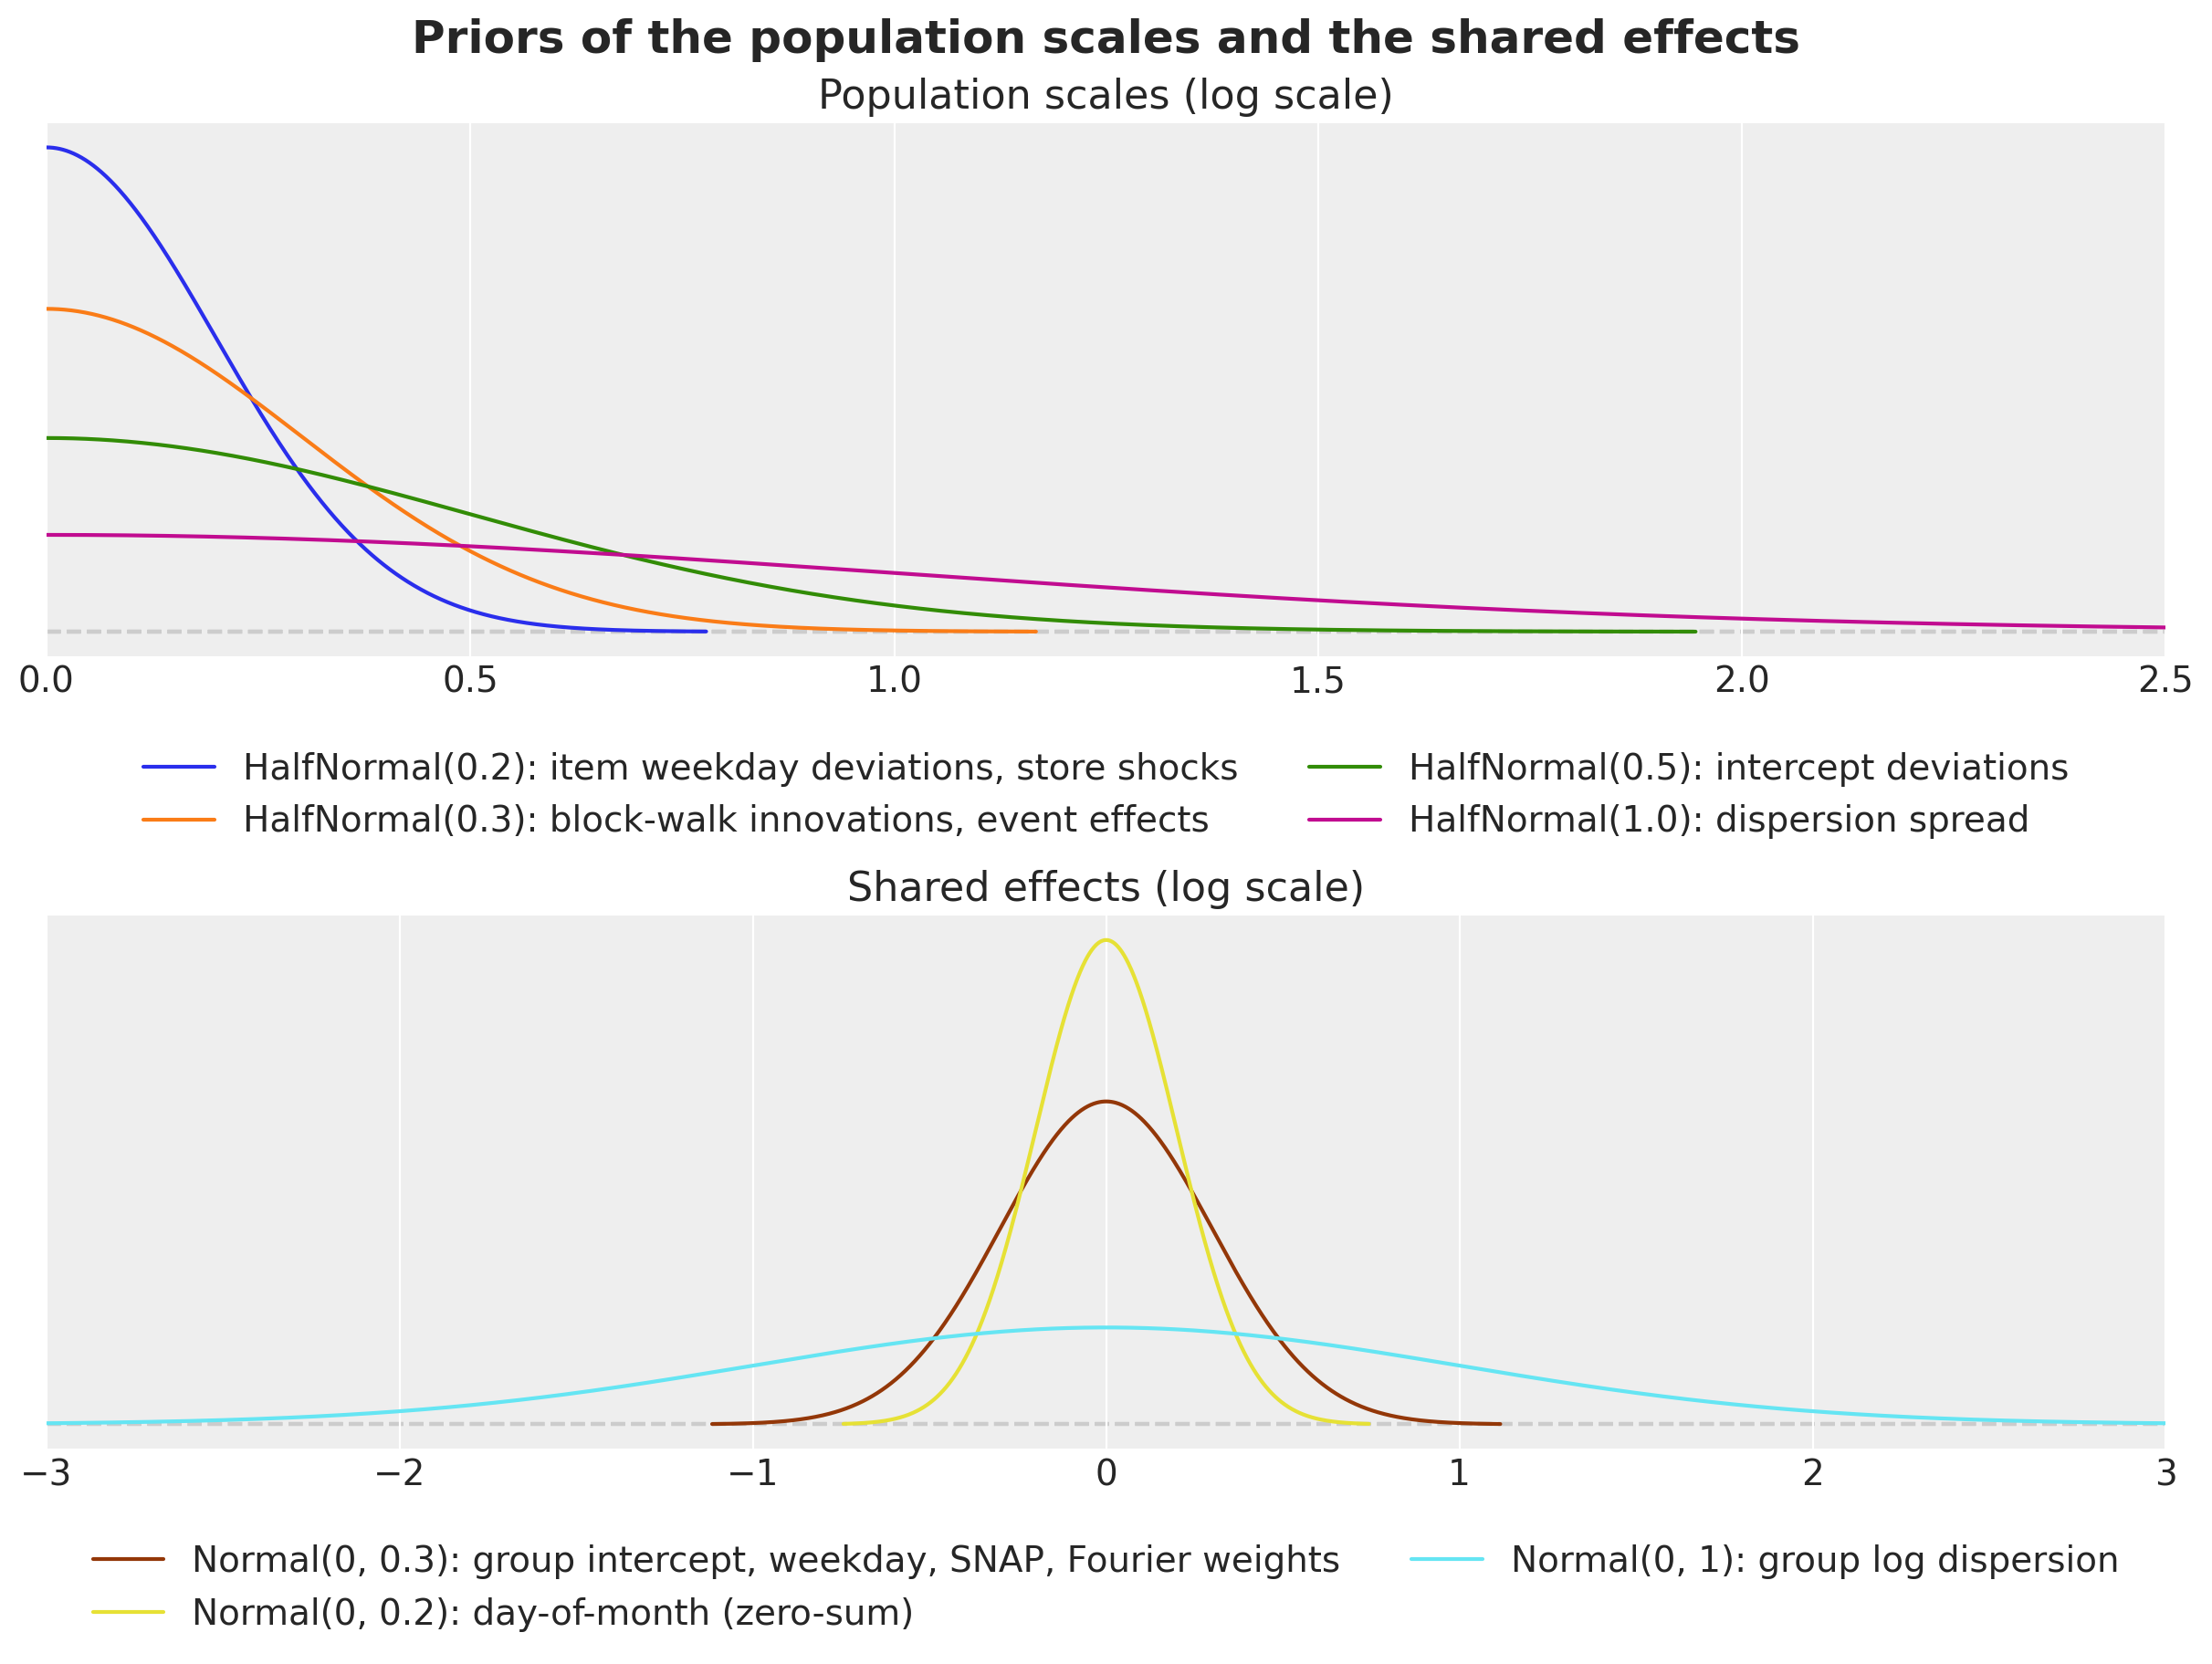

In [8]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 9), layout="constrained")

# Top: the half-normal priors of the population scales, one color per scale.
for scale, color, label in [
    (0.2, "C0", "item weekday deviations, store shocks"),
    (0.3, "C1", "block-walk innovations, event effects"),
    (0.5, "C2", "intercept deviations"),
    (1.0, "C3", "dispersion spread"),
]:
    pz.HalfNormal(scale).plot_pdf(ax=axes[0], color=color, legend=None)
    axes[0].lines[-1].set_label(f"HalfNormal({scale}): {label}")

axes[0].set(title="Population scales (log scale)", xlim=(0, 2.5))
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=2)

# Bottom: the fixed priors of the shared effects.
pz.Normal(0, 0.3).plot_pdf(ax=axes[1], color="C4", legend=None)
axes[1].lines[-1].set_label("Normal(0, 0.3): group intercept, weekday, SNAP, Fourier weights")
pz.Normal(0, 0.2).plot_pdf(ax=axes[1], color="C6", legend=None)
axes[1].lines[-1].set_label("Normal(0, 0.2): day-of-month (zero-sum)")
pz.Normal(0, 1).plot_pdf(ax=axes[1], color="C5", legend=None)
axes[1].lines[-1].set_label("Normal(0, 1): group log dispersion")
axes[1].set(title="Shared effects (log scale)", xlim=(-3, 3))
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=2)
fig.suptitle(
    "Priors of the population scales and the shared effects", fontsize=18, fontweight="bold"
);

### Why these components

We built the model one component at a time during development, and we scored every step on a **selection window**: the backtest window with forecast origin day 1,878 (250 draws). The figure shows the scores recorded in those runs; the notebook does not re-run them. The first block of bars is the cumulative **ladder**, where every row adds one component to the row above. The second block holds the alternatives that we tried and dropped, each named after the row it extends.

Two details limit the comparison between rows:

- The rows up to the weekly shocks, the price row and the shared-walk row used two parametrization details that differ from this notebook: a free "no event" effect per department instead of the store-department intercept $a_j$, and a store-shock scale prior of 0.05 instead of 0.2. They do not move the score: the shock row scores 0.514 either way.
- The two day-of-month rows were run later, with the model of this notebook and another random key stream, under which the shock row scores 0.517 instead of 0.514. The same model therefore scores between 0.514 and 0.517 on this window, and we do not read a difference below 0.005 as a gain.

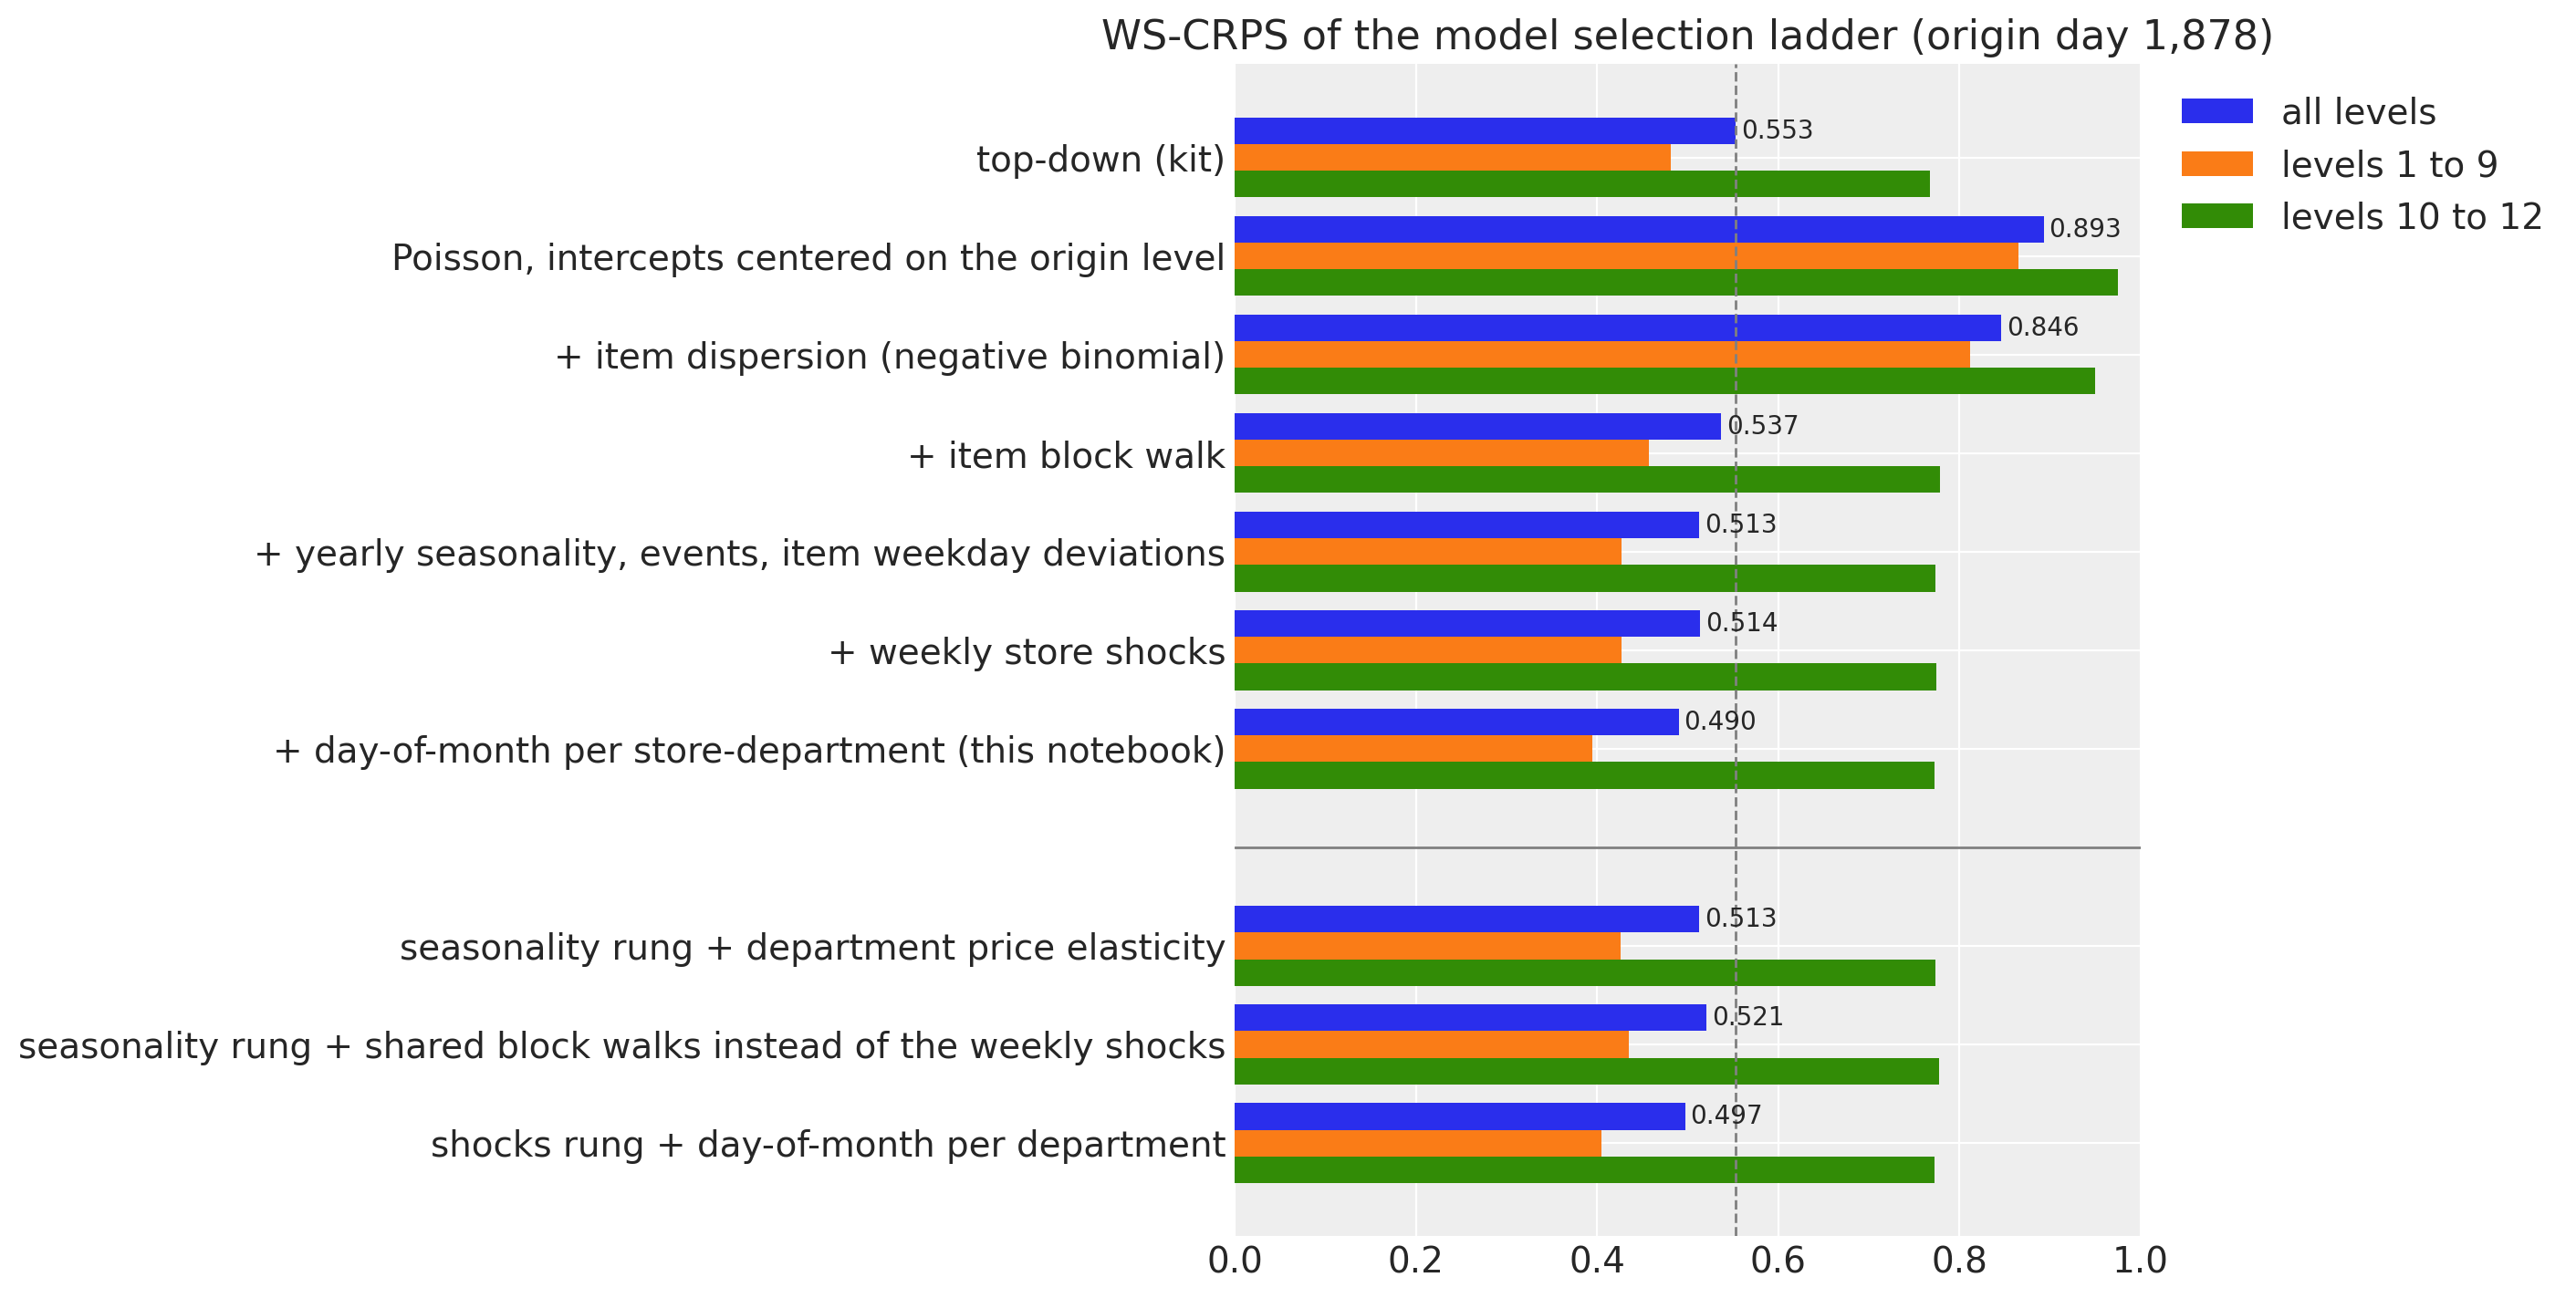

In [9]:
ladder = pl.DataFrame(
    {
        "model": [
            "top-down (kit)",
            "Poisson, intercepts centered on the origin level",
            "+ item dispersion (negative binomial)",
            "+ item block walk",
            "+ yearly seasonality, events, item weekday deviations",
            "+ weekly store shocks",
            "+ day-of-month per store-department (this notebook)",
            "seasonality rung + department price elasticity",
            "seasonality rung + shared block walks instead of the weekly shocks",
            "shocks rung + day-of-month per department",
        ],
        "all levels": [
            *[0.553, 0.893, 0.846, 0.537, 0.513, 0.514, 0.490],
            *[0.513, 0.521, 0.497],
        ],
        "levels 1 to 9": [
            *[0.481, 0.865, 0.812, 0.457, 0.427, 0.427, 0.395],
            *[0.426, 0.435, 0.405],
        ],
        "levels 10 to 12": [
            *[0.767, 0.975, 0.950, 0.778, 0.773, 0.774, 0.772],
            *[0.773, 0.777, 0.772],
        ],
    }
)
N_LADDER = 7  # the cumulative rungs; the rows after them are the alternatives

fig, ax = plt.subplots(figsize=(14, 7), layout="constrained")
y = np.arange(ladder.height) + (np.arange(ladder.height) >= N_LADDER)  # a gap after the ladder
height = 0.27

for k, column in enumerate(["all levels", "levels 1 to 9", "levels 10 to 12"]):
    bars = ax.barh(y + (k - 1) * height, ladder[column].to_numpy(), height, label=column)

    if column == "all levels":
        ax.bar_label(bars, fmt="%.3f", fontsize=10, padding=2)

ax.set_yticks(y, ladder["model"].to_list())
ax.invert_yaxis()
ax.axvline(0.553, color="gray", ls="--", lw=1)
ax.axhline(N_LADDER, color="gray", lw=1)
ax.set(title="WS-CRPS of the model selection ladder (origin day 1,878)", xlim=(0, 1.0))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0));

The figure shows four things:

- **The block walk makes the item model work.** Without a level process, a two-year intercept is the wrong level for most items, and the model loses to the baseline (the dashed line) by a wide margin. Yearly seasonality, events and item weekday deviations then improve the score by another 0.024, almost all of it at the aggregate levels.
- **Shared level processes and the price add nothing.** The price elasticity does not change the score, and shared block walks at the store and store-department level make it worse by 0.007: the level of a store over 13 blocks is already in the levels of its items.
- **The weekly shocks are for calibration.** They do not move the CRPS, but on the selection window they raise the $94\%$ coverage from 0.54 to 0.68 at level 1, from 0.70 to 0.95 at level 3 and from 0.81 to 0.90 at level 9, with the items unchanged. We keep them because the store-level bands need the right width as well as the right center; the backtest below reports the coverage on every window.
- **The day of the month was the missing calendar term.** It improves the selection window from 0.517 to 0.490, all of it at the aggregate levels (from 0.432 to 0.395 over levels 1 to 9). On the two backtest windows that were not used to select it, it improves the score from 0.511 to 0.498 (origin 1,843) and from 0.504 to 0.498 (origin 1,913). A pattern per department instead of per store-department keeps less of the gain (0.497), because the SNAP days differ by state.

### The model function

We write the model in three steps: the state space components as helpers, the model function that combines all terms, and the inputs of one forecast window.

The helpers hold the time structure of the model. They count time back from the forecast origin: in blocks of 28 days (`BLOCK`, the competition horizon) for the walk, which spans the last 13 blocks (`N_BLOCKS`, one year), and in weeks for the shocks.

- `block_index` maps every day to its block, so that the horizon is one whole block and the days older than 13 blocks share the first one.
- `block_walk` samples the 12 innovations of the training blocks under a `blocks` plate, sums them backwards so that the last training block is zero, and adds one fresh innovation for the horizon block.
- `weekly_shocks` samples one `ZeroSumNormal` week per row under a `weeks` plate. The weeks are counted back from the origin, so that the last training week ends there, and the horizon gets fresh weeks.

The block and week sites have their own plates at `dim=-2` instead of `innovations()`, because `AutoNormal` keeps one size per plate name and `predict()` already uses the daily `time` plate.

In [10]:
BLOCK = 28  # the length of a block of the item walk, the competition horizon
N_BLOCKS = 13  # one year of 28-day blocks before the origin


def block_index(h: Horizon) -> Array:
    """Index of the 28-day block of every day, counted so that the horizon is block ``N_BLOCKS``.

    The last training block ends at the forecast origin; days more than ``N_BLOCKS`` blocks
    before the origin share block 0.
    """
    t = jnp.arange(h.duration)
    return jnp.clip((t - h.t_obs) // BLOCK + N_BLOCKS, 0, N_BLOCKS)


def block_walk(name: str, scale: Array, h: Horizon) -> Array:
    """Random walk over 28-day blocks that is zero on the last training block.

    Earlier blocks are minus the innovations that follow them, so the intercepts carry the
    level at the origin; when forecasting, one more innovation moves the horizon block. The
    site is sampled under a ``blocks`` plate at ``dim=-2`` and inherits the enclosing
    (subsampled) series plate.
    """
    # (blocks - 1, series): the innovation between consecutive training blocks.
    with numpyro.plate(f"{name}_blocks", N_BLOCKS - 1, dim=-2):
        drift = numpyro.sample(name, dist.Normal(0.0, scale))

    # (blocks, series): block k is minus the sum of the innovations after it, the last is 0.
    walk = jnp.concatenate(
        [-jnp.flip(jnp.cumsum(jnp.flip(drift, 0), 0), 0), jnp.zeros_like(drift[:1])]
    )

    if h.future > 0:
        with numpyro.plate(f"{name}_future_blocks", 1, dim=-2):
            future = numpyro.sample(f"{name}_future", dist.Normal(0.0, scale))

        walk = jnp.concatenate([walk, future], axis=0)

    return walk


def weekly_shocks(name: str, scale: Array, h: Horizon, size: int) -> Array:
    """Daily shocks that sum to zero within every week, one week per row.

    A zero-sum week cannot absorb a level change, so the shocks carry only the common
    day-to-day variation of the series that share them; the horizon gets fresh weeks.
    """
    # (weeks, size, 7): one zero-sum week per row; the first week may be partial.
    n_weeks = -(-h.t_obs // 7)

    with numpyro.plate(f"{name}_weeks", n_weeks, dim=-2):
        shock = numpyro.sample(name, dist.ZeroSumNormal(1.0, event_shape=(7,)))

    if h.future > 0:
        with numpyro.plate(f"{name}_future_weeks", (h.future + 6) // 7, dim=-2):
            future = numpyro.sample(f"{name}_future", dist.ZeroSumNormal(1.0, event_shape=(7,)))

        shock = jnp.concatenate([shock, future], axis=0)

    # Scale per series, lay the weeks out as consecutive days: (weeks * 7, size).
    days = jnp.transpose(scale[:, None] * shock, (0, 2, 1)).reshape(-1, size)

    # Drop the leading days of the partial first week so that the weeks end at the origin.
    return days[n_weeks * 7 - h.t_obs :][: h.duration]

`make_model` combines the terms of *The model* into one model function of `(covariates, data)`, built on `Horizon.from_data` and `predict()`. It returns the model of a given set of series and origin levels, so that the same code serves the 30,490 series, the seven focus items and every backtest window. Two choices let it scale to 30,490 series:

- **Minibatches.** The item-level sites sit inside the `series` plate, which the guide subsamples during the fit (1,500 series per step). `numpyro.subsample` picks the matching columns of the data, the covariates, the index arrays and the origin levels, and the plate scales the log density of the minibatch by $30{,}490 / 1{,}500$.
- **A forecast-only mode.** With `forecast_only=True`, the same function evaluates the item terms over the horizon rows only and returns the horizon mean and dispersion as deterministic sites. We draw the 30,490-series forecast from these with NumPy, because the `NegativeBinomial2` sampler behind `forecast()` (a Gamma and a Poisson draw in JAX) takes minutes per window on this CPU, where NumPy takes seconds. `forecast()` itself draws the forecasts of the seven focus items.

In [11]:
MAX_LOG_MEAN = float(np.log(2_000.0))  # no series sells more than 763 units on a day
N_EVENTS = len(event_names) + 1  # the event names plus "none"


def make_model(
    level_at_origin: Array,
    *,
    store_index: Array = store_index,
    group_index: Array = group_index,
    dept_index: Array = dept_index,
    forecast_only: bool = False,
) -> ForecastModel:
    """Build the hierarchical negative binomial state space model of the M5 series.

    ``level_at_origin`` is the log of every series' mean sales over the last 28 listed
    training days: the prior center of the item intercepts, which the end-anchored walk
    makes the level at the forecast origin. With ``forecast_only=True`` the item-level terms
    are evaluated over the horizon rows only and exposed as the deterministic sites
    ``mean_future`` and ``concentration`` instead of the likelihood, which is how the
    notebook draws the 30,490-series forecast.
    """
    n_series = store_index.shape[0]

    def model(covariates: Array, data: Array | None = None) -> None:
        h = Horizon.from_data(covariates, data)
        t_index = covariates[0, :, 0].astype(jnp.int32)  # (days,): the calendar row of each day
        rows = slice(h.t_obs, None) if forecast_only else slice(None)
        dow = dow_table[t_index][rows]  # (rows,)
        dom = dom_table[t_index][rows]  # (rows,)

        # Department-level population scales and shared effects: (dept,) each, the Fourier
        # weights (dept, 2 * harmonics) and the event effects (dept, events).
        with numpyro.plate("dept", N_DEPTS):
            sigma_alpha = numpyro.sample("sigma_alpha", dist.HalfNormal(0.5))
            tau_phi = numpyro.sample("tau_phi", dist.HalfNormal(1.0))
            sigma_walk = numpyro.sample("sigma_walk", dist.HalfNormal(0.3))
            sigma_item_dow = numpyro.sample("sigma_item_dow", dist.HalfNormal(0.2))
            w_fourier = numpyro.sample(
                "w_fourier", dist.Normal(0.0, 0.3).expand([2 * N_HARMONICS]).to_event(1)
            )
            sigma_event = numpyro.sample("sigma_event", dist.HalfNormal(0.3))
            gamma_named = numpyro.sample(
                "gamma_event",
                dist.Normal(0.0, sigma_event[:, None]).expand([N_DEPTS, N_EVENTS - 1]).to_event(1),
            )

        # Index 0 of the event tables is "no event": its effect is zero by construction.
        gamma_event = jnp.concatenate([jnp.zeros((N_DEPTS, 1)), gamma_named], axis=1)

        # Store-level shock scales (store,) and the zero-sum weekly shocks (rows, store).
        with numpyro.plate("store", N_STORES):
            store_shock_scale = numpyro.sample("store_shock_scale", dist.HalfNormal(0.2))
            store_shock = weekly_shocks("store_shock", store_shock_scale, h, N_STORES)

        # Store-department effects, (group,) each except the weekday pattern (group, 7) and the
        # day-of-month pattern (group, 31): log dispersion, weekday, day of the month, SNAP and
        # the intercept shift of the group.
        with numpyro.plate("group", N_GROUPS):
            log_phi_group = numpyro.sample("log_phi_group", dist.Normal(0.0, 1.0))
            seasonal_group = numpyro.sample(
                "seasonal_group", dist.ZeroSumNormal(0.3, event_shape=(7,))
            )
            dom_group = numpyro.sample("dom_group", dist.ZeroSumNormal(0.2, event_shape=(31,)))
            snap_group = numpyro.sample("snap_group", dist.Normal(0.0, 0.3))
            alpha_group = numpyro.sample("alpha_group", dist.Normal(0.0, 0.3))

        block = block_index(h)[rows]  # (rows,)

        # Item-level sites and the likelihood, under the plate the guide subsamples.
        with numpyro.plate("series", n_series):
            # (channel, days, n), (days, n) and (n,) each: the minibatch columns.
            batch = numpyro.subsample(covariates, event_dim=0)
            y = None if data is None else numpyro.subsample(data, event_dim=0)
            store = numpyro.subsample(store_index, event_dim=0)
            group = numpyro.subsample(group_index, event_dim=0)
            dept = numpyro.subsample(dept_index, event_dim=0)
            offset = numpyro.subsample(level_at_origin, event_dim=0)

            # Item intercept around the origin level, item log dispersion around its group.
            alpha = offset + numpyro.sample("alpha", dist.Normal(0.0, sigma_alpha[dept]))
            log_phi = numpyro.sample("log_phi", dist.Normal(log_phi_group[group], tau_phi[dept]))

            # (n, 7): zero-sum weekday deviations of every item, scaled by its department.
            item_dow = sigma_item_dow[dept][:, None] * numpyro.sample(
                "item_dow", dist.ZeroSumNormal(1.0, event_shape=(7,))
            )

            # The log mean, (rows, n), one term at a time: level, group shift and walk, store shocks,
            # weekday, day of the month, SNAP, yearly harmonics and events.
            eta = alpha + alpha_group[group] + block_walk("item_walk", sigma_walk[dept], h)[block]
            eta = eta + store_shock[rows][:, store]
            eta = eta + seasonal_group[group][:, dow].T + item_dow[:, dow].T
            eta = eta + dom_group[group][:, dom].T
            eta = eta + snap_group[group] * snap_table[t_index][rows][:, state_of_store[store]]
            eta = eta + fourier_table[t_index][rows] @ w_fourier[dept].T

            for event_table in event_tables:
                eta = eta + gamma_event[dept][:, event_table[t_index][rows]].T

            # The saled flag gates the mean; the floor keeps the likelihood finite.
            mean = batch[1][rows] * jnp.exp(jnp.clip(eta, -12.0, MAX_LOG_MEAN)) + 1e-6
            concentration = jnp.exp(log_phi)

            if forecast_only:
                numpyro.deterministic("mean_future", mean)
                numpyro.deterministic("concentration", concentration)
            else:
                predict(
                    Horizon.from_data(batch, y),
                    lambda m: dist.NegativeBinomial2(m, concentration),
                    mean,
                )

    return model

The model function needs one input besides the data: the origin levels $\log \bar y_i$ of *The model*. `recent_level` computes them as the mean sales of every series over its listed days of the last 28 training days, with a fallback to the last year and then to a floor.

With it we build the inputs of the evaluation window, which the prior predictive check, the final fit and the forecasts below share: the last two years of training data (`HISTORY_DAYS`), the training counts, the origin levels and the model instance centered on them.

In [12]:
HISTORY_DAYS = 730  # the model trains on the last two years before the forecast origin


def recent_level(train_counts: Array, train_saled: Array, days: int = BLOCK) -> Array:
    """Log of the mean sales of every series over its listed days of the last ``days`` days.

    Series with no listed day in that window fall back to the last 13 blocks (a year); series
    with no listed day at all get the floor.
    """
    listed_recent = train_saled[-days:].sum(0)
    mean_recent = train_counts[-days:].sum(0) / jnp.maximum(listed_recent, 1.0)
    listed_year = train_saled[-N_BLOCKS * BLOCK :].sum(0)
    mean_year = train_counts[-N_BLOCKS * BLOCK :].sum(0) / jnp.maximum(listed_year, 1.0)
    mean = jnp.where(listed_recent > 0, mean_recent, jnp.where(listed_year > 0, mean_year, 0.0))

    return jnp.log(mean + 0.05)


# The last two years before the evaluation window: covariates (2, 758, series) over the
# training days and the horizon, counts (730, series), origin levels (series,).
sales_train = jnp.asarray(sales[:N_DAYS_TRAIN])
covariates_final = covariates[:, N_DAYS_TRAIN - HISTORY_DAYS :]
counts_final = jnp.rint(sales_train[-HISTORY_DAYS:] * covariates_final[1, :HISTORY_DAYS]).astype(
    jnp.int32
)
level_final = recent_level(counts_final, covariates_final[1, :HISTORY_DAYS])
final_model = make_model(level_final)

## Prior predictive check

Before we fit the model, we check what the priors allow. We run the check on seven **focus items**: the best seller of each department in store CA_1 over the last training year. They are the seven items of the baselines notebook, where the kit's bottom-up model missed their level. `make_model` builds the model of any set of series, so a seven-series instance gives their prior predictive through `Predictive`.

In [13]:
dates = calendar_df["date"].to_numpy()[:N_DAYS]
date_num = np.asarray(mdates.date2num(dates.astype("datetime64[s]").astype(object)))
plot_start = N_DAYS_TRAIN - 16 * 7  # the last sixteen training weeks, the window of every zoom

last_year_sales = sales[N_DAYS_TRAIN - 365 : N_DAYS_TRAIN].sum(0)
focus_df = (
    hierarchy_df.with_row_index("n")
    .with_columns(last_year=pl.Series(last_year_sales))
    .filter(pl.col("store_id").eq(pl.lit("CA_1")))
    .sort("last_year", descending=True)
    .group_by("dept_id", maintain_order=True)
    .head(1)
    .sort("dept_id")
)
focus_index = focus_df["n"].to_numpy()
focus_labels = focus_df["id"].to_list()

focus_model = make_model(
    level_final[focus_index],
    store_index=store_index[focus_index],
    group_index=group_index[focus_index],
    dept_index=dept_index[focus_index],
)
covariates_focus = covariates_final[:, :, focus_index]

To show the predictive bands of a few series we reuse the band plot of the baselines notebook, `plot_series_panel`: one panel per series, with the $94\%$ and $50\%$ HDI bands of the in-sample predictive in blue, those of the forecast in orange, and the observed series in black.

In [14]:
HDI_PROBS = (0.94, 0.5)
HDI_ALPHAS = (0.3, 0.6)


def hdi_label(prob: float) -> str:
    r"""Legend label of an HDI band, for example ``$94\%$ HDI``."""
    return rf"${prob:.0%}$ HDI".replace("%", r"\%")


def plot_series_panel(
    train_draws: np.ndarray | Array | None,
    test_draws: np.ndarray | Array,
    truth: np.ndarray,
    labels: list[str],
    x_train: np.ndarray,
    x_test: np.ndarray,
    *,
    ylabel: str,
    suptitle: str,
    col_wrap: int = 2,
    figsize: tuple[float, float] = (15.0, 10.0),
    group: str = "posterior_predictive",
) -> None:
    """Facet the predictive bands of a few series over a window, with the observed series.

    ``train_draws`` (in-sample, blue) may be ``None``; ``test_draws`` (forecast, orange) are
    always drawn. ``truth`` covers ``x_train`` followed by ``x_test``.
    """
    visuals = {
        "ci_band": {"color": "C0"},
        "observed_scatter": False,
        "pe_line": False,
        "xlabel": False,
        "ylabel": False,
    }

    # First `plot_lm` call: the in-sample bands (blue), or the forecast bands (orange) when
    # there is no in-sample window. It creates the facet grid.
    first_draws, first_x = (test_draws, x_test) if train_draws is None else (train_draws, x_train)
    pc = az.plot_lm(
        predictions_to_datatree(
            np.asarray(first_draws, dtype=np.float32), first_x, labels, group=group
        ),
        y="obs",
        x="t",
        plot_dim="time",
        group=group,
        ci_kind="hdi",
        ci_prob=HDI_PROBS,
        smooth=False,
        col_wrap=col_wrap,
        visuals=visuals if train_draws is not None else {**visuals, "ci_band": {"color": "C1"}},
        aes={"alpha": ["prob"]},
        alpha=HDI_ALPHAS,
        figure_kwargs={"figsize": figsize},
    )

    # The legend handles are the band artists of the first panel; the second `plot_lm` call
    # replaces them in `pc.viz`, so the in-sample ones are collected before it runs.
    handles = []

    if train_draws is not None:
        for prob in HDI_PROBS:
            band = pc.viz["ci_band"]["t"].sel(series=labels[0], prob=prob).item()
            band.set_label(f"in-sample {hdi_label(prob)}")
            handles.append(band)

        # Second call on the same grid: the forecast bands after the in-sample ones.
        az.plot_lm(
            predictions_to_datatree(
                np.asarray(test_draws, dtype=np.float32), x_test, labels, group=group
            ),
            y="obs",
            x="t",
            plot_dim="time",
            group=group,
            plot_collection=pc,
            ci_kind="hdi",
            ci_prob=HDI_PROBS,
            smooth=False,
            visuals={**visuals, "ci_band": {"color": "C1"}},
        )

    band_prefix = "forecast " if train_draws is not None else ""

    for prob in HDI_PROBS:
        band = pc.viz["ci_band"]["t"].sel(series=labels[0], prob=prob).item()
        band.set_label(f"{band_prefix}{hdi_label(prob)}")
        handles.append(band)

    # The observed series over both windows, mapped onto every facet.
    x_all = np.concatenate([x_train, x_test]) if train_draws is not None else x_test
    truth_da = xr.DataArray(
        np.asarray(truth)[-len(x_all) :],
        dims=["time", "series"],
        coords={"time": x_all, "series": labels},
    ).rename("t")
    x_da = xr.DataArray(x_all, dims=["time"], coords={"time": x_all})
    pc.map(
        az.visuals.line_xy,
        "truth",
        data=truth_da,
        x=x_da,
        ignore_aes=pc.aes_set,
        color="black",
        lw=1,
    )

    # Panel titles and compact date ticks.
    for label in labels:
        ax = pc.get_target("t", {"series": label})
        ax.set_title(label, fontsize=11)
        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    # One legend for the whole figure, below the panels.
    truth_line = pc.viz["truth"]["t"].sel(series=labels[0]).item()
    truth_line.set_label("observed")
    fig = pc.viz["figure"].item()
    fig.legend(
        handles=[*handles, truth_line],
        loc="upper center",
        bbox_to_anchor=(0.5, 0.0),
        ncols=len(handles) + 1,
    )
    fig.supylabel(ylabel)
    fig.suptitle(suptitle, fontsize=18, fontweight="bold", y=1.04)

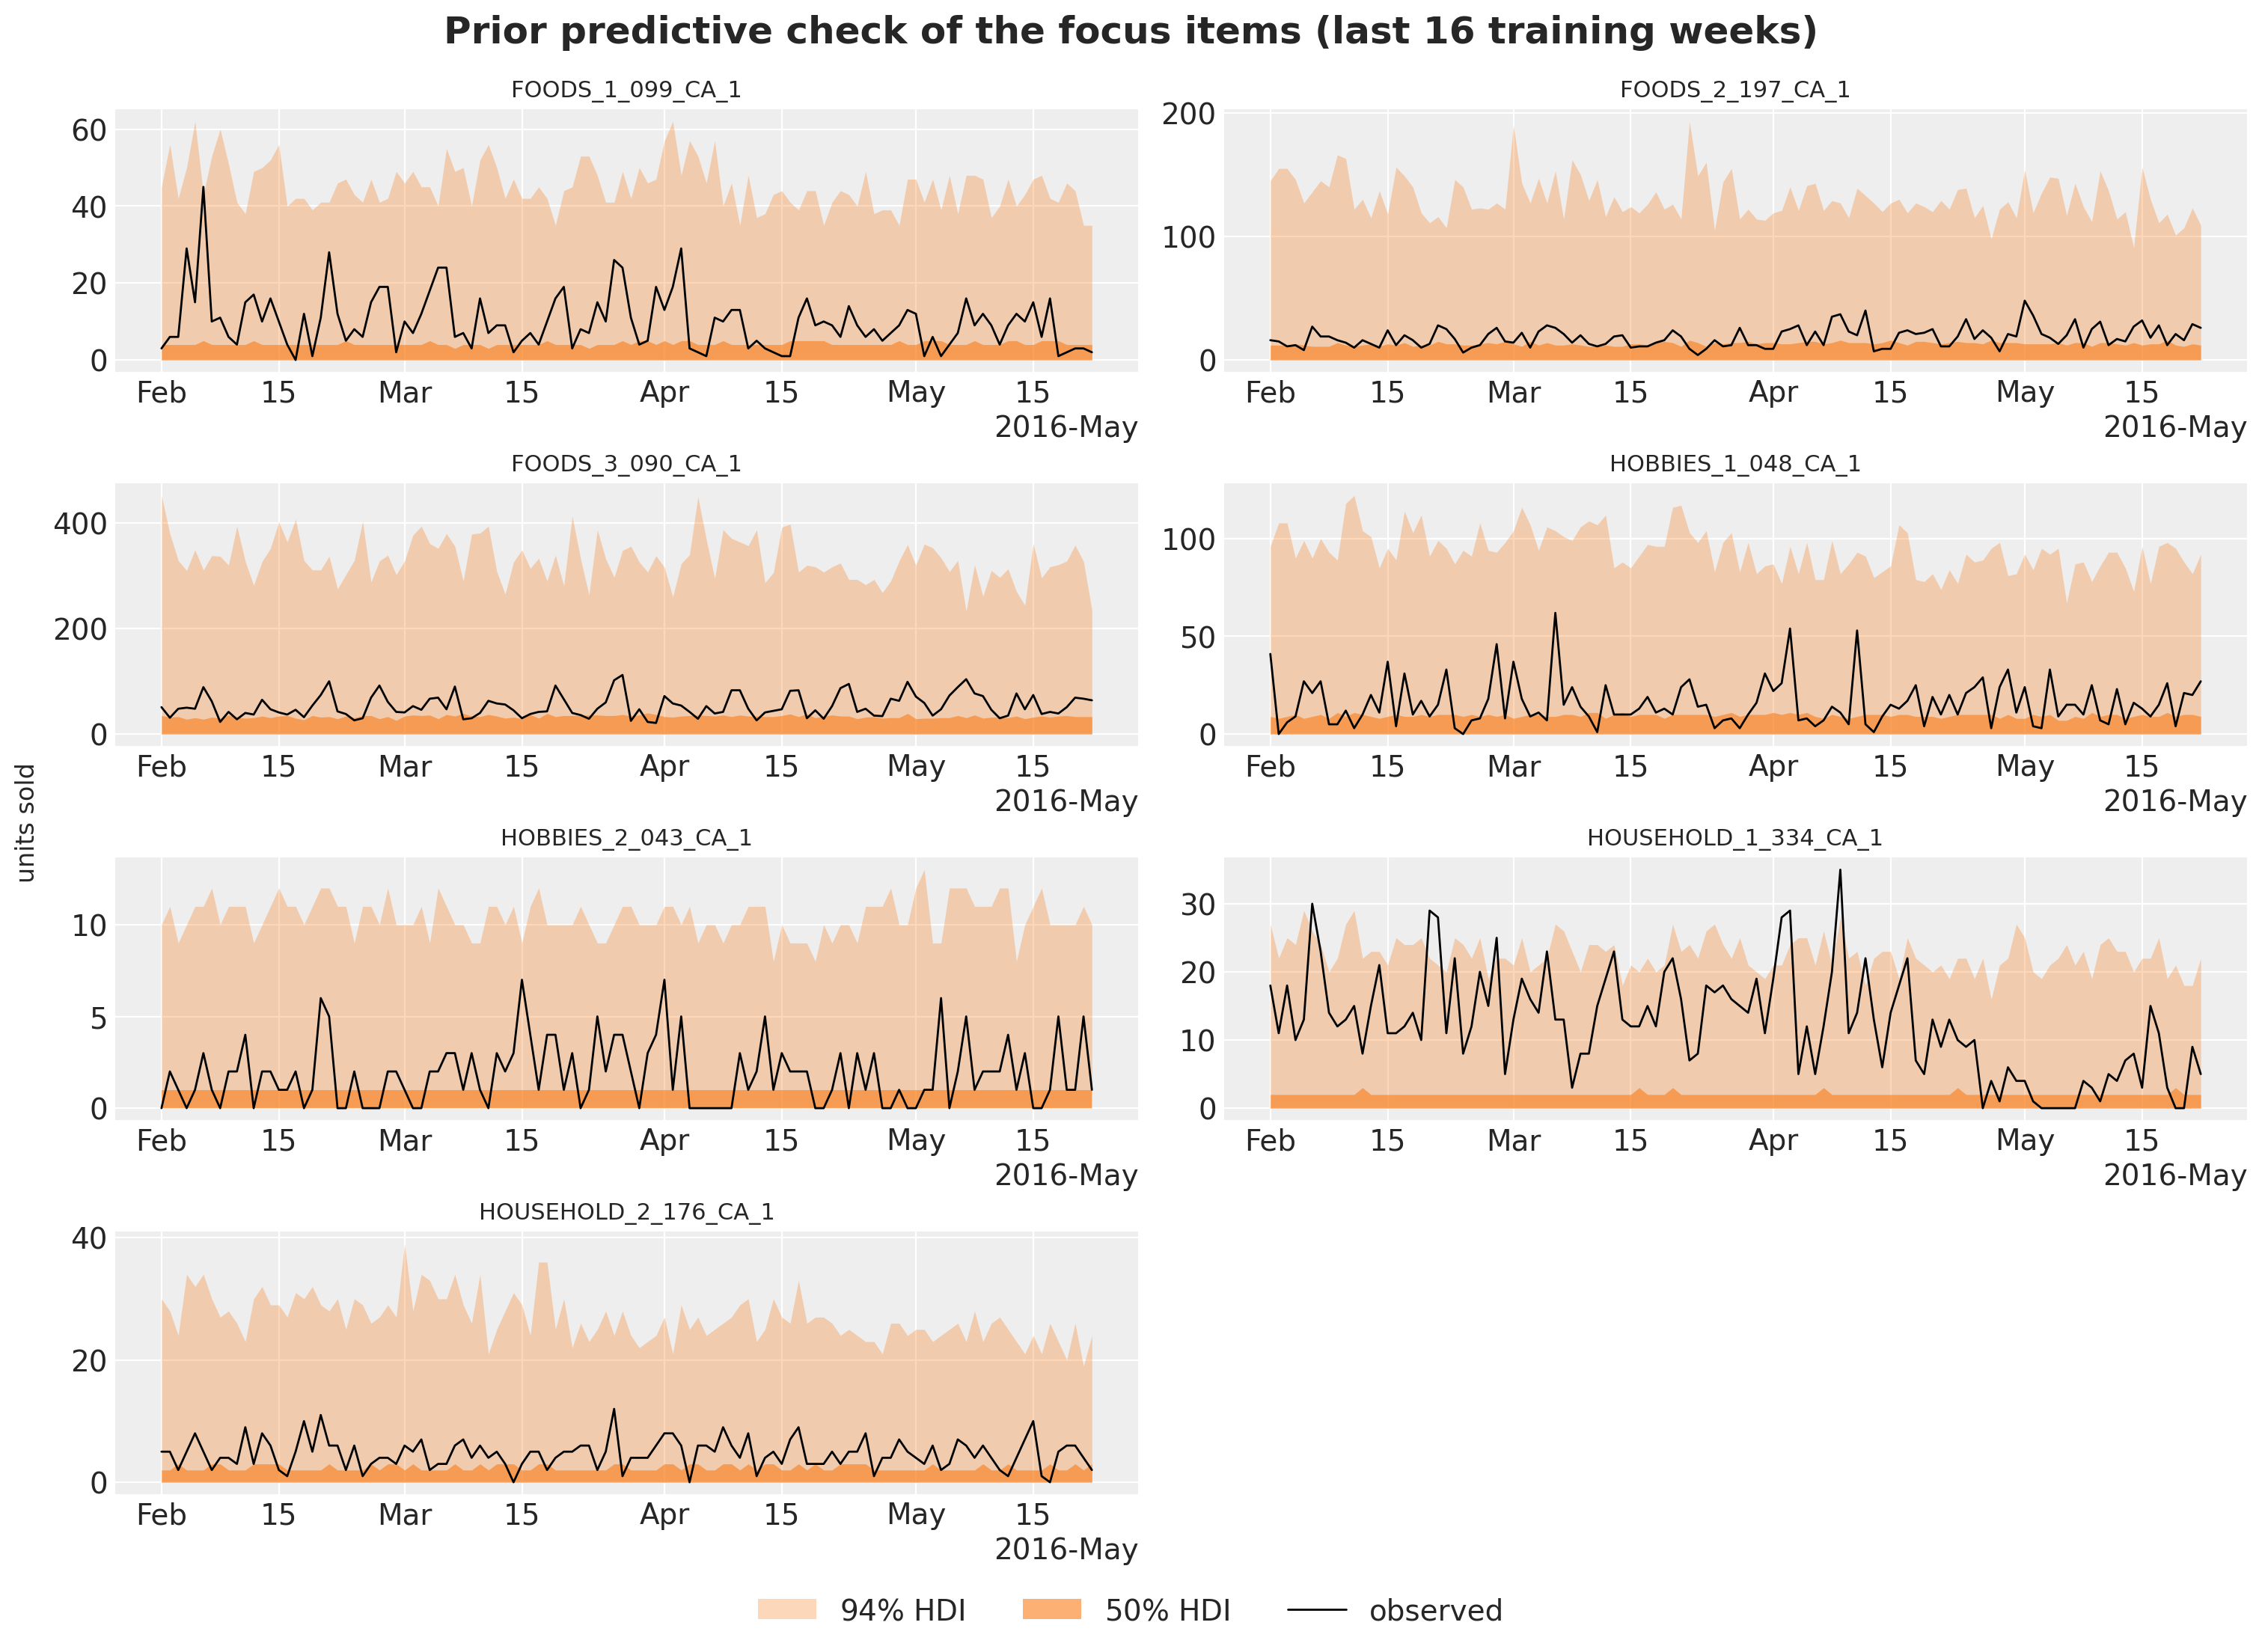

In [15]:
key_prior = random.PRNGKey(seed=0)  # a side key: the fits below keep their own stream
prior_focus = Predictive(focus_model, num_samples=500, return_sites=["obs"])(
    key_prior, covariates_focus[:, :HISTORY_DAYS]
)["obs"]

plot_series_panel(
    None,
    prior_focus[:, -16 * 7 :],
    sales[plot_start:N_DAYS_TRAIN, focus_index],
    focus_labels,
    date_num[plot_start:N_DAYS_TRAIN],
    date_num[plot_start:N_DAYS_TRAIN],
    ylabel="units sold",
    suptitle="Prior predictive check of the focus items (last 16 training weeks)",
    group="prior_predictive",
)

del prior_focus

The prior is wide but plausible for a count model whose intercept is centered on the recent level:

- for six of the seven items, the upper edge of the $94\%$ band is 4.5 to 7 times the mean observed level of the window, and the $50\%$ band runs from zero to about half of it (0.4 to 0.7 times);
- the prior knows where each item is, through the origin level, and does not know how much it moves.

HOUSEHOLD_1_334 is the exception. Its level dropped in May, so its prior is centered on the low level of the last 28 days, and $8\%$ of the days of the window, in the weeks before the drop, sit above its $94\%$ band.

## Fitting the model

`fit_model` fits the guide with SVI. Four settings matter:

- the guide is `AutoNormal` with a `series` plate that subsamples 1,500 series per step (`create_series_plates`); the model replays the same indices through `numpyro.subsample`;
- `AutoNormal` starts at the prior median, because the default uniform initialization overflows the exponential of a sum of eleven log-scale terms;
- a one-cycle Adam schedule peaking at a learning rate of 0.03, with clipped gradients, runs for 3,000 steps;
- the training data are the last two years before the origin. Two years instead of the five of the baselines halve the cost of a step and let the minibatches visit every series about 150 times. A walk anchored at the origin has no use for older history, and the yearly terms still see two cycles.

We fit the model once on the last two years before the evaluation window and look at the loss.

In [16]:
SUBSAMPLE_SIZE = 1_500


def create_series_plates(covariates: Array, data: Array | None = None) -> numpyro.plate:
    """Subsample the series plate in the guide; the model replays the same indices."""
    return numpyro.plate("series", n_series, subsample_size=SUBSAMPLE_SIZE)


NUM_STEPS = 3_000
PEAK_LR = 0.03


def fit_model(
    rng_key: Array,
    model: ForecastModel,
    train_covariates: Array,
    train_counts: Array,
    *,
    num_steps: int = NUM_STEPS,
) -> tuple[AutoNormal, SVIRunResult, float]:
    """Fit the model with subsampled SVI; return the guide, the result and the wall time."""
    guide = AutoNormal(model, init_loc_fn=init_to_median, create_plates=create_series_plates)
    schedule = optax.linear_onecycle_schedule(
        transition_steps=num_steps,
        peak_value=PEAK_LR,
        pct_start=0.2,
        pct_final=0.8,
        div_factor=10,
        final_div_factor=10,
    )
    optimizer = optax.chain(optax.clip_by_global_norm(10.0), optax.adam(schedule))
    svi = SVI(model, guide, optimizer, Trace_ELBO())

    start = perf_counter()
    result = svi.run(rng_key, num_steps, train_covariates, train_counts, progress_bar=False)
    jax.block_until_ready(result.losses)

    return guide, result, perf_counter() - start

mean loss of the last two 300-step windows: 25,085,724 and 25,024,252


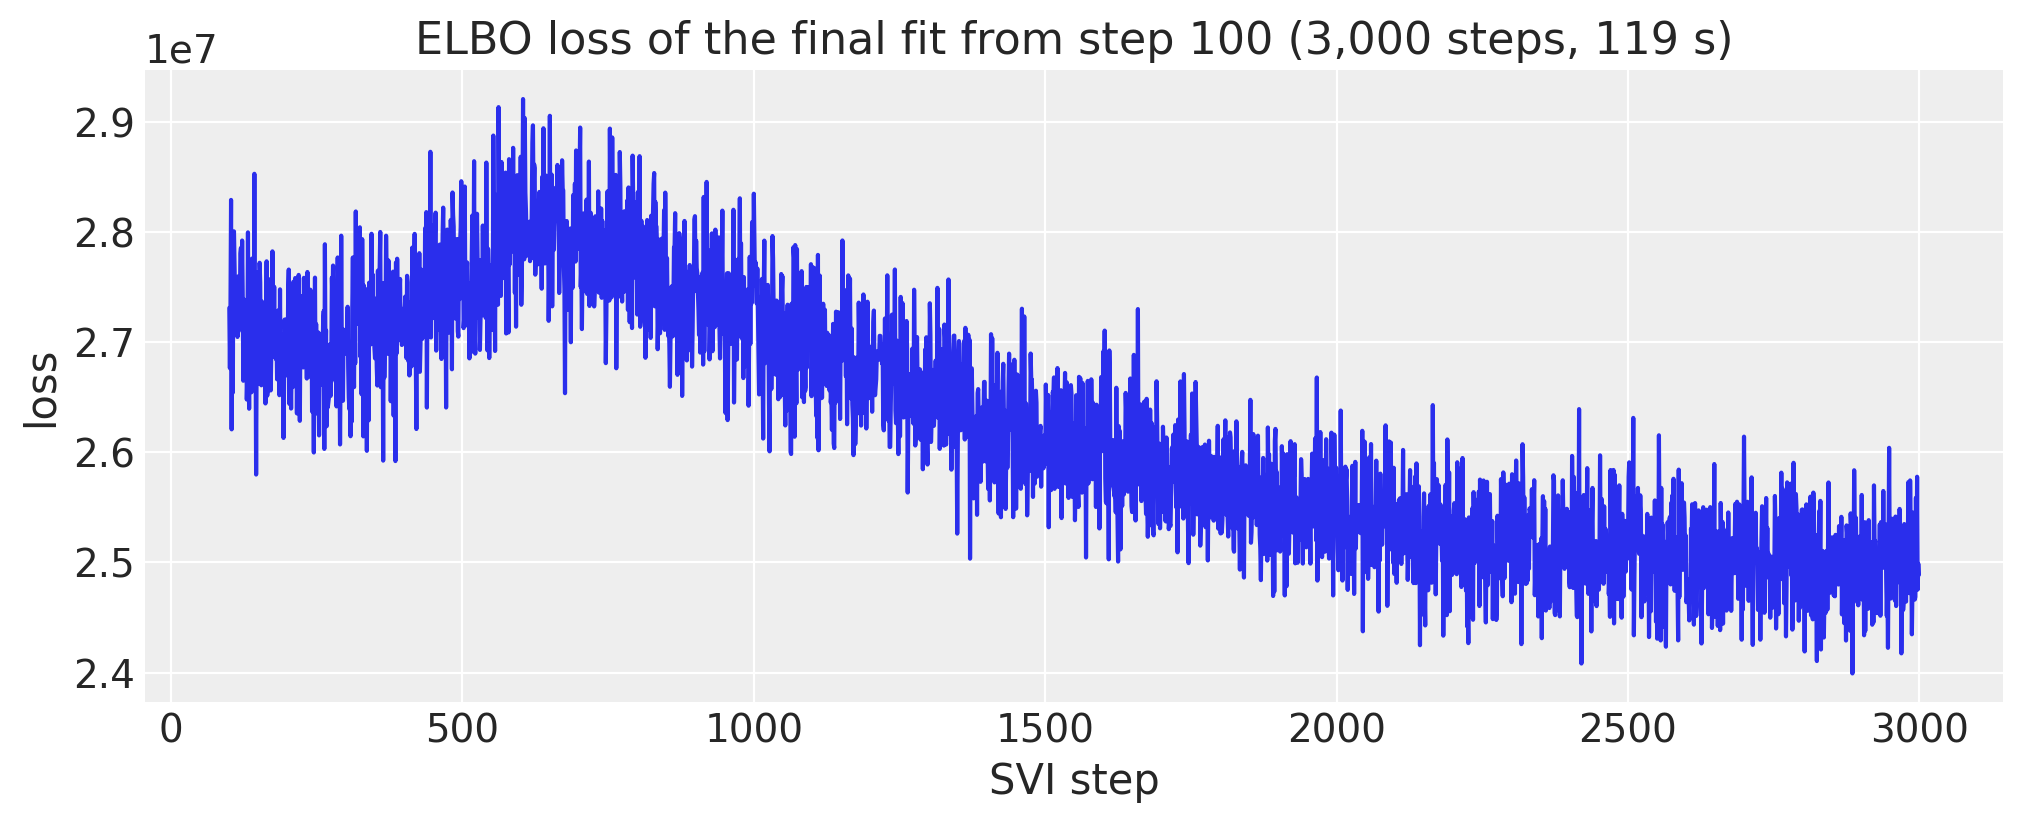

In [17]:
rng_key, key_fit = random.split(rng_key)
guide_final, svi_final, time_final = fit_model(
    key_fit, final_model, covariates_final[:, :HISTORY_DAYS], counts_final
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(100, NUM_STEPS), np.asarray(svi_final.losses[100:]), color="C0")

loss_tail = np.asarray(svi_final.losses[-600:]).reshape(2, 300).mean(axis=1)

print(f"mean loss of the last two 300-step windows: {loss_tail[0]:,.0f} and {loss_tail[1]:,.0f}")

ax.set(
    title=f"ELBO loss of the final fit from step 100 ({NUM_STEPS:,} steps, {time_final:.0f} s)",
    xlabel="SVI step",
    ylabel="loss",
);

The loss rises during the warm-up of the one-cycle schedule, which reaches its peak learning rate at step 600, and then falls. Over the last 600 steps it is almost flat: the mean losses of steps 2,400 to 2,700 and of steps 2,700 to 3,000 differ by $0.2\%$, so a longer run would buy little. The curve is noisy because every step scores a different random set of 1,500 series, as for the bottom-up model of the baselines notebook.

### Posterior of the shared parameters

There are too many item-level sites to inspect one by one, so we export the shared sites, the population scales and the pooled effects, to ArviZ with named coordinates. The first forest plot shows the five population scales by department (by store for the shock scale): how much each component moves on the log scale.

In [18]:
rng_key, key_post = random.split(rng_key)
posterior_final = draw_posterior(key_post, guide_final, svi_final.params, 500)

# The SNAP days are fixed days of the month per state, so the identified quantity is the SNAP-day
# lift of a store-department: its SNAP effect plus its day-of-month pattern averaged over the
# SNAP days of its state, minus the pattern averaged over the other days. (state, 31) mask first.
snap_by_dom = np.stack(
    [
        np.bincount(np.asarray(dom_table), weights=column, minlength=31) > 0
        for column in np.asarray(snap_table).T
    ]
)
group_store = np.asarray(store_index)[
    [int(np.argmax(np.asarray(group_index) == g)) for g in range(N_GROUPS)]
]
snap_mask = snap_by_dom[np.asarray(state_of_store)[group_store]]  # (group, 31)
dom_draws = np.asarray(posterior_final["dom_group"])  # (draw, group, 31)
snap_lift = (
    np.asarray(posterior_final["snap_group"])
    + (dom_draws * snap_mask).sum(-1) / snap_mask.sum(-1)
    - (dom_draws * ~snap_mask).sum(-1) / (~snap_mask).sum(-1)
)  # (draw, group)

DOW_LABELS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
SHARED_DIMS = {
    "sigma_alpha": ["dept"],
    "tau_phi": ["dept"],
    "sigma_walk": ["dept"],
    "sigma_item_dow": ["dept"],
    "sigma_event": ["dept"],
    "w_fourier": ["dept", "harmonic"],
    "gamma_event": ["dept", "event"],
    "store_shock_scale": ["store"],
    "log_phi_group": ["group"],
    "seasonal_group": ["group", "day_of_week"],
    "dom_group": ["group", "day_of_month"],
    "snap_group": ["group"],
    "snap_lift": ["group"],
    "alpha_group": ["group"],
}
tree_final = az.from_dict(
    {
        "posterior": {
            name: np.asarray(posterior_final[name])[None]
            for name in SHARED_DIMS
            if name != "snap_lift"
        }
        | {"snap_lift": snap_lift[None]}
    },
    coords={
        "dept": dept_ids,
        "group": group_ids,
        "store": store_ids,
        "day_of_week": DOW_LABELS,
        "day_of_month": list(range(1, 32)),
        "event": event_names,
        "harmonic": [f"{f}{k}" for f in ("sin", "cos") for k in range(1, N_HARMONICS + 1)],
    },
    dims=SHARED_DIMS,
)

sigma_alpha: posterior means from 0.09 to 0.22
tau_phi: posterior means from 0.59 to 0.84
sigma_walk: posterior means from 0.13 to 0.21
sigma_item_dow: posterior means from 0.03 to 0.08
store_shock_scale: posterior means from 0.06 to 0.11


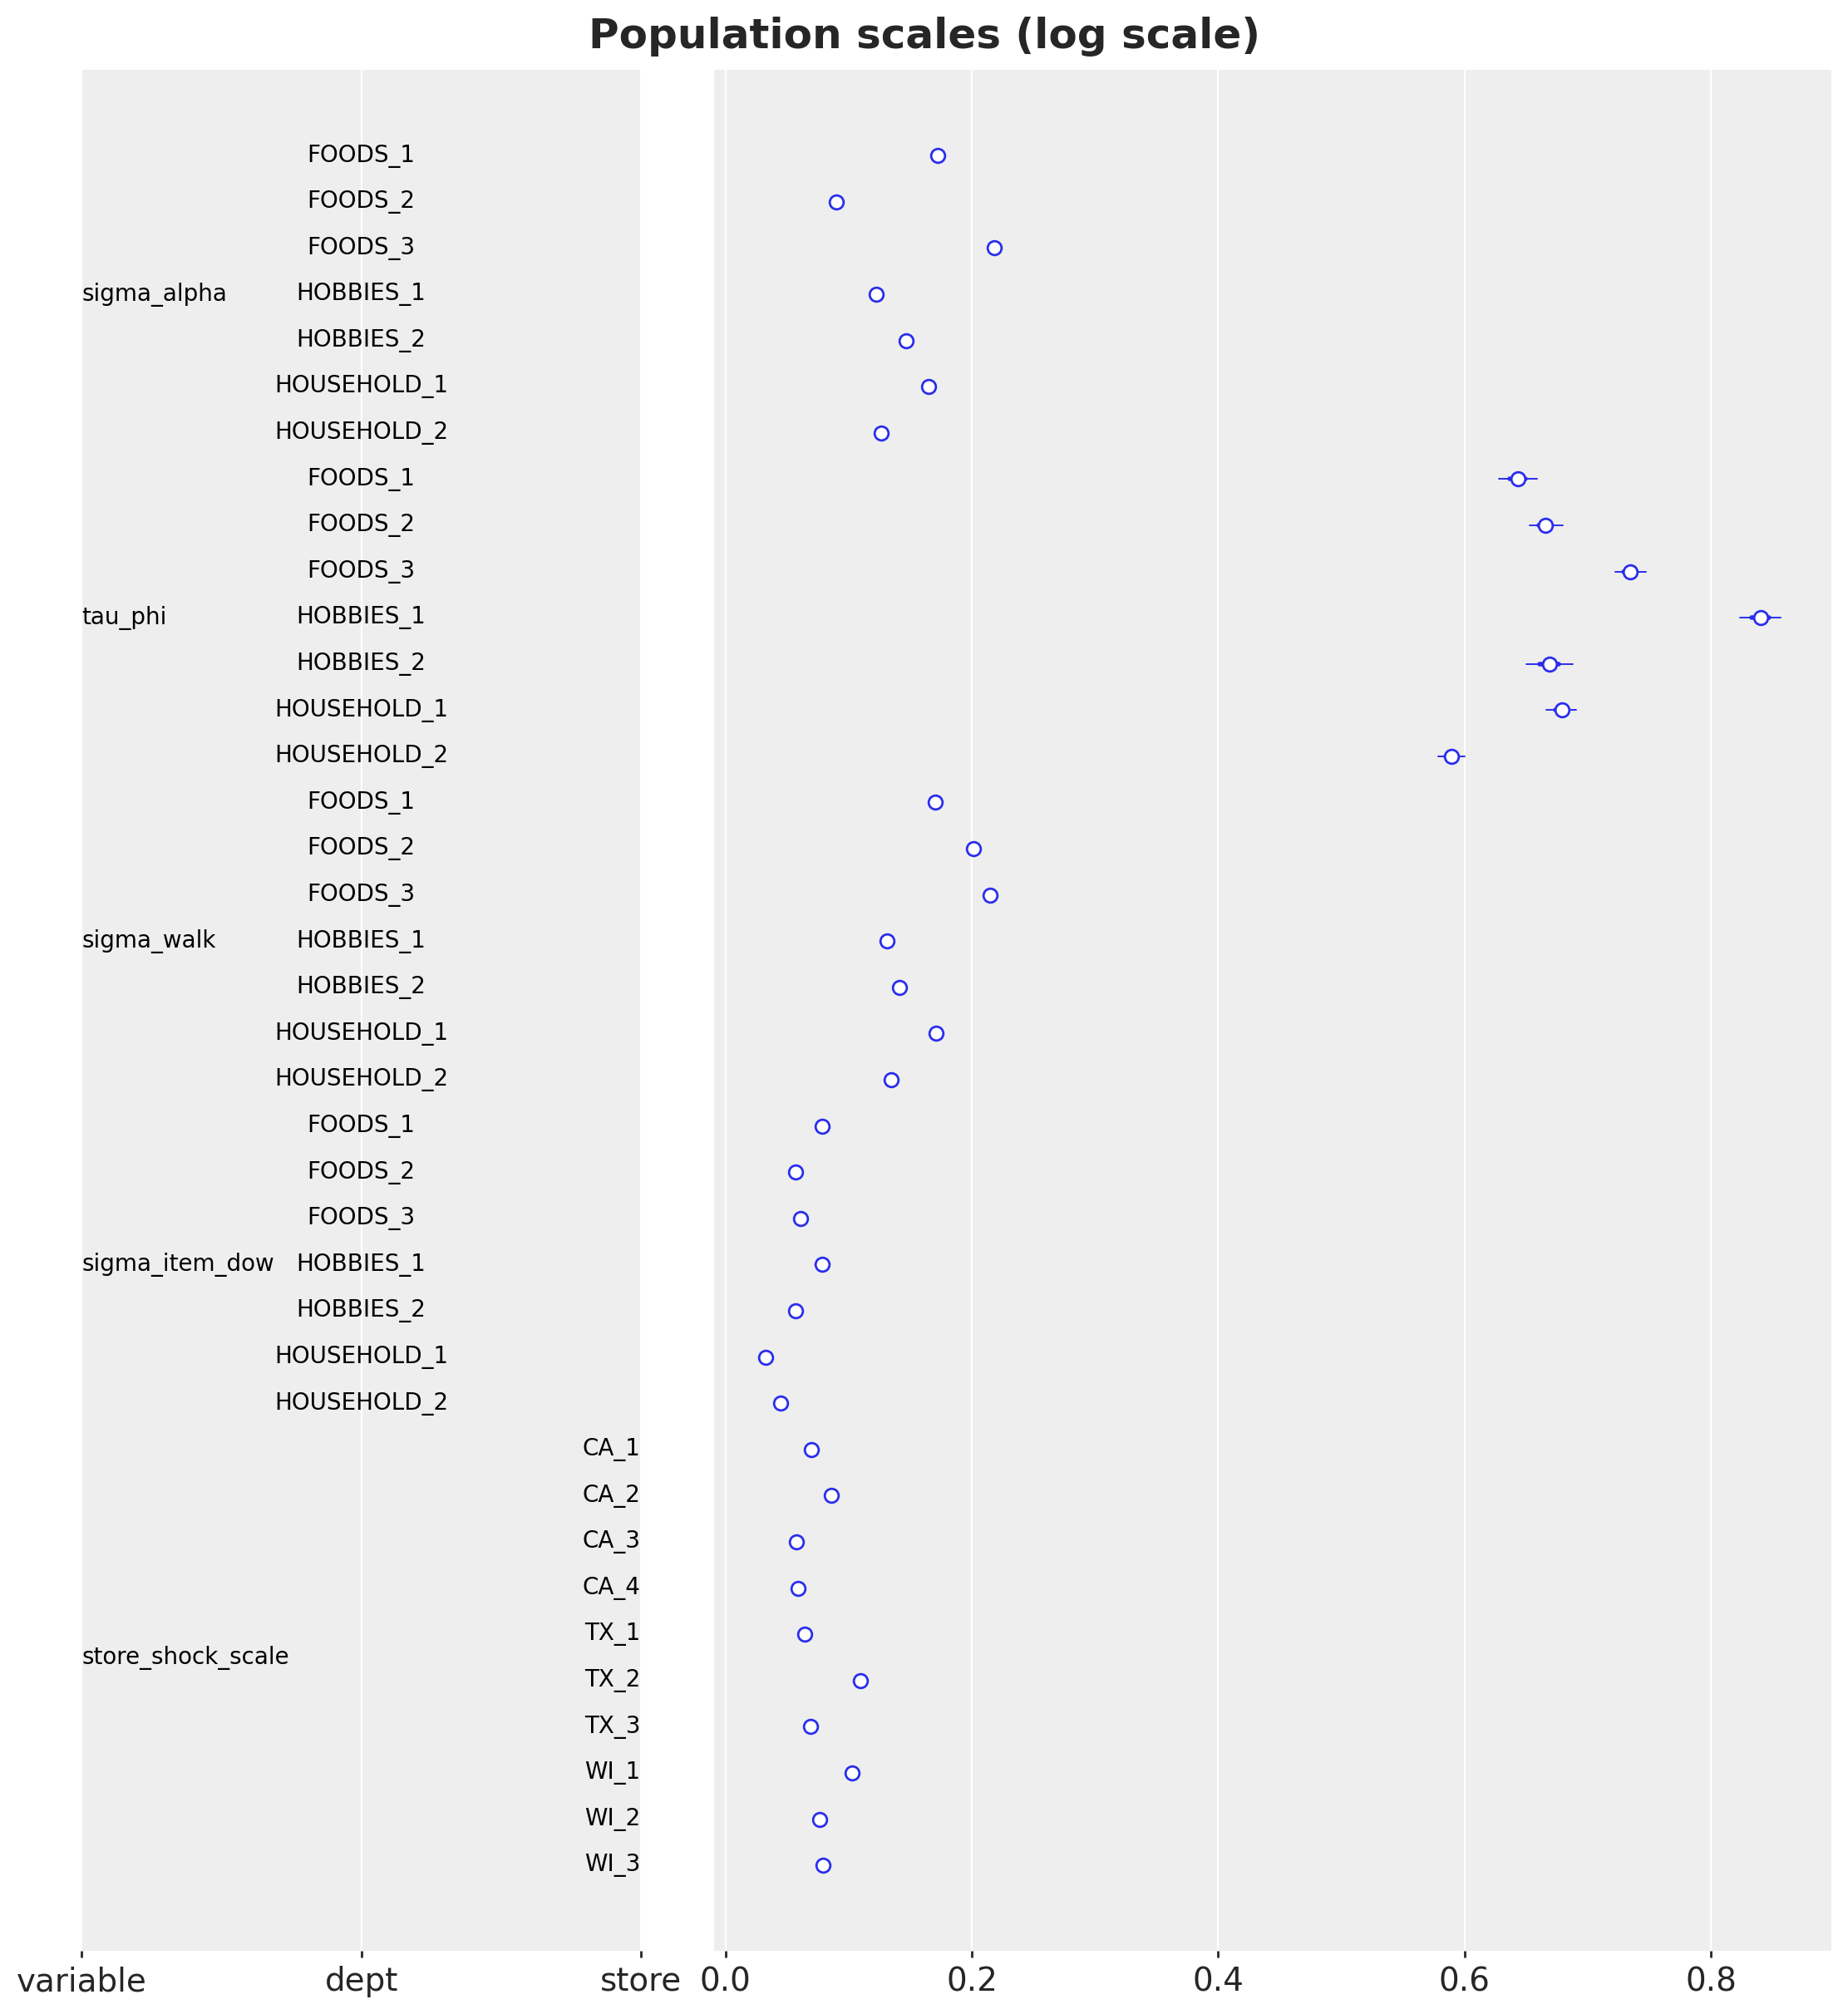

In [19]:
pc = az.plot_forest(
    tree_final,
    var_names=["sigma_alpha", "tau_phi", "sigma_walk", "sigma_item_dow", "store_shock_scale"],
    combined=True,
    figure_kwargs={"figsize": (11, 12)},
)
pc.viz["figure"].item().suptitle("Population scales (log scale)", fontsize=18, fontweight="bold")

for name in ["sigma_alpha", "tau_phi", "sigma_walk", "sigma_item_dow", "store_shock_scale"]:
    means = tree_final["posterior"][name].mean(("chain", "draw"))

    print(f"{name}: posterior means from {float(means.min()):.2f} to {float(means.max()):.2f}")

With 30,490 series behind each population scale and a mean-field guide, the intervals are tiny, so these are in effect point estimates. On the log scale:

- the intercept deviations $\sigma^{\alpha}$ are 0.09 to 0.22 by department, so the prior center, the last-28-day level, is close for most items;
- the dispersion spreads $\tau$ are 0.59 to 0.84, so two items of the same store-department can differ in dispersion by a factor of two: the item-level dispersion matters;
- the block-walk innovation scales $\sigma^{u}$ are 0.13 to 0.21 per 28-day block, largest for FOODS_2 and FOODS_3 (0.20 and 0.21) and smallest for HOBBIES_1, HOUSEHOLD_2 and HOBBIES_2 (0.13 to 0.14), so the level of a food item moves by about $20\%$ from one block to the next;
- the item weekday deviations $\sigma^{s}$ are 0.03 to 0.08, small next to the store-department pattern they refine;
- the store shock scales $\sigma^{\epsilon}$ are 0.06 to 0.11, highest for TX_2 and WI_1.

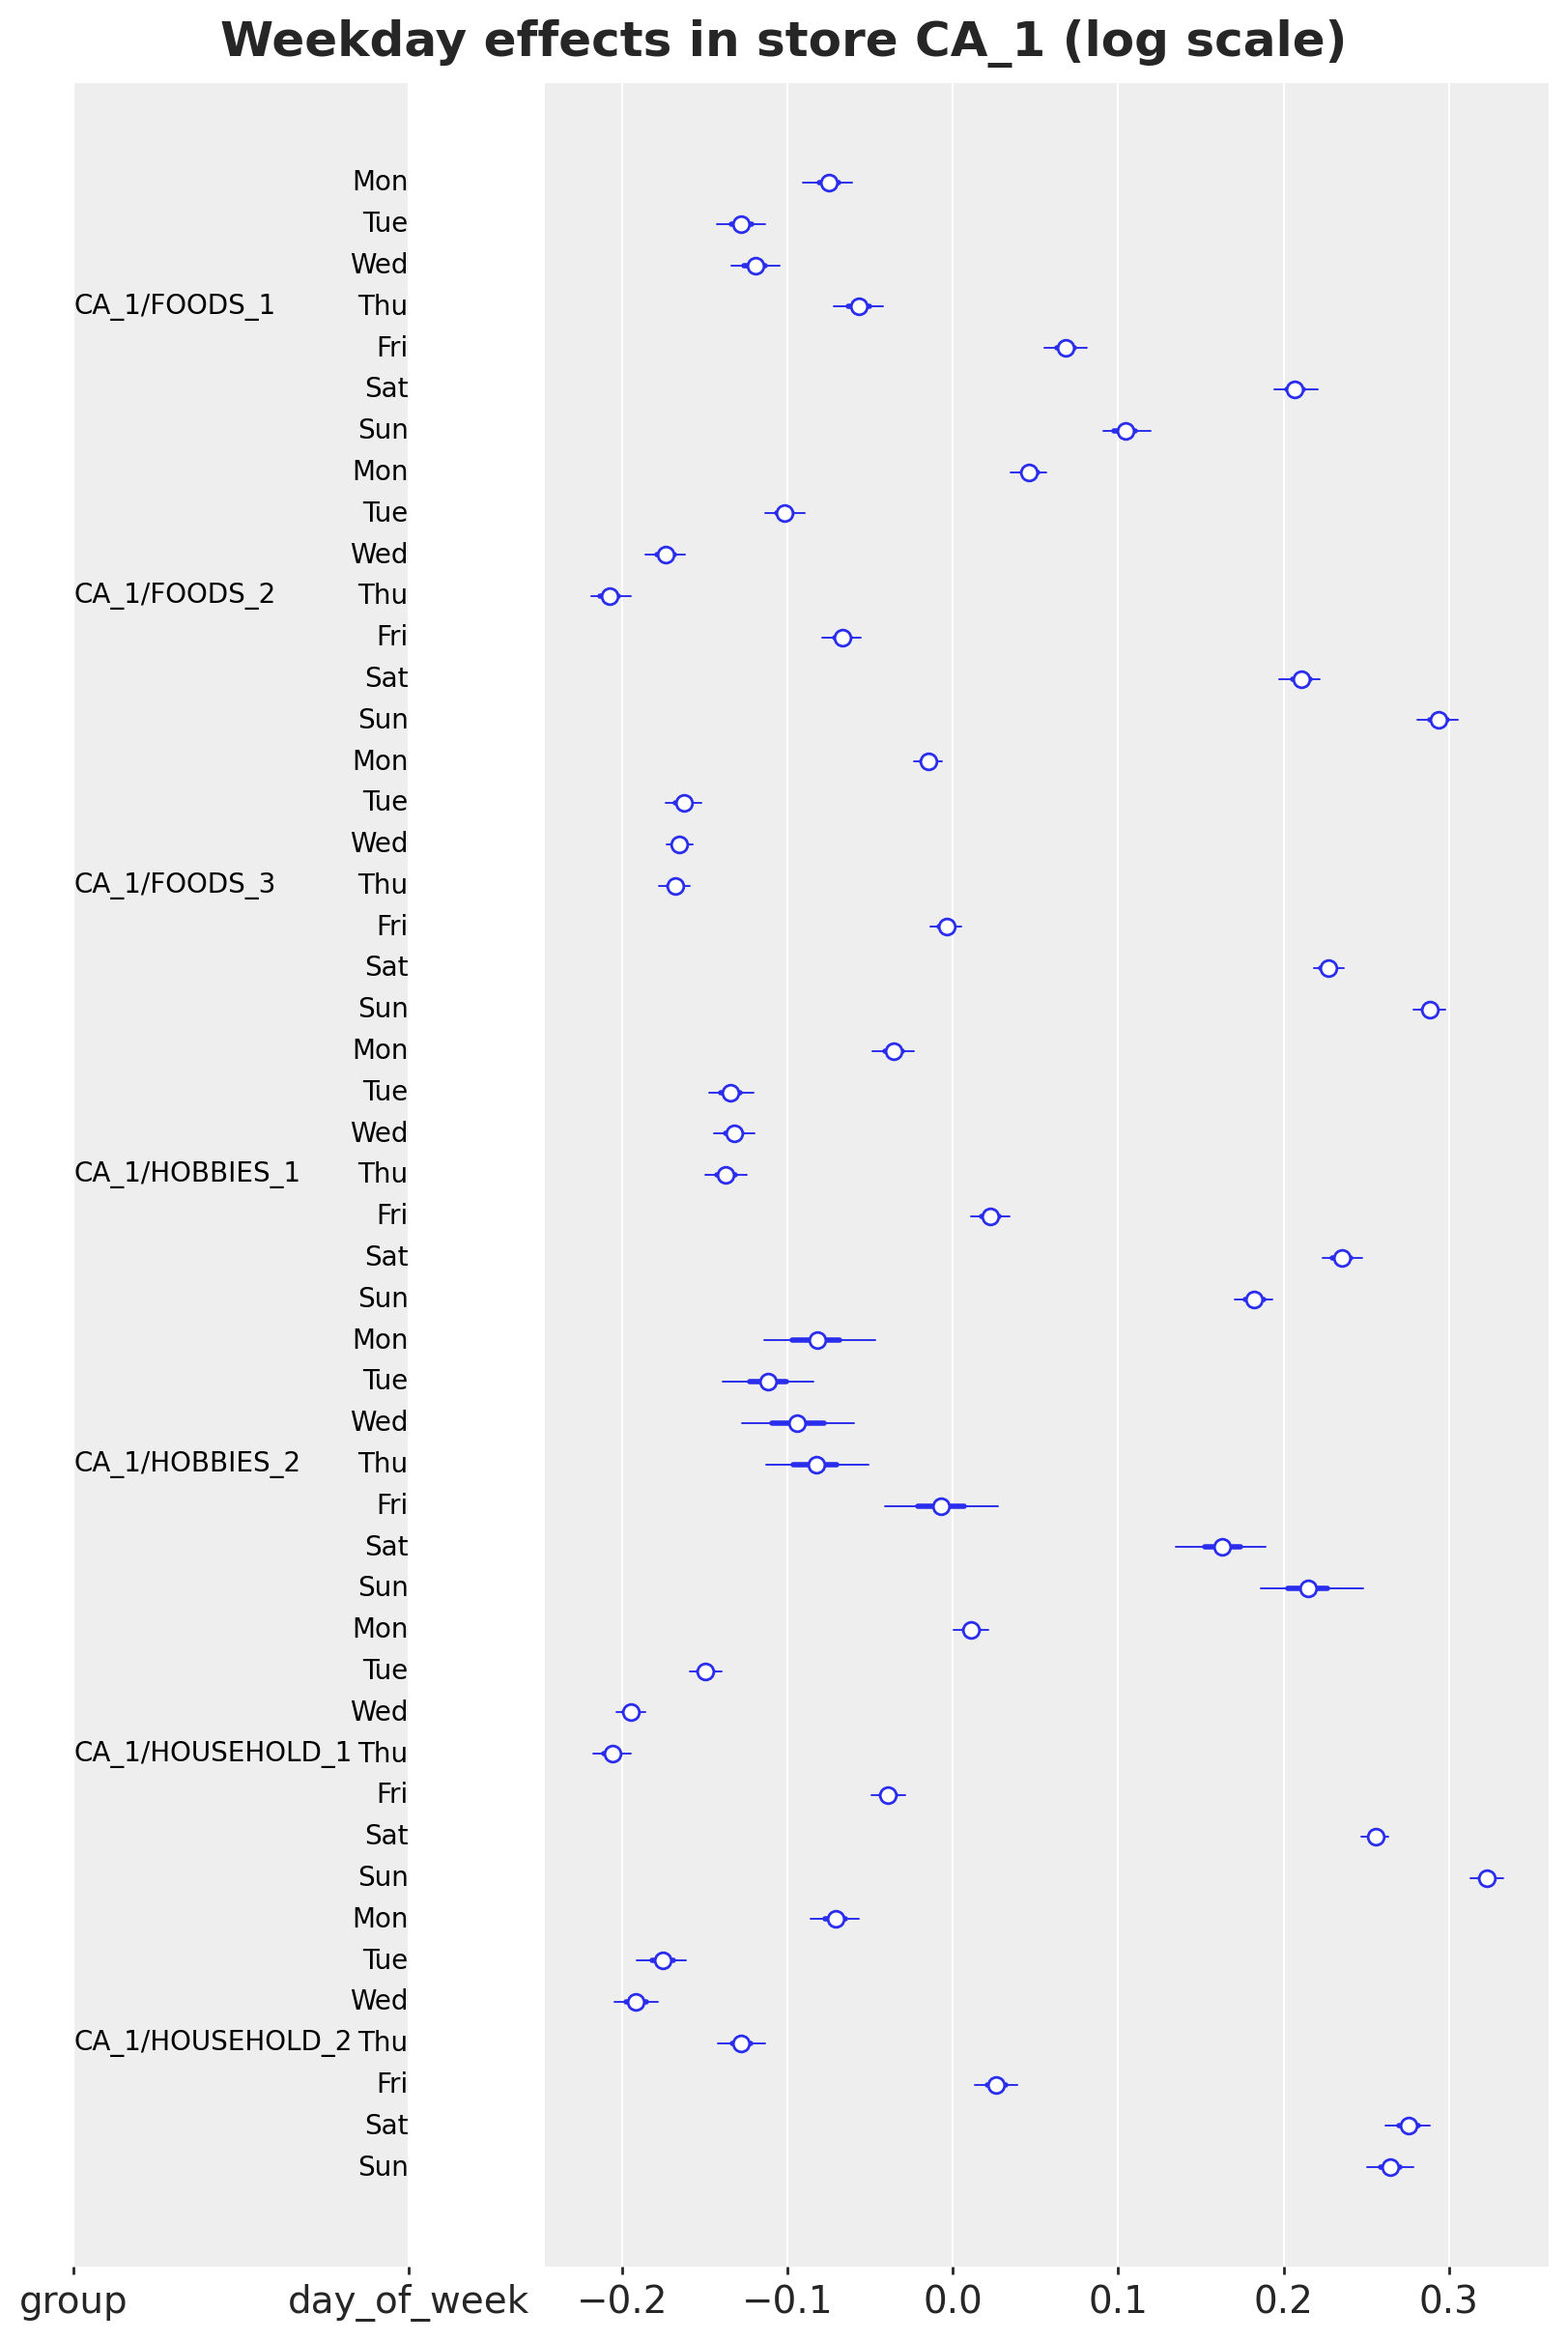

In [20]:
ca1_groups = [label for label in group_ids if label.startswith("CA_1/")]
pc = az.plot_forest(
    tree_final,
    var_names=["seasonal_group"],
    coords={"group": ca1_groups},
    combined=True,
    labels=["group", "day_of_week"],
    figure_kwargs={"figsize": (8, 12)},
)
pc.viz["figure"].item().suptitle(
    "Weekday effects in store CA_1 (log scale)", fontsize=18, fontweight="bold"
);

In store CA_1 every department sells most on the weekend: Saturday and Sunday are $+0.1$ to $+0.32$ on the log scale, Tuesday to Thursday $-0.06$ to $-0.21$. The shape varies by department:

- FOODS_2, FOODS_3, HOBBIES_2 and HOUSEHOLD_1 peak on Sunday;
- FOODS_1, HOBBIES_1 and HOUSEHOLD_2 peak on Saturday, and FOODS_1 has the flattest week.

These are the store-department patterns; the item deviations around them have scales of 0.03 to 0.08.

The day-of-month effects are the newest component of the model, so the next figure shows them for the same seven store-departments, with the SNAP days of California shaded. The intervals are as narrow as above, so the figure shows only the posterior means.

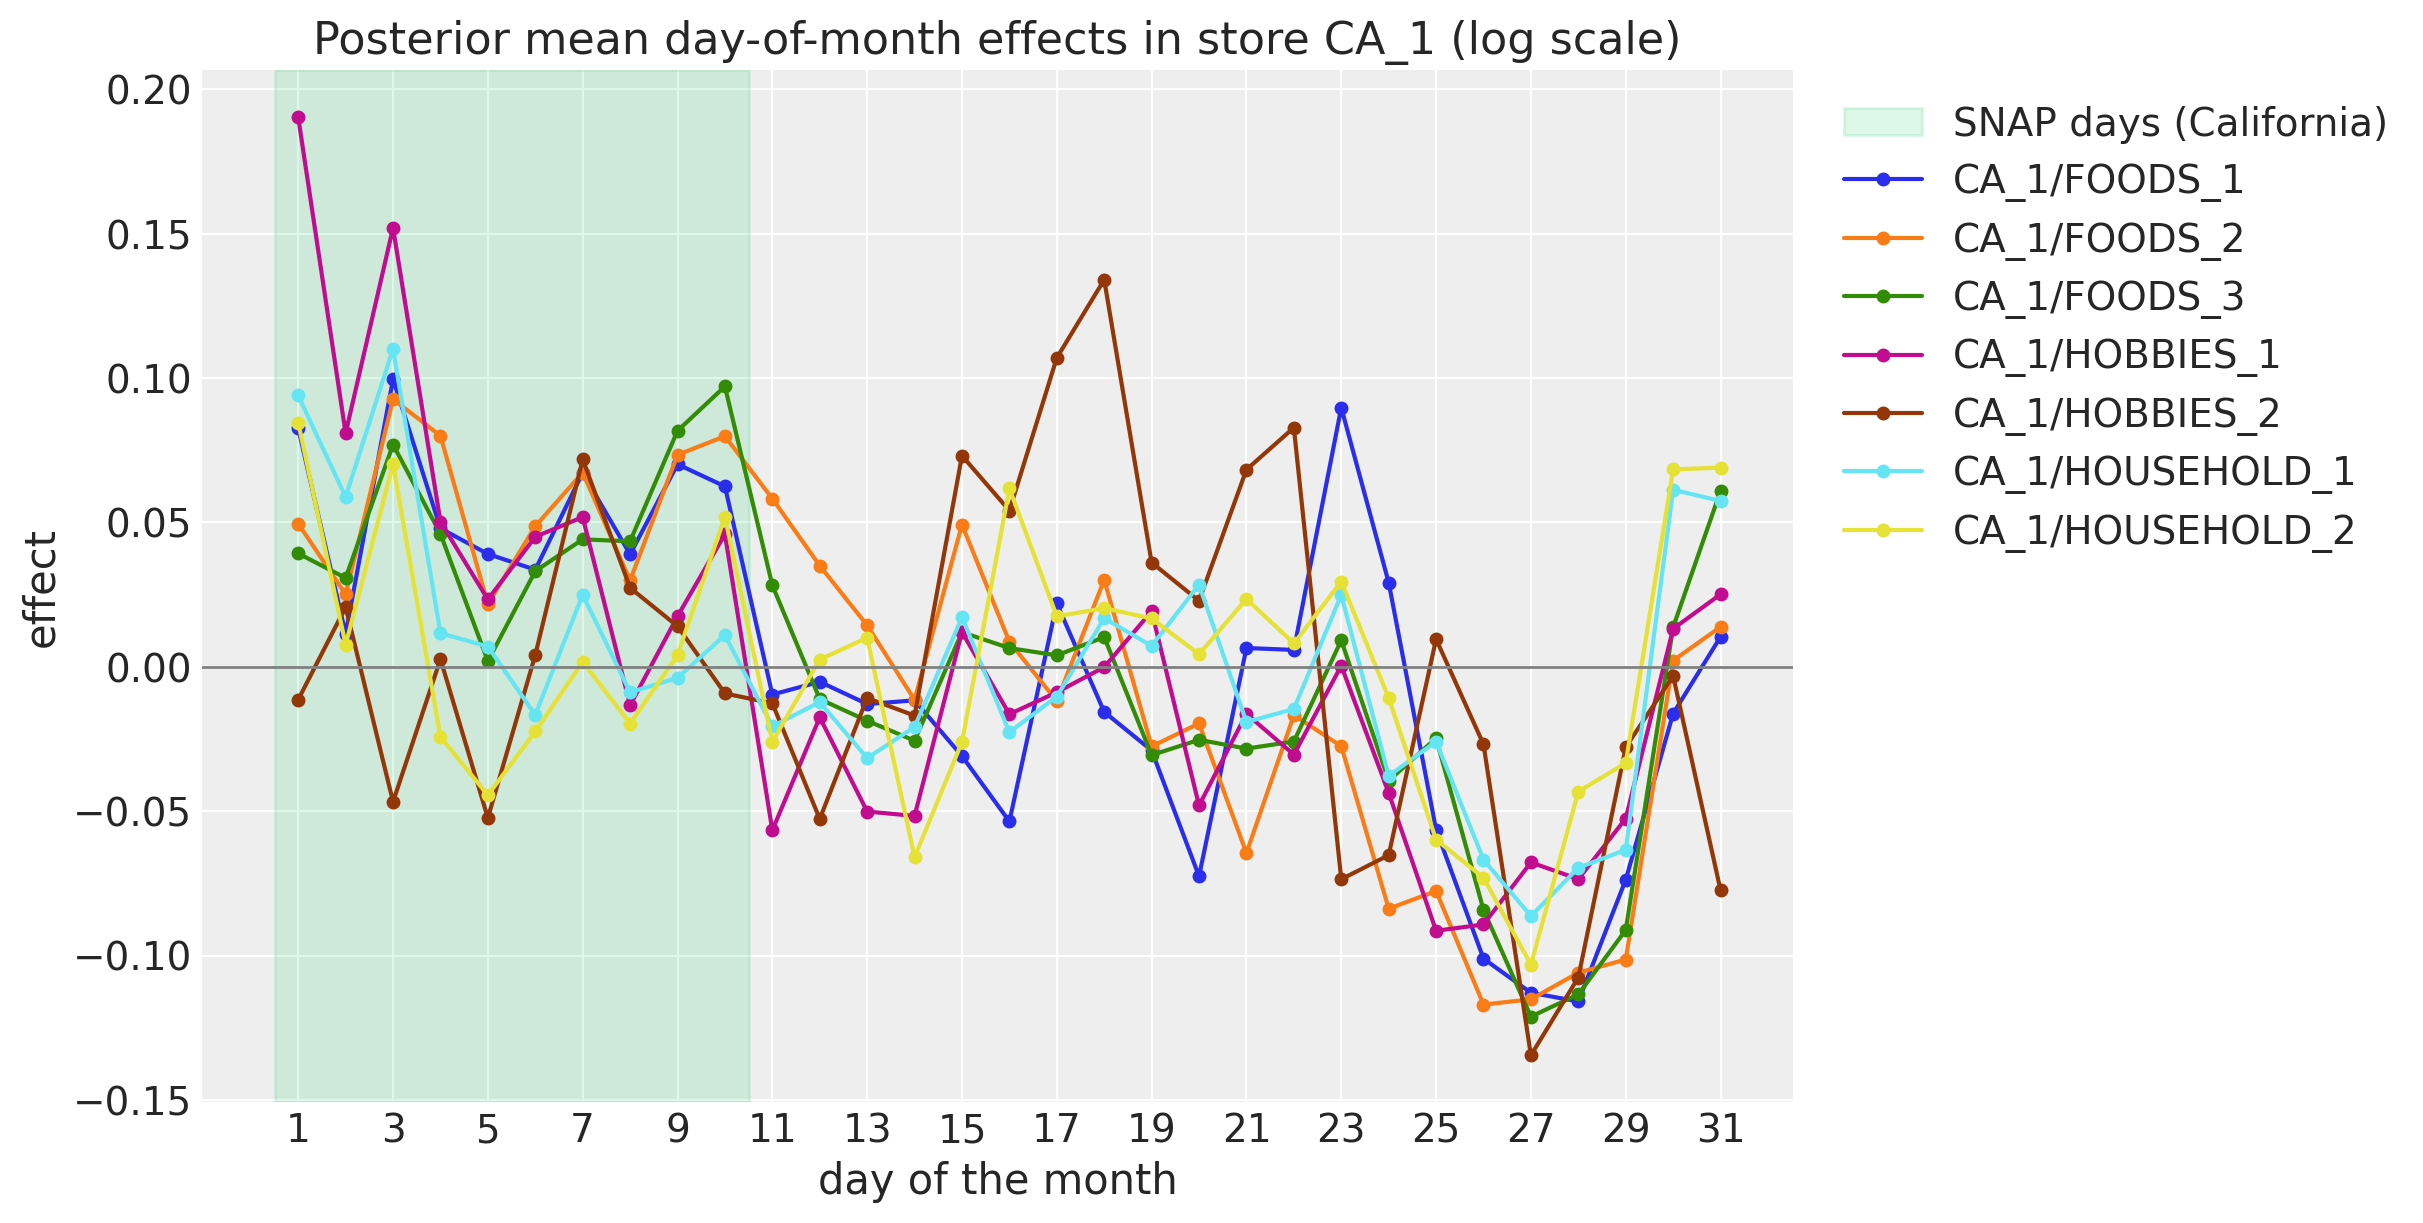

In [21]:
dom_mean = tree_final["posterior"]["dom_group"].mean(("chain", "draw"))
days_of_month = np.arange(1, 32)

fig, ax = plt.subplots(figsize=(12, 6))
ax.axvspan(0.5, 10.5, color="C7", alpha=0.15, label="SNAP days (California)")

for label in ca1_groups:
    ax.plot(days_of_month, dom_mean.sel(group=label), marker="o", ms=4, label=label)

ax.axhline(0.0, color="gray", lw=1)
ax.set(
    title="Posterior mean day-of-month effects in store CA_1 (log scale)",
    xlabel="day of the month",
    ylabel="effect",
    xticks=days_of_month[::2],
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0));

The first ten days of the month, the SNAP days of California and the first-of-month paydays, lift every FOODS and HOUSEHOLD department of the store (peaks of $+0.09$ to $+0.11$ on the log scale), and the last week of the month is the trough of every department, with lows of $-0.09$ to $-0.13$ around days 25 to 28. The two HOBBIES departments are noisier: HOBBIES_1 has the strongest start of the month ($+0.19$ on day 1), and HOBBIES_2 peaks in the middle of the month (days 15 to 18). This is the pay cycle that the kit's top-down model reads from its 31 dummies, here at the store-department resolution.

largest posterior mean of the SNAP coefficient alone: 0.29


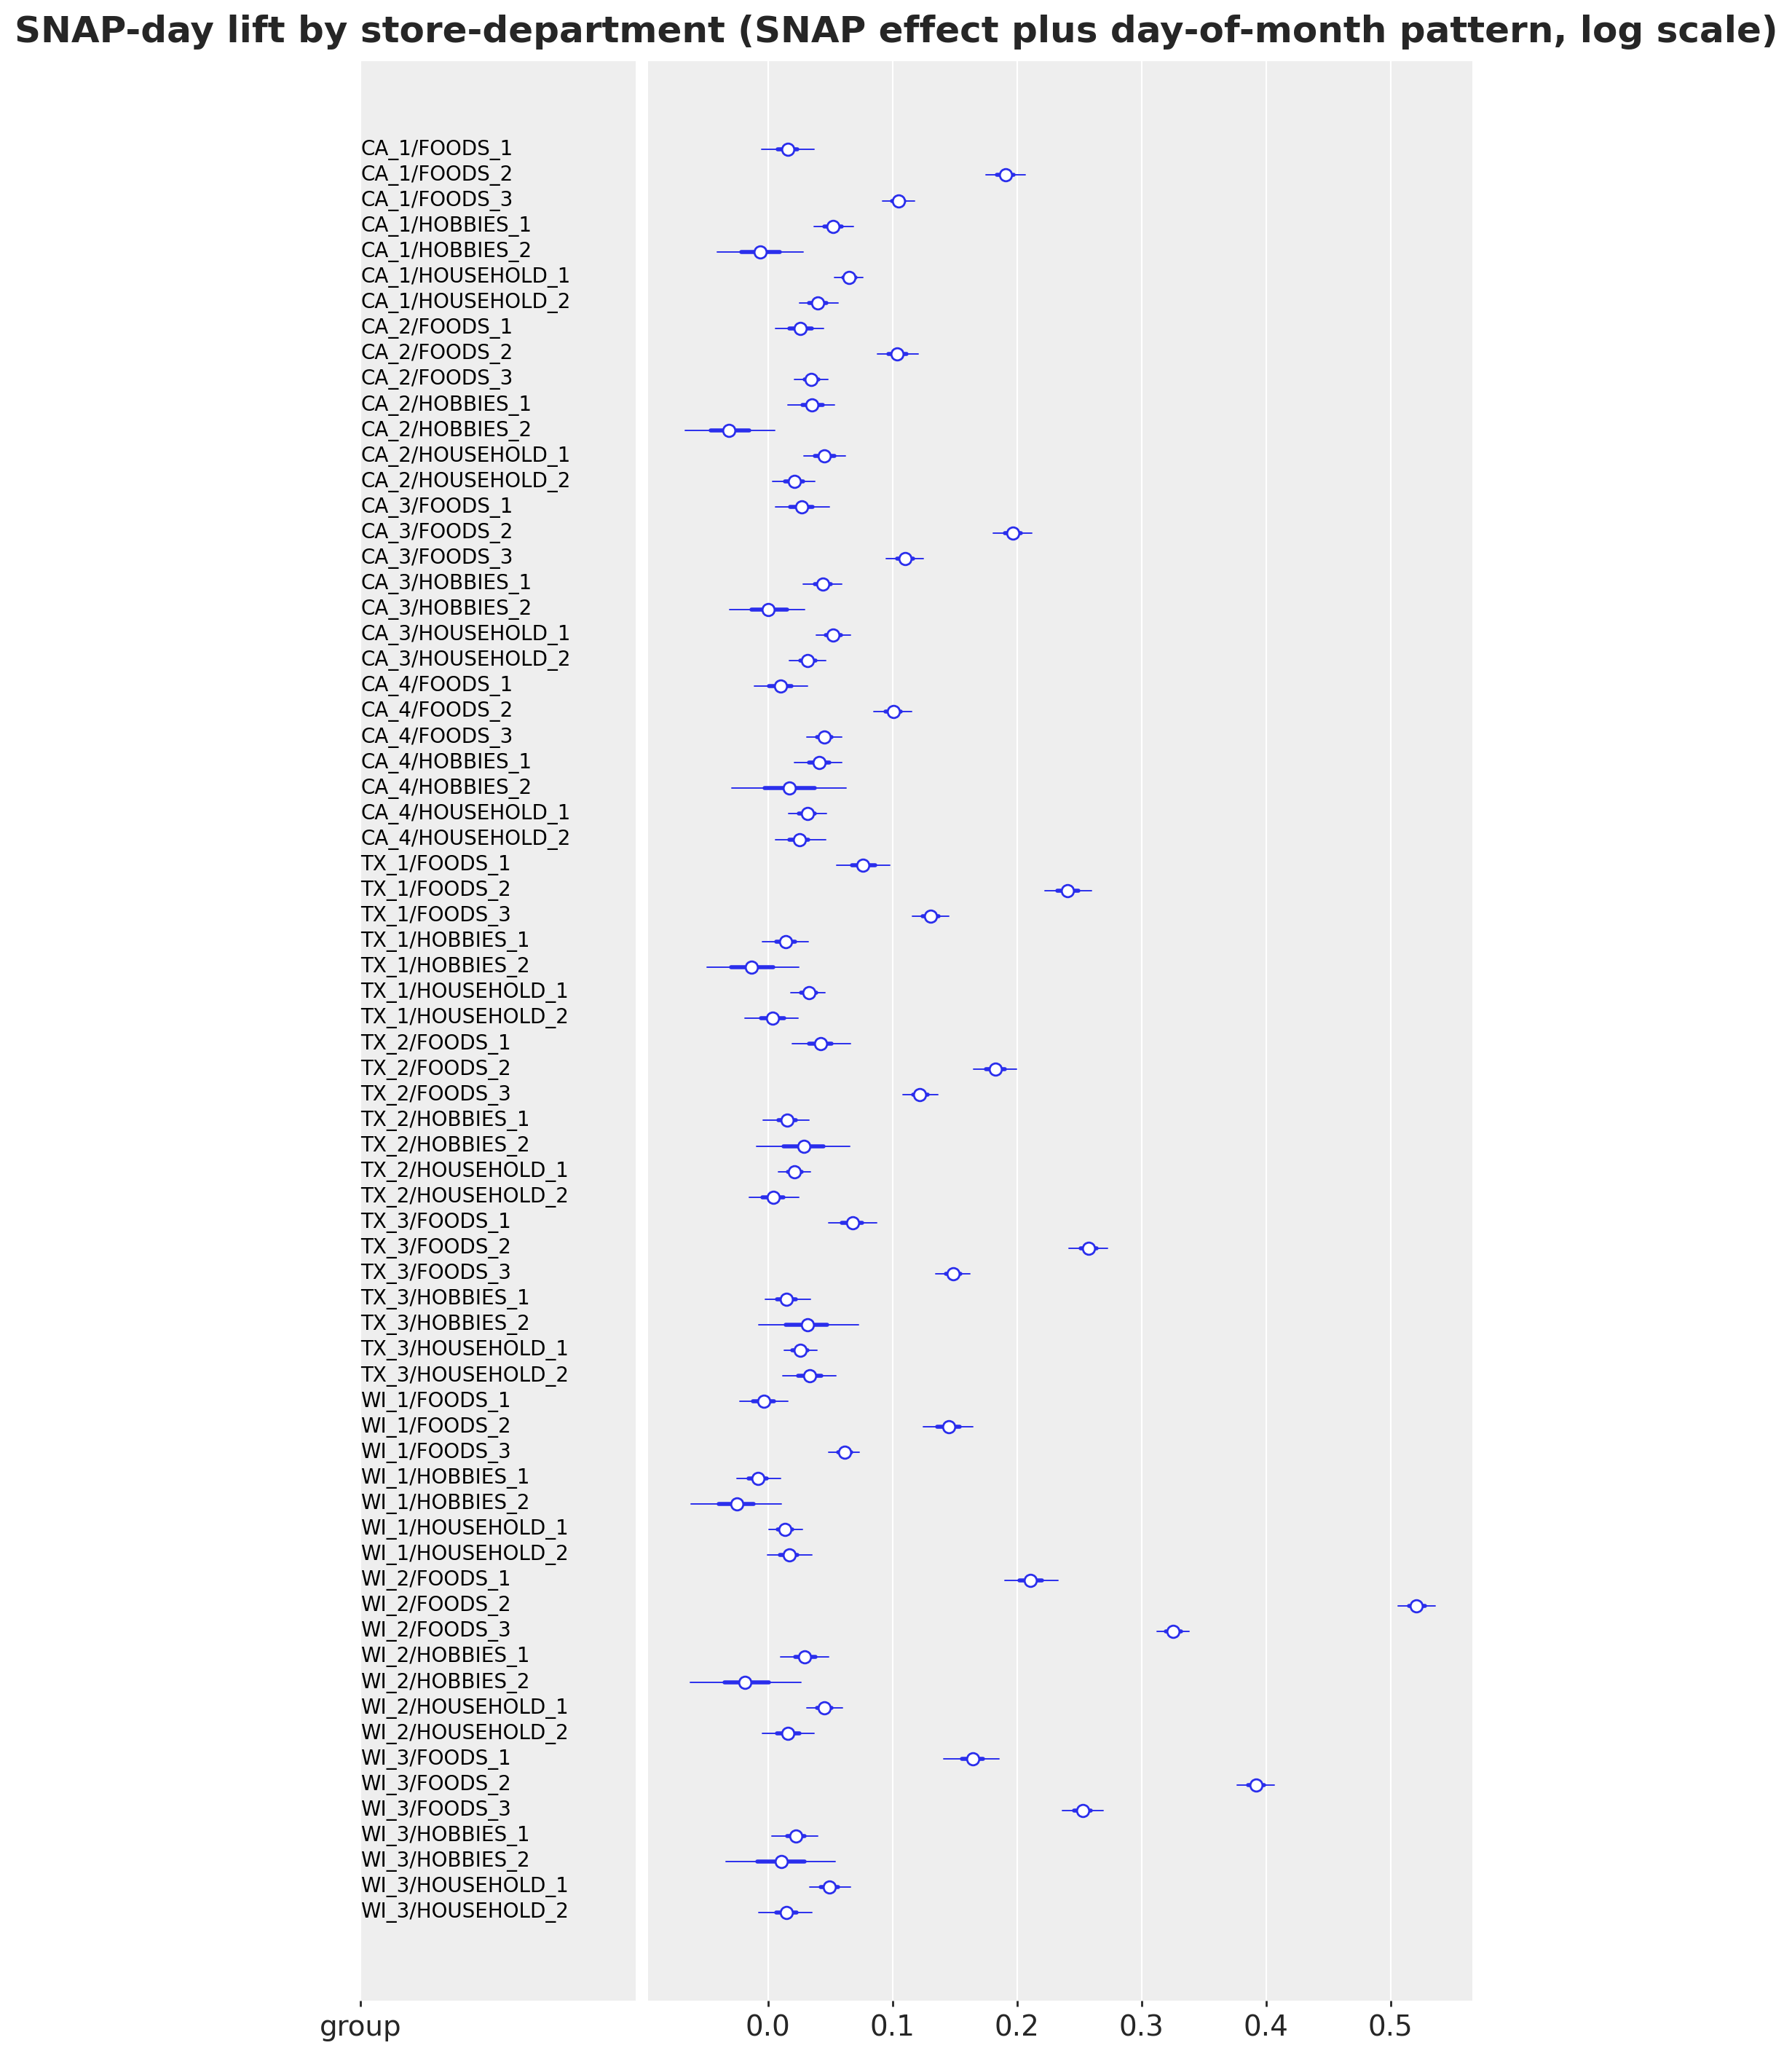

In [22]:
pc = az.plot_forest(
    tree_final,
    var_names=["snap_lift"],
    combined=True,
    labels=["group"],
    figure_kwargs={"figsize": (8, 14)},
)
pc.viz["figure"].item().suptitle(
    "SNAP-day lift by store-department (SNAP effect plus day-of-month pattern, log scale)",
    fontsize=18,
    fontweight="bold",
)

# The SNAP coefficient alone, for comparison with the lift.
snap_alone = tree_final["posterior"]["snap_group"].mean(("chain", "draw"))

print(f"largest posterior mean of the SNAP coefficient alone: {float(snap_alone.max()):.2f}")

The **SNAP-day lift** of a store-department is its SNAP effect plus its day-of-month pattern averaged over the SNAP days of its state, minus the pattern averaged over the other days. This is the quantity that the data identify, because the SNAP days are fixed days of the month.

- The lift is strongest for the FOODS departments of the Wisconsin and Texas stores, up to $+0.52$ for WI_2/FOODS_2, that is a factor of 1.7 on SNAP days.
- It is small for HOBBIES and HOUSEHOLD, at most $+0.07$.

This is what we expect of a food-stamp program, and it agrees with the kit's bottom-up model of the baselines notebook. The SNAP coefficient $\beta_j$ alone is smaller (at most $+0.29$), because the day-of-month pattern of the store-department carries the rest of the lift.

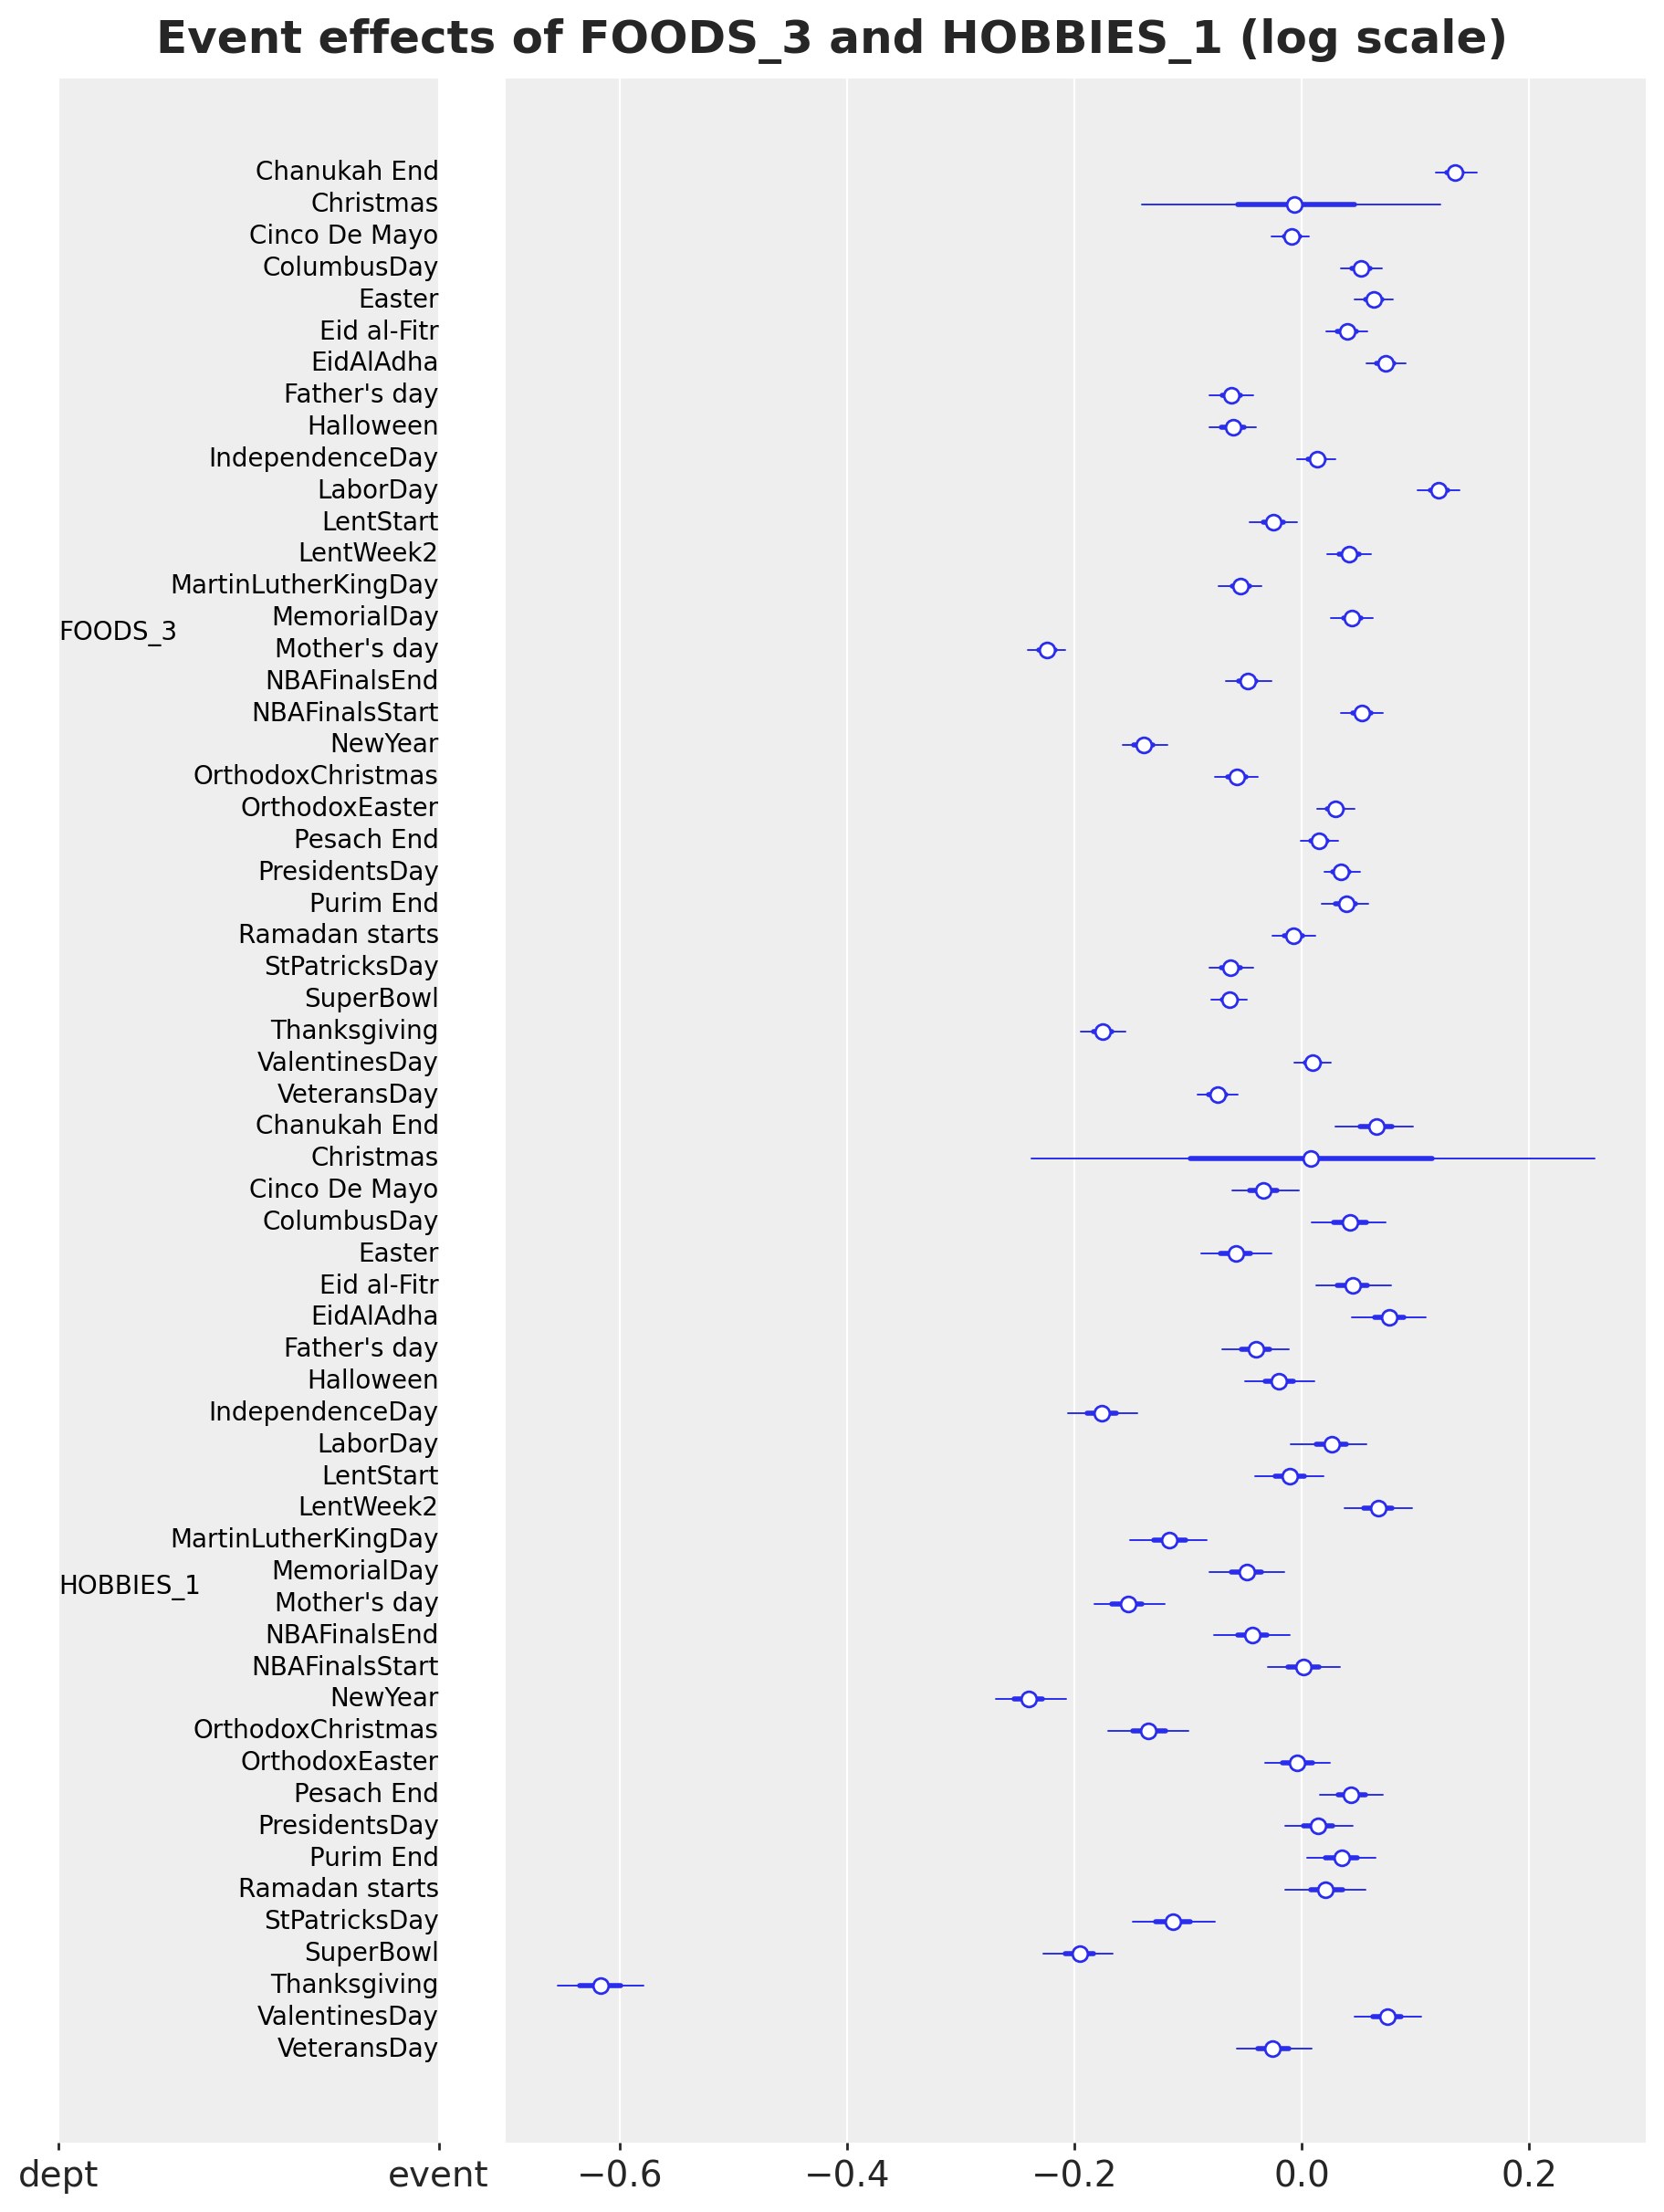

In [23]:
pc = az.plot_forest(
    tree_final,
    var_names=["gamma_event"],
    coords={"dept": ["FOODS_3", "HOBBIES_1"]},
    combined=True,
    labels=["dept", "event"],
    figure_kwargs={"figsize": (9, 12)},
)
pc.viz["figure"].item().suptitle(
    "Event effects of FOODS_3 and HOBBIES_1 (log scale)", fontsize=18, fontweight="bold"
);

An event effect is the lift of the event over an ordinary day of the department with the same day of the month. The effects have the expected signs:

- Thanksgiving is about $-0.2$ for FOODS_3 and $-0.6$ for HOBBIES_1, because the stores close early;
- Mother's Day and New Year are negative for both departments;
- Labor Day, Presidents' Day and Columbus Day are positive for FOODS_3.

Christmas has the only wide posterior: the stores are closed, `saled` is zero, and the effect sees only its prior.

### In-sample fit and forecast of the focus items

We return to the seven focus items of the prior predictive check, now with the posterior. `subset_posterior` picks the columns of these series out of the item-level draws, and the seven-series instance of the model gives their in-sample predictive and their forecast through `predict_in_sample()` and `forecast()`.

In [24]:
# The item-level sites and the axis of their series dimension.
ITEM_SITES = {"alpha": -1, "log_phi": -1, "item_walk": -1, "item_dow": -2}


def subset_posterior(posterior: dict, index: np.ndarray) -> dict:
    """Keep the draws of the series in ``index`` for the item-level sites, everything else as is."""
    out = {}

    for name, value in posterior.items():
        if name in ITEM_SITES:
            axis = ITEM_SITES[name] % value.ndim
            out[name] = jnp.take(value, jnp.asarray(index), axis=axis)
        else:
            out[name] = value

    return out


posterior_focus = subset_posterior(posterior_final, focus_index)

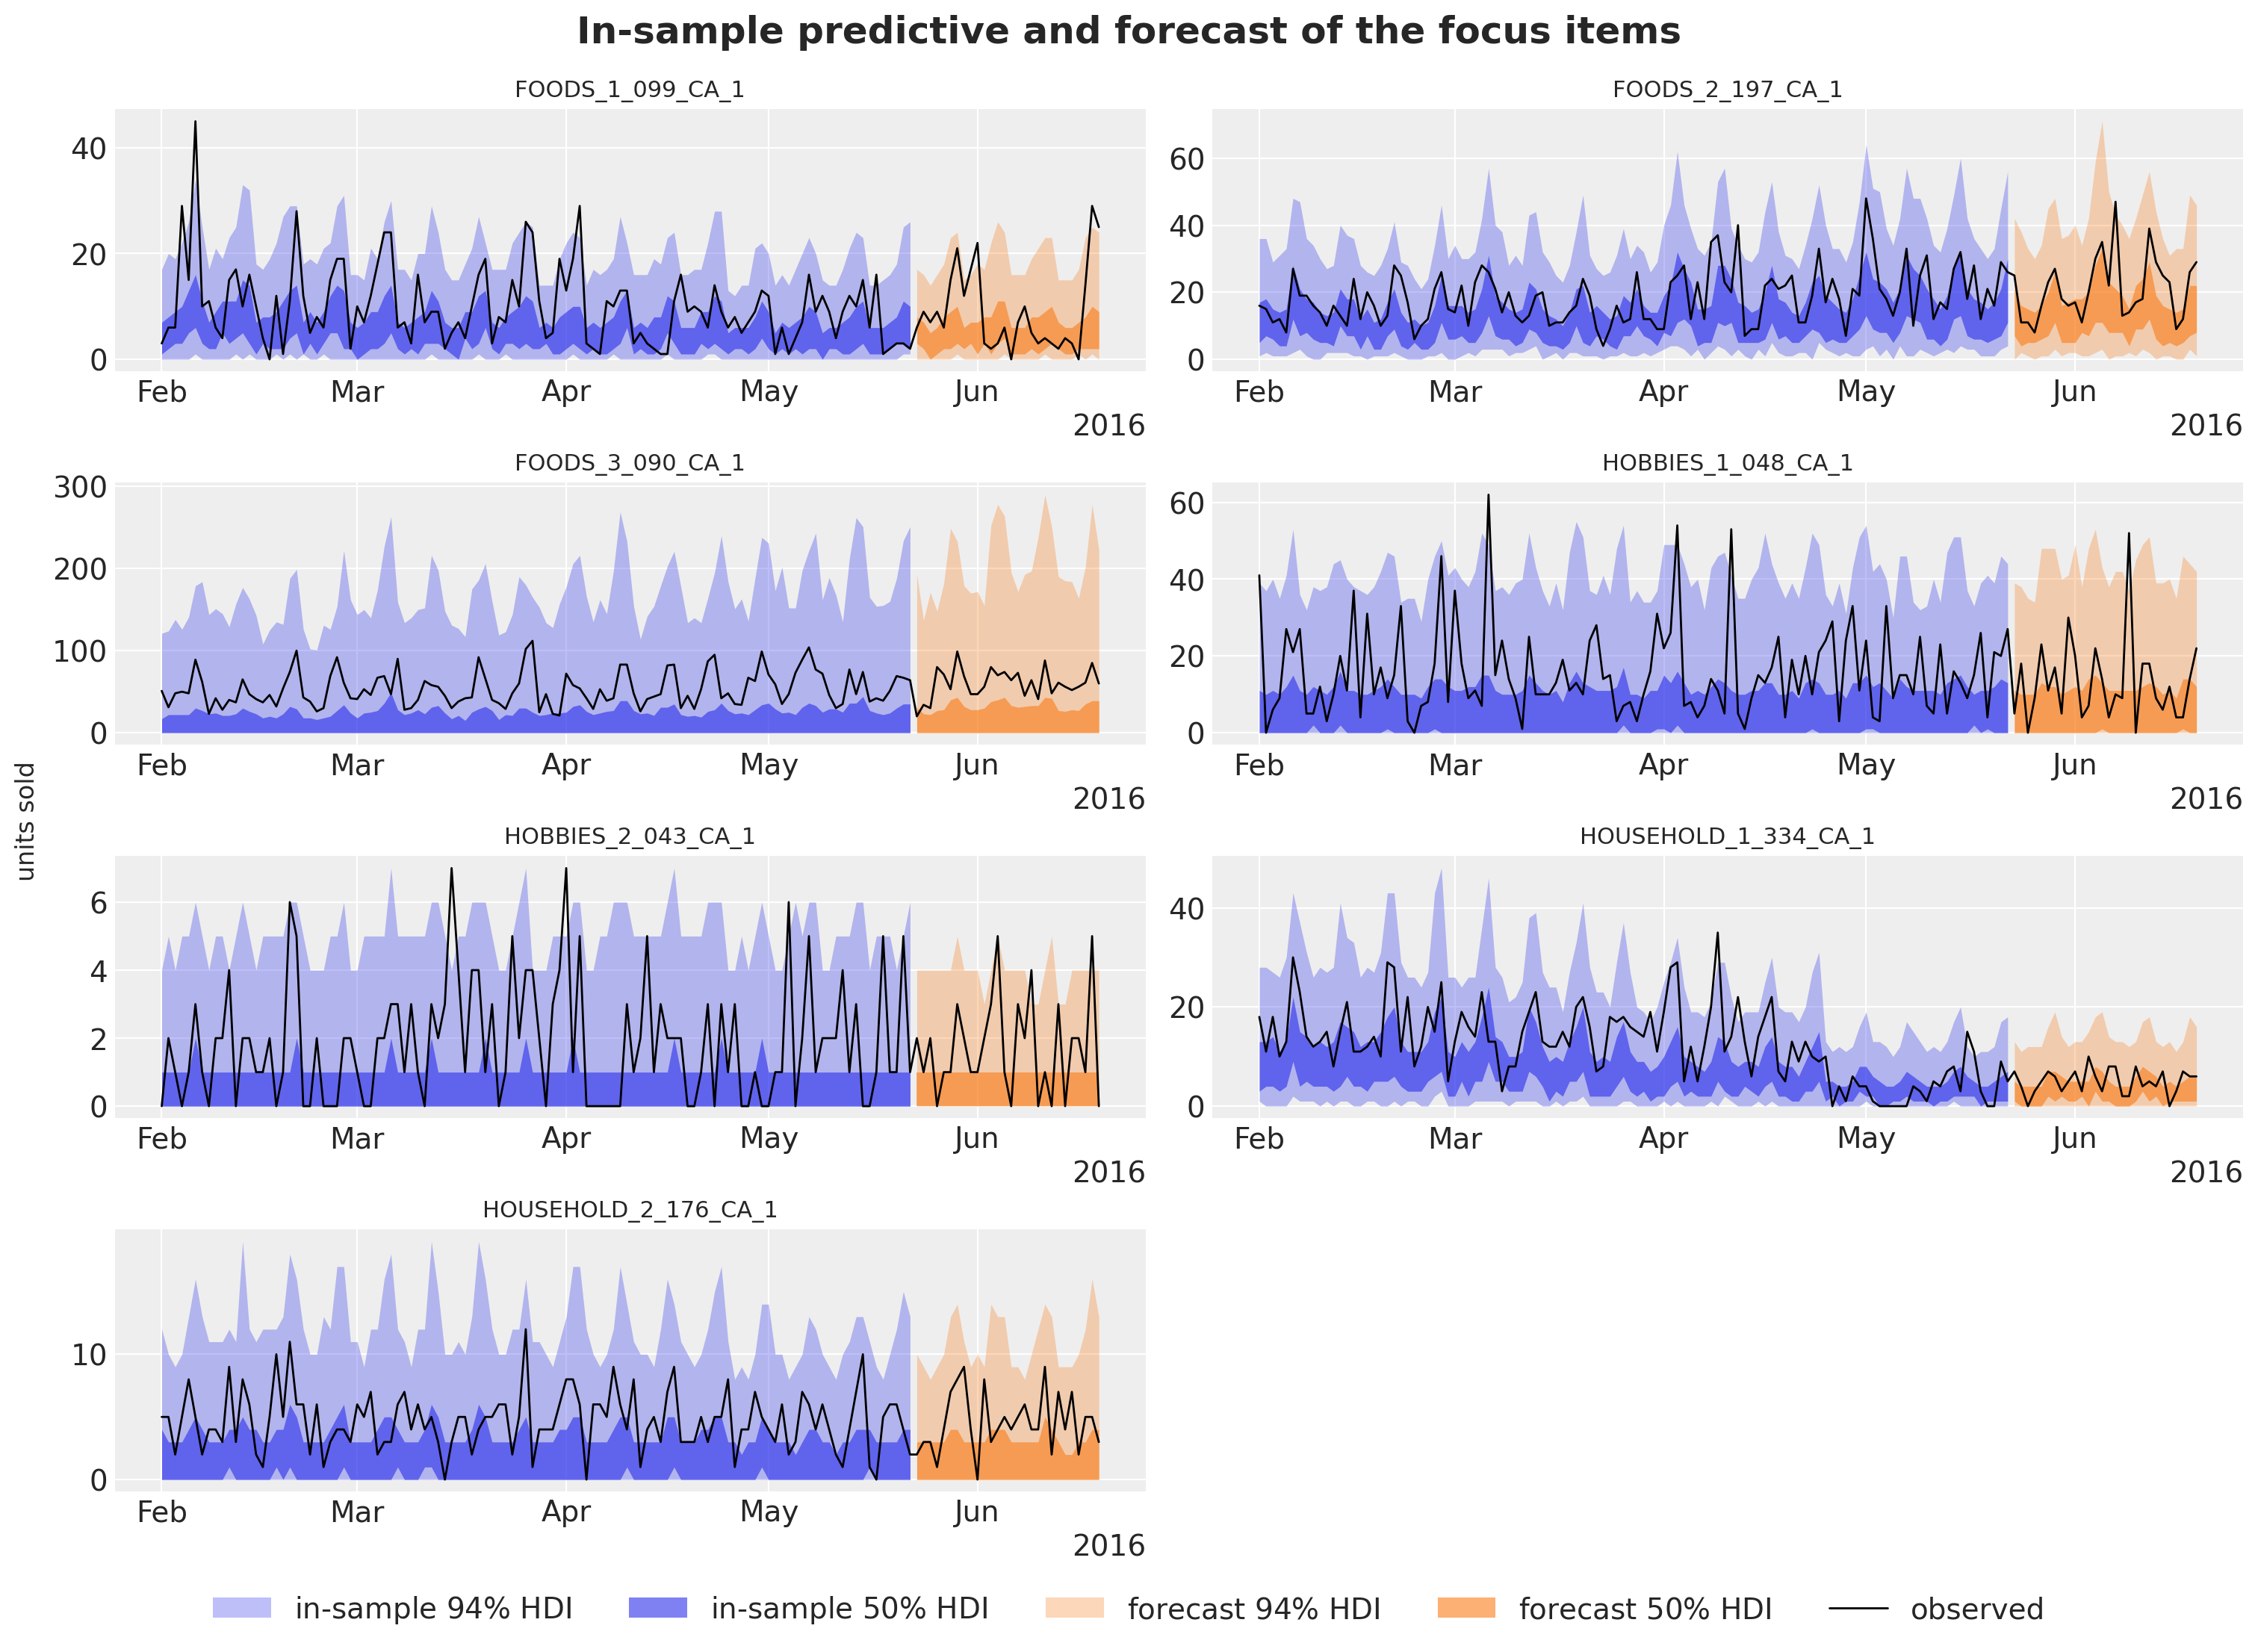

In [25]:
rng_key, key_pp, key_fc = random.split(rng_key, 3)
pp_focus = predict_in_sample(
    key_pp, focus_model, posterior_focus, covariates_focus[:, :HISTORY_DAYS]
)
fc_focus = forecast(
    key_fc, focus_model, posterior_focus, counts_final[:, focus_index], covariates_focus
)

plot_series_panel(
    np.asarray(pp_focus)[:, -16 * 7 :],
    fc_focus,
    sales[plot_start:N_DAYS, focus_index],
    focus_labels,
    date_num[plot_start:N_DAYS_TRAIN],
    date_num[N_DAYS_TRAIN:N_DAYS],
    ylabel="units sold",
    suptitle="In-sample predictive and forecast of the focus items",
)

del pp_focus

The bands now sit on the observed series of all seven items. In the baselines notebook, the department regression of the kit's bottom-up model forecast these best sellers at a fraction of their level; here the item intercept and the block walk get the level right. Two items show the components at work:

- FOODS_3_090 has wide upper tails, the negative binomial dispersion of a series with bursts of high sales;
- HOUSEHOLD_1_334 dropped to a lower level in May, and its forecast follows the last block, not the two-year mean.

The forecast bands are a little wider than the in-sample bands, because the horizon adds one fresh block innovation and fresh store weeks.

## The evaluation window

We now forecast the 28 evaluation days of the competition (`d_1942` to `d_1969`) with the final fit and score the forecast against the top-down baseline, in four steps: we draw the forecast of all series, implement the scores, run the baseline in the same harness and compare the two models.

`forecast_bottom_level` draws the forecast of all 30,490 series in chunks of 50 posterior draws. For each chunk it

- draws the posterior from the guide;
- runs the forecast-only instance of the model for the horizon mean $\mu$ and the dispersion $\phi$ of every series;
- samples the counts with NumPy's negative binomial, whose parameters are the number of successes $\phi$ and the probability $\phi / (\phi + \mu)$: this is the `NegativeBinomial2` of the model.

In [26]:
def forecast_bottom_level(
    rng_key: Array,
    guide: AutoNormal,
    params: dict,
    train_counts: Array,
    full_covariates: Array,
    num_samples: int,
    *,
    chunk: int = 50,
) -> np.ndarray:
    """Draw ``num_samples`` bottom-level forecasts of every series, ``chunk`` posterior draws at a time.

    Each chunk draws the posterior, runs the forecast-only model for the horizon mean and
    dispersion of every series, and samples the negative binomial counts with NumPy.
    """
    model_fc = make_model(
        recent_level(train_counts, full_covariates[1][: train_counts.shape[0]]),
        forecast_only=True,
    )
    n_days = full_covariates.shape[1] - train_counts.shape[0]
    draws = np.empty((num_samples, n_days, train_counts.shape[1]), dtype=np.float32)
    generator = np.random.default_rng(int(rng_key[1]))

    for start in range(0, num_samples, chunk):
        key_post, key_pred = random.split(random.fold_in(rng_key, start))
        posterior = draw_posterior(key_post, guide, params, min(chunk, num_samples - start))
        pred = Predictive(model_fc, posterior, return_sites=["mean_future", "concentration"])(
            key_pred, full_covariates, train_counts
        )
        mean = np.asarray(pred["mean_future"], dtype=np.float64)  # (chunk, horizon, series)
        concentration = np.asarray(pred["concentration"], dtype=np.float64)[:, None, :]
        draws[start : start + mean.shape[0]] = generator.negative_binomial(
            concentration, concentration / (concentration + mean)
        )

    return draws

In [27]:
# 500 bottom-level draws of the evaluation window: (draw, day, series).
rng_key, key_fc = random.split(rng_key)
start = perf_counter()
bottom_final = forecast_bottom_level(
    key_fc, guide_final, svi_final.params, counts_final, covariates_final, 500
)
time_fc_final = perf_counter() - start

print(f"bottom-level draws {bottom_final.shape} (draw, day, series)")

bottom-level draws (500, 28, 30490) (draw, day, series)


The draws are bottom-level counts. To score them we implement the scores of *Scoring at every level*:

- `m5_weights` computes the weights $w_s$ from the dollar sales of the 28 days before the origin, with the price set to zero on the days without a listed price;
- `m5_scales` computes the scales $\sigma_s$ from the training series, as the kit's `get_metric_scale("pl", ...)` does;
- `aggregate_transform` sums the draws and the truth to the 42,840 series with the summation matrix;
- `ws_crps_level` and `coverage_level` compute the WS-CRPS and the coverage of one level, and `m5_metrics` collects them for a forecast origin, in the form that `evaluate_forecast()` here and `backtest()` later take;
- `ws_pinball` computes the metric of the competition, the **weighted scaled pinball loss** (WSPL) at its nine quantiles, which places the models on the published leaderboard.

In [28]:
# (days, series): the shelf price, zero on the days without a listed price.
price_filled = np.nan_to_num(price, nan=0.0)


def m5_weights(t1: int) -> np.ndarray:
    """Dollar-sales share of every aggregate over the 28 days before ``t1``, normalized per level."""
    dollars = (sales[t1 - 28 : t1] * price_filled[t1 - 28 : t1]).sum(0) @ agg_matrix
    weights = np.empty_like(dollars)

    for level_slice in level_slices.values():
        weights[level_slice] = dollars[level_slice] / dollars[level_slice].sum()

    return weights


def m5_scales(y: np.ndarray) -> np.ndarray:
    """Mean absolute lag-1 difference of every column of ``y`` over its active period.

    The active period starts at the first nonzero value; the jump from zero on that day is
    excluded, the sum of absolute differences is clamped at one and divided by the number of
    active days minus one (the kit's ``get_metric_scale("pl", ...)``).
    """
    duration, n_columns = y.shape
    active = np.maximum((np.cumsum(y, axis=0) != 0).sum(0), 2)
    start_value = y[duration - active, np.arange(n_columns)]
    lag1_norm = np.abs(np.diff(y, axis=0, prepend=0.0)).sum(0) - np.abs(start_value)
    return np.maximum(lag1_norm, 1.0) / (active - 1)


def aggregate_transform(
    pred: np.ndarray | Array, truth: np.ndarray | Array
) -> tuple[np.ndarray, np.ndarray]:
    """Sum bottom-level draws and truth to the 42,840 aggregates of the 12 M5 levels."""
    n = pred.shape[-1]
    pred_levels = np.asarray(pred, dtype=np.float32).reshape(-1, n) @ agg_matrix
    truth_levels = np.asarray(truth, dtype=np.float32) @ agg_matrix
    return pred_levels.reshape(*pred.shape[:-1], -1), truth_levels


def ws_crps_level(
    pred: Array, truth: Array, *, level_slice: slice, weights: np.ndarray, scales: np.ndarray
) -> Array:
    """Weighted scaled CRPS of one level: weight times mean CRPS over the horizon, over scale."""
    crps = crps_empirical(pred[..., level_slice], truth[..., level_slice]).mean(axis=0)
    return jnp.sum(jnp.asarray(weights) * crps / jnp.asarray(scales))


def coverage_level(pred: Array, truth: Array, *, level_slice: slice, prob: float = 0.94) -> Array:
    r"""Share of the series-days of one level inside the central $94\%$ interval of the draws."""
    tail = (1.0 - prob) / 2.0
    lower, upper = np.quantile(np.asarray(pred[..., level_slice]), [tail, 1.0 - tail], axis=0)
    actual = np.asarray(truth[..., level_slice])
    return jnp.asarray(np.mean((actual >= lower) & (actual <= upper)))


COVERAGE_LEVELS = ["Level1", "Level3", "Level9", "Level12"]


def m5_metrics(t0: int, t1: int, t2: int) -> dict:
    r"""Build the 12 weighted scaled CRPS metrics of a window whose training data ends at ``t1``.

    Four $94\%$ coverage metrics (levels 1, 3, 9 and 12) come along to read the calibration.
    """
    weights = m5_weights(t1)
    scales = m5_scales(sales_agg[:t1])
    metrics: dict[str, Metric] = {
        f"ws_crps_{level}": partial(
            ws_crps_level,
            level_slice=level_slice,
            weights=weights[level_slice],
            scales=scales[level_slice],
        )
        for level, level_slice in level_slices.items()
    }

    for level in COVERAGE_LEVELS:
        metrics[f"coverage_{level}"] = partial(coverage_level, level_slice=level_slices[level])

    return metrics


M5_INTERVALS = np.array([0.5, 0.67, 0.95, 0.99])
M5_QUANTILES = np.sort(
    np.concatenate([[0.5], (1 - M5_INTERVALS) / 2, (1 + M5_INTERVALS) / 2])
).astype(np.float32)


def ws_pinball(
    pred_levels: np.ndarray, truth_levels: np.ndarray, weights: np.ndarray, scales: np.ndarray
) -> float:
    """M5 WSPL: pinball loss at the nine competition quantiles, weighted, scaled, mean over levels."""
    quantiles = np.quantile(pred_levels, M5_QUANTILES, axis=0)
    error = quantiles - truth_levels[None]
    u = M5_QUANTILES[:, None, None]
    per_series = (np.where(error <= 0, -u, 1 - u) * error).mean(axis=(0, 1))
    level_scores = [
        np.sum(weights[level_slice] * per_series[level_slice] / scales[level_slice])
        for level_slice in level_slices.values()
    ]

    return float(np.mean(level_scores))

In [29]:
truth_holdout = sales[N_DAYS_TRAIN:N_DAYS]
holdout_metrics = m5_metrics(0, N_DAYS_TRAIN, N_DAYS)
weights_holdout = m5_weights(N_DAYS_TRAIN)
scales_holdout = m5_scales(sales_agg[:N_DAYS_TRAIN])

# Sum the draws to the 42,840 series, score them, and keep the total and the stores for the plots.
pred_levels, truth_levels = aggregate_transform(bottom_final, truth_holdout)
scores_final = evaluate_forecast(pred_levels, truth_levels, metrics=holdout_metrics)
wspl_final = ws_pinball(pred_levels, truth_levels, weights_holdout, scales_holdout)
level1_final = pred_levels[..., 0]
level3_final = pred_levels[..., level_slices["Level3"]]
del bottom_final, pred_levels

### The baseline in the same harness

We re-run the kit's top-down model in this notebook, with the same windows and the same number of draws, so that the comparison is exact. It is a StudentT regression on the log of the total sales with a trend, weekday and day-of-month effects, and it splits the forecast of the total to the items with their last-28-day shares and Poisson noise. Its covariates are those of the baselines notebook: the time in years, the weekday index and the 31 day-of-month dummies, one row per day.

`forecast_fn_top_down` fits the model and draws its bottom-level forecast. It has the signature of a `backtest()` forecast function, so the backtest below reuses it. The other two baselines are quoted from the baselines notebook: on this window the middle-out model scored 0.634 and the bottom-up model 0.728.

In [30]:
day_of_month = np.asarray(dom_table)  # (days,): 0 to 30, the column the state space model reads
covariates_top = jnp.asarray(  # (days, 33)
    np.column_stack(
        [
            np.arange(N_DAYS, dtype=np.float32) / 365.0,  # column 0: time in years
            calendar_df["dow"].to_numpy()[:N_DAYS].astype(np.float32),  # column 1: weekday
            np.stack([(day_of_month == day).astype(np.float32) for day in range(31)], axis=-1),
        ]
    )
)


def top_down_model(covariates: Array, data: Array | None = None) -> None:
    """Kit model 1: trend, weekday and day-of-month effects on the log of the total sales."""
    h = Horizon.from_data(covariates, data)
    time = covariates[:, 0]
    dow = covariates[:, 1].astype(jnp.int32)
    feature = covariates[:, 2:]

    bias = numpyro.sample("bias", dist.Normal(0.0, 10.0))
    trend = numpyro.sample("trend", dist.LogNormal(-2.0, 1.0))
    weight = numpyro.sample(
        "weight", dist.Normal(0.0, 1.0).expand([feature.shape[-1]]).to_event(1)
    )

    with numpyro.plate("day_of_week", 7):
        seasonal = numpyro.sample("seasonal", dist.Normal(0.0, 5.0))

    prediction = bias + trend * time + seasonal[dow] + feature @ weight
    dof = numpyro.sample("dof", dist.Uniform(1.0, 10.0))
    noise_scale = numpyro.sample("noise_scale", dist.LogNormal(-2.0, 1.0))
    predict(h, dist.StudentT(dof, 0.0, noise_scale), prediction[:, None])


def forecast_fn_top_down(
    rng_key: Array,
    model: ForecastModel,
    train_data: Array,
    train_covariates: Array,
    full_covariates: Array,
    num_samples: int,
    *,
    batch_size: int | None = None,
) -> np.ndarray:
    """Fit the kit's top-down model and split its forecast to the items with Poisson noise."""
    key_fit, key_post, key_fc = random.split(rng_key, 3)

    # The kit's fit: 1,001 steps of clipped Adam with a tenfold learning-rate decay.
    y = jnp.log(train_data.sum(-1, keepdims=True))
    guide = AutoNormal(model)
    schedule = optax.exponential_decay(0.1, transition_steps=1_001, decay_rate=0.1)
    optimizer = optax.chain(optax.clip_by_global_norm(10.0), optax.adam(schedule))
    svi = SVI(model, guide, optimizer, Trace_ELBO())
    result = svi.run(key_fit, 1_001, train_covariates, y, progress_bar=False)

    # Forecast the total in units and split it to the items with their last-28-day shares.
    posterior = draw_posterior(key_post, guide, result.params, num_samples)
    total = np.exp(np.asarray(forecast(key_fc, model, posterior, y, full_covariates)))
    last_28 = np.asarray(train_data[-28:]).sum(0)
    shares = (last_28 / last_28.sum()).astype(np.float32)
    generator = np.random.default_rng(int(train_data.shape[0]))
    draws = np.empty((num_samples, total.shape[1], shares.size), dtype=np.float32)

    for start in range(0, num_samples, 50):
        draws[start : start + 50] = generator.poisson(total[start : start + 50] * shares)

    return draws

In [31]:
# The top-down baseline on the evaluation window: 500 draws, summed to the levels and scored.
rng_key, key_top = random.split(rng_key)
start = perf_counter()
bottom_top = forecast_fn_top_down(
    key_top, top_down_model, sales_train, covariates_top[:N_DAYS_TRAIN], covariates_top, 500
)
time_top_fc = perf_counter() - start

pred_levels, _ = aggregate_transform(bottom_top, truth_holdout)
scores_top = evaluate_forecast(pred_levels, truth_levels, metrics=holdout_metrics)
wspl_top = ws_pinball(pred_levels, truth_levels, weights_holdout, scales_holdout)
level1_top = pred_levels[..., 0]
del bottom_top, pred_levels

### Comparing the two models

The figure compares the two models on the evaluation window: the WS-CRPS by level, the gain of the state space model at every level, the means over the 12 levels of the WS-CRPS and of the WSPL, and the $94\%$ coverage at four levels. `ws_crps_mean` averages the 12 level scores of a model.

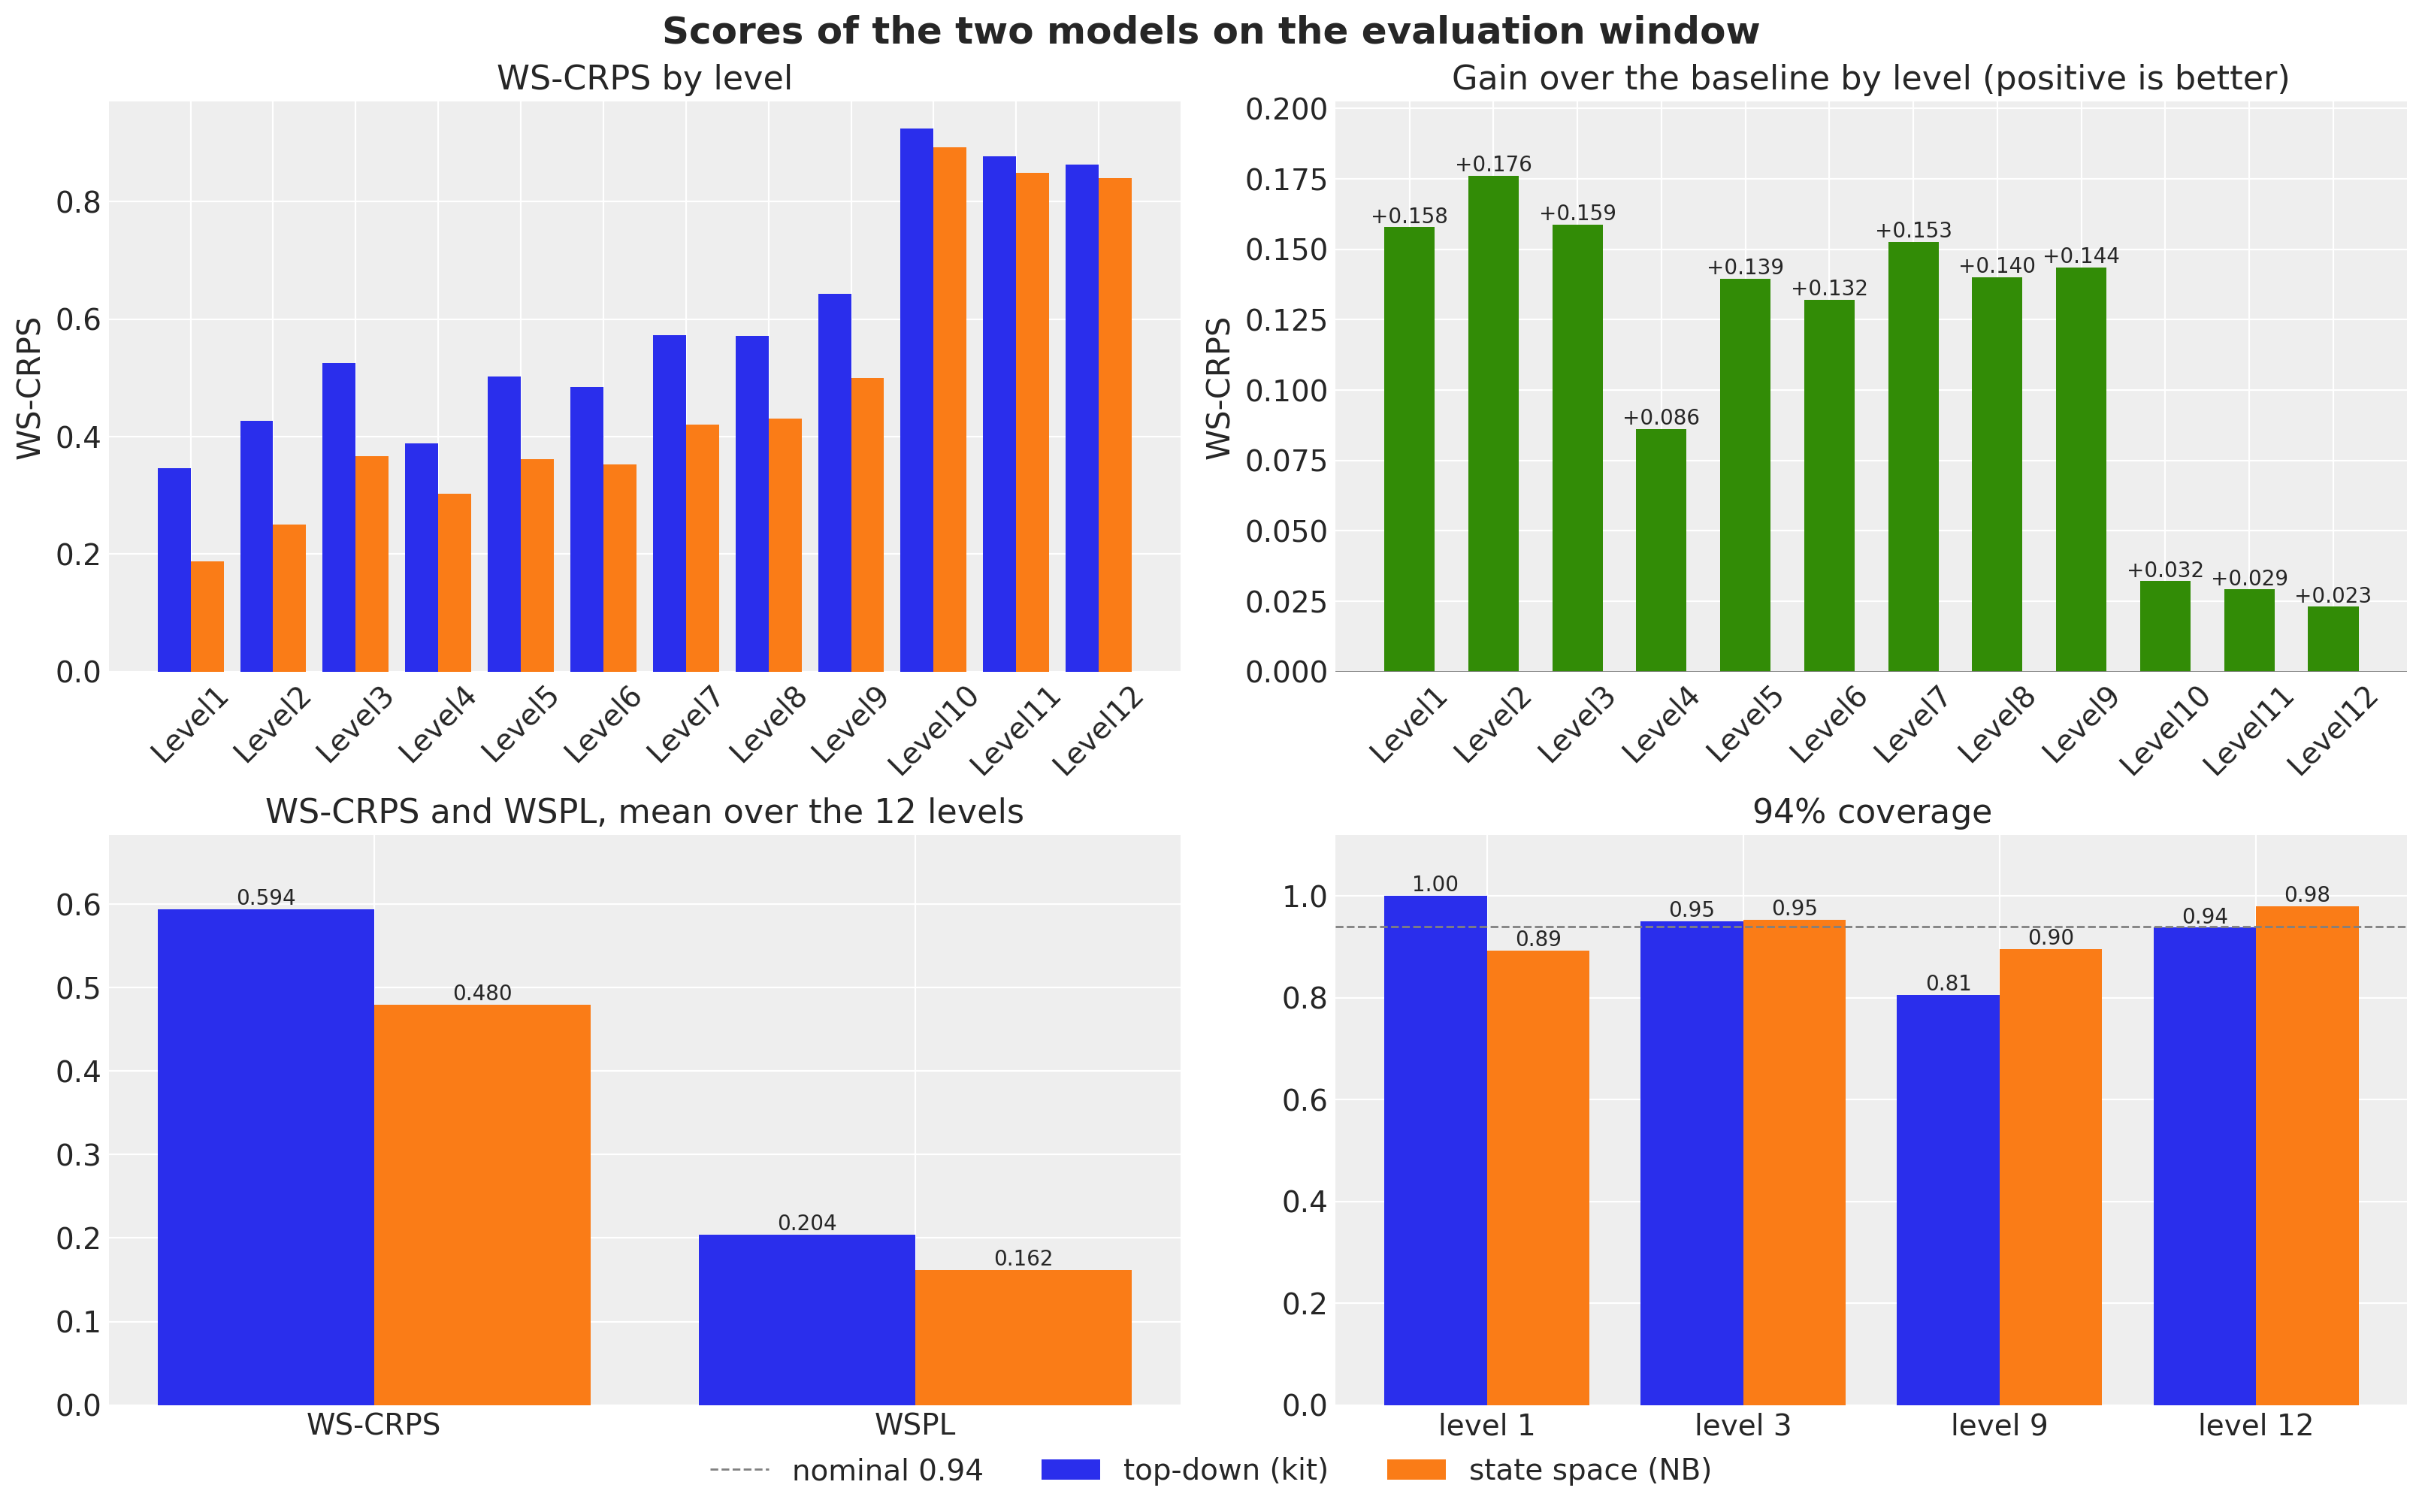

In [32]:
def ws_crps_mean(scores: dict) -> float:
    """Mean of the 12 level scores of an ``evaluate_forecast`` result."""
    return float(np.mean([scores[f"ws_crps_{level}"] for level in LEVELS]))


scores = {"top-down (kit)": (scores_top, wspl_top), "state space (NB)": (scores_final, wspl_final)}

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 10), layout="constrained")
width = 0.4

# Top left: the per-level scores.
x = np.arange(len(LEVELS))

for k, (name, (level_scores, _)) in enumerate(scores.items()):
    values = [level_scores[f"ws_crps_{level}"] for level in LEVELS]
    axes[0, 0].bar(x + (k - 0.5) * width, values, width, label=name)

axes[0, 0].set_xticks(x, list(LEVELS), rotation=45)
axes[0, 0].set(title="WS-CRPS by level", ylabel="WS-CRPS")

# Top right: the gain of the state space model over the baseline, level by level.
gains = [
    float(scores_top[f"ws_crps_{level}"] - scores_final[f"ws_crps_{level}"]) for level in LEVELS
]
bars = axes[0, 1].bar(x, gains, 0.6, color="C2")
axes[0, 1].bar_label(bars, fmt="%+.3f", fontsize=10)
axes[0, 1].axhline(0.0, color="gray", lw=1)
axes[0, 1].set_xticks(x, list(LEVELS), rotation=45)
axes[0, 1].set(title="Gain over the baseline by level (positive is better)", ylabel="WS-CRPS")
axes[0, 1].margins(y=0.15)

# Bottom left: the mean over the levels and the competition's pinball loss.
x = np.arange(2)

for k, (name, (level_scores, wspl)) in enumerate(scores.items()):
    bars = axes[1, 0].bar(
        x + (k - 0.5) * width, [ws_crps_mean(level_scores), wspl], width, label=name
    )
    axes[1, 0].bar_label(bars, fmt="%.3f", fontsize=10)

axes[1, 0].set_xticks(x, ["WS-CRPS", "WSPL"])
axes[1, 0].set(title="WS-CRPS and WSPL, mean over the 12 levels")
axes[1, 0].margins(y=0.15)

# Bottom right: the coverage of the central 94% interval at four levels.
x = np.arange(len(COVERAGE_LEVELS))

for k, (name, (level_scores, _)) in enumerate(scores.items()):
    values = [level_scores[f"coverage_{level}"] for level in COVERAGE_LEVELS]
    bars = axes[1, 1].bar(x + (k - 0.5) * width, values, width, label=name)
    axes[1, 1].bar_label(bars, fmt="%.2f", fontsize=10)

axes[1, 1].axhline(0.94, color="gray", ls="--", lw=1, label="nominal 0.94")
axes[1, 1].set_xticks(x, [level.replace("Level", "level ") for level in COVERAGE_LEVELS])
axes[1, 1].set(title=r"$94\%$ coverage", ylim=(0.0, 1.12))
handles, labels = axes[1, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=3)
fig.suptitle("Scores of the two models on the evaluation window", fontsize=18, fontweight="bold");

The state space model wins on the evaluation window:

- WS-CRPS: 0.480 against 0.594, $19\%$ better;
- WSPL: 0.162 against 0.204, where the winner of the uncertainty competition scored 0.154;
- every level: by 0.13 to 0.18 at the aggregate levels except the category level (level 4, by 0.086), and by 0.023 to 0.032 at the three item levels.

The 28 evaluation days run from May 23 to June 19 and contain a full turn of the month, where the day-of-month pattern and the SNAP days of the three states act.

The coverage panel shows the calibration:

- **Total (level 1).** The top-down band covers every day, so it is too wide, and the CRPS pays for that. The state space band covers $89\%$ of the days, a little below the nominal $94\%$; the next figure shows both bands.
- **Stores (level 3).** Both models are at 0.95.
- **Store-departments (level 9).** The state space model is at 0.90, the top-down model at 0.81.
- **Items (level 12).** The negative binomial is a little wide at 0.98, the top-down model is at 0.94.

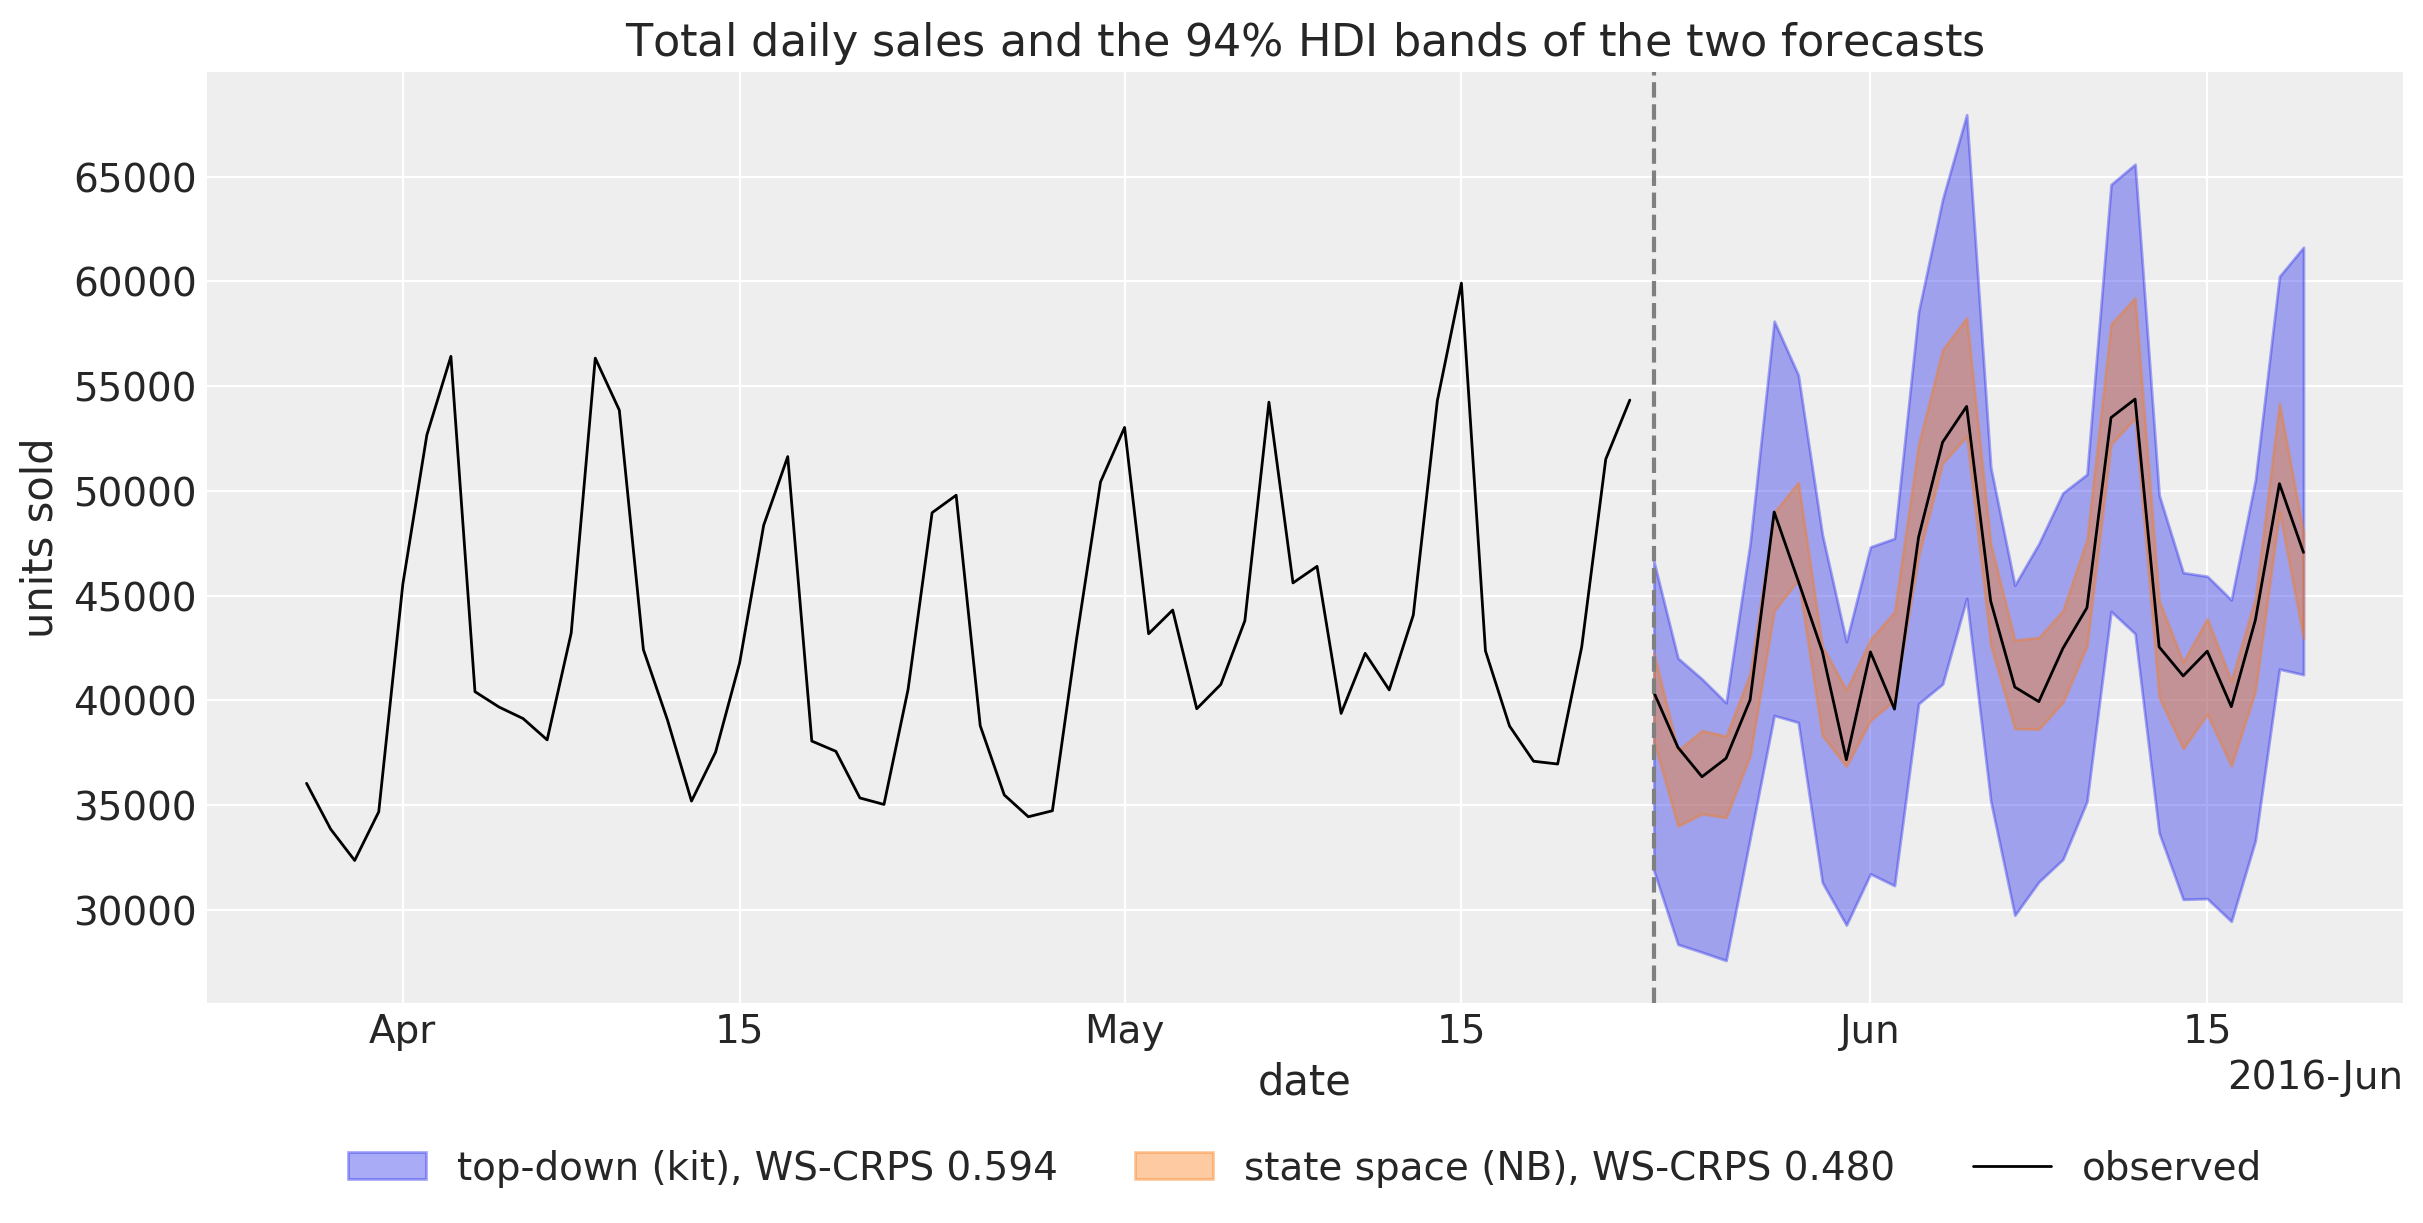

In [33]:
split_date = date_num[N_DAYS_TRAIN]  # the forecast origin of the evaluation window
zoom_start = N_DAYS_TRAIN - 8 * 7  # the last eight training weeks
x_hist = date_num[zoom_start:N_DAYS_TRAIN]
x_test = date_num[N_DAYS_TRAIN:N_DAYS]
y_total = sales_agg[:, 0]

fig, ax = plt.subplots(figsize=(12, 6))

for k, (name, draws) in enumerate(
    [("top-down (kit)", level1_top), ("state space (NB)", level1_final)]
):
    hdi = az.hdi(draws.T, prob=0.94)
    ax.fill_between(
        x_test,
        hdi[:, 0],
        hdi[:, 1],
        color=f"C{k}",
        alpha=0.4,
        label=f"{name}, WS-CRPS {ws_crps_mean(scores[name][0]):.3f}",
    )

ax.plot(x_hist, y_total[zoom_start:N_DAYS_TRAIN], color="black", lw=1, label="observed")
ax.plot(x_test, y_total[N_DAYS_TRAIN:N_DAYS], color="black", lw=1)
ax.axvline(split_date, color="gray", ls="--")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=3)
ax.set(
    title=rf"Total daily sales and the {hdi_label(0.94)} bands of the two forecasts",
    xlabel="date",
    ylabel="units sold",
);

Both bands follow the weekly pattern of the total and its rise in the first days of June. They differ in width:

- the top-down band is the StudentT noise of a single series fitted over five years, wide enough to hold every day with room to spare;
- the state space band is the sum of 30,490 negative binomial draws whose only common components are the store shocks and the block innovations. The observed total leaves it on three of the 28 days and stays close to its center on the others, so the narrow band wins the level-1 CRPS by 0.16.

A narrow band that sits on the observed total of one window can be luck; the backtest below checks its width on three more windows.

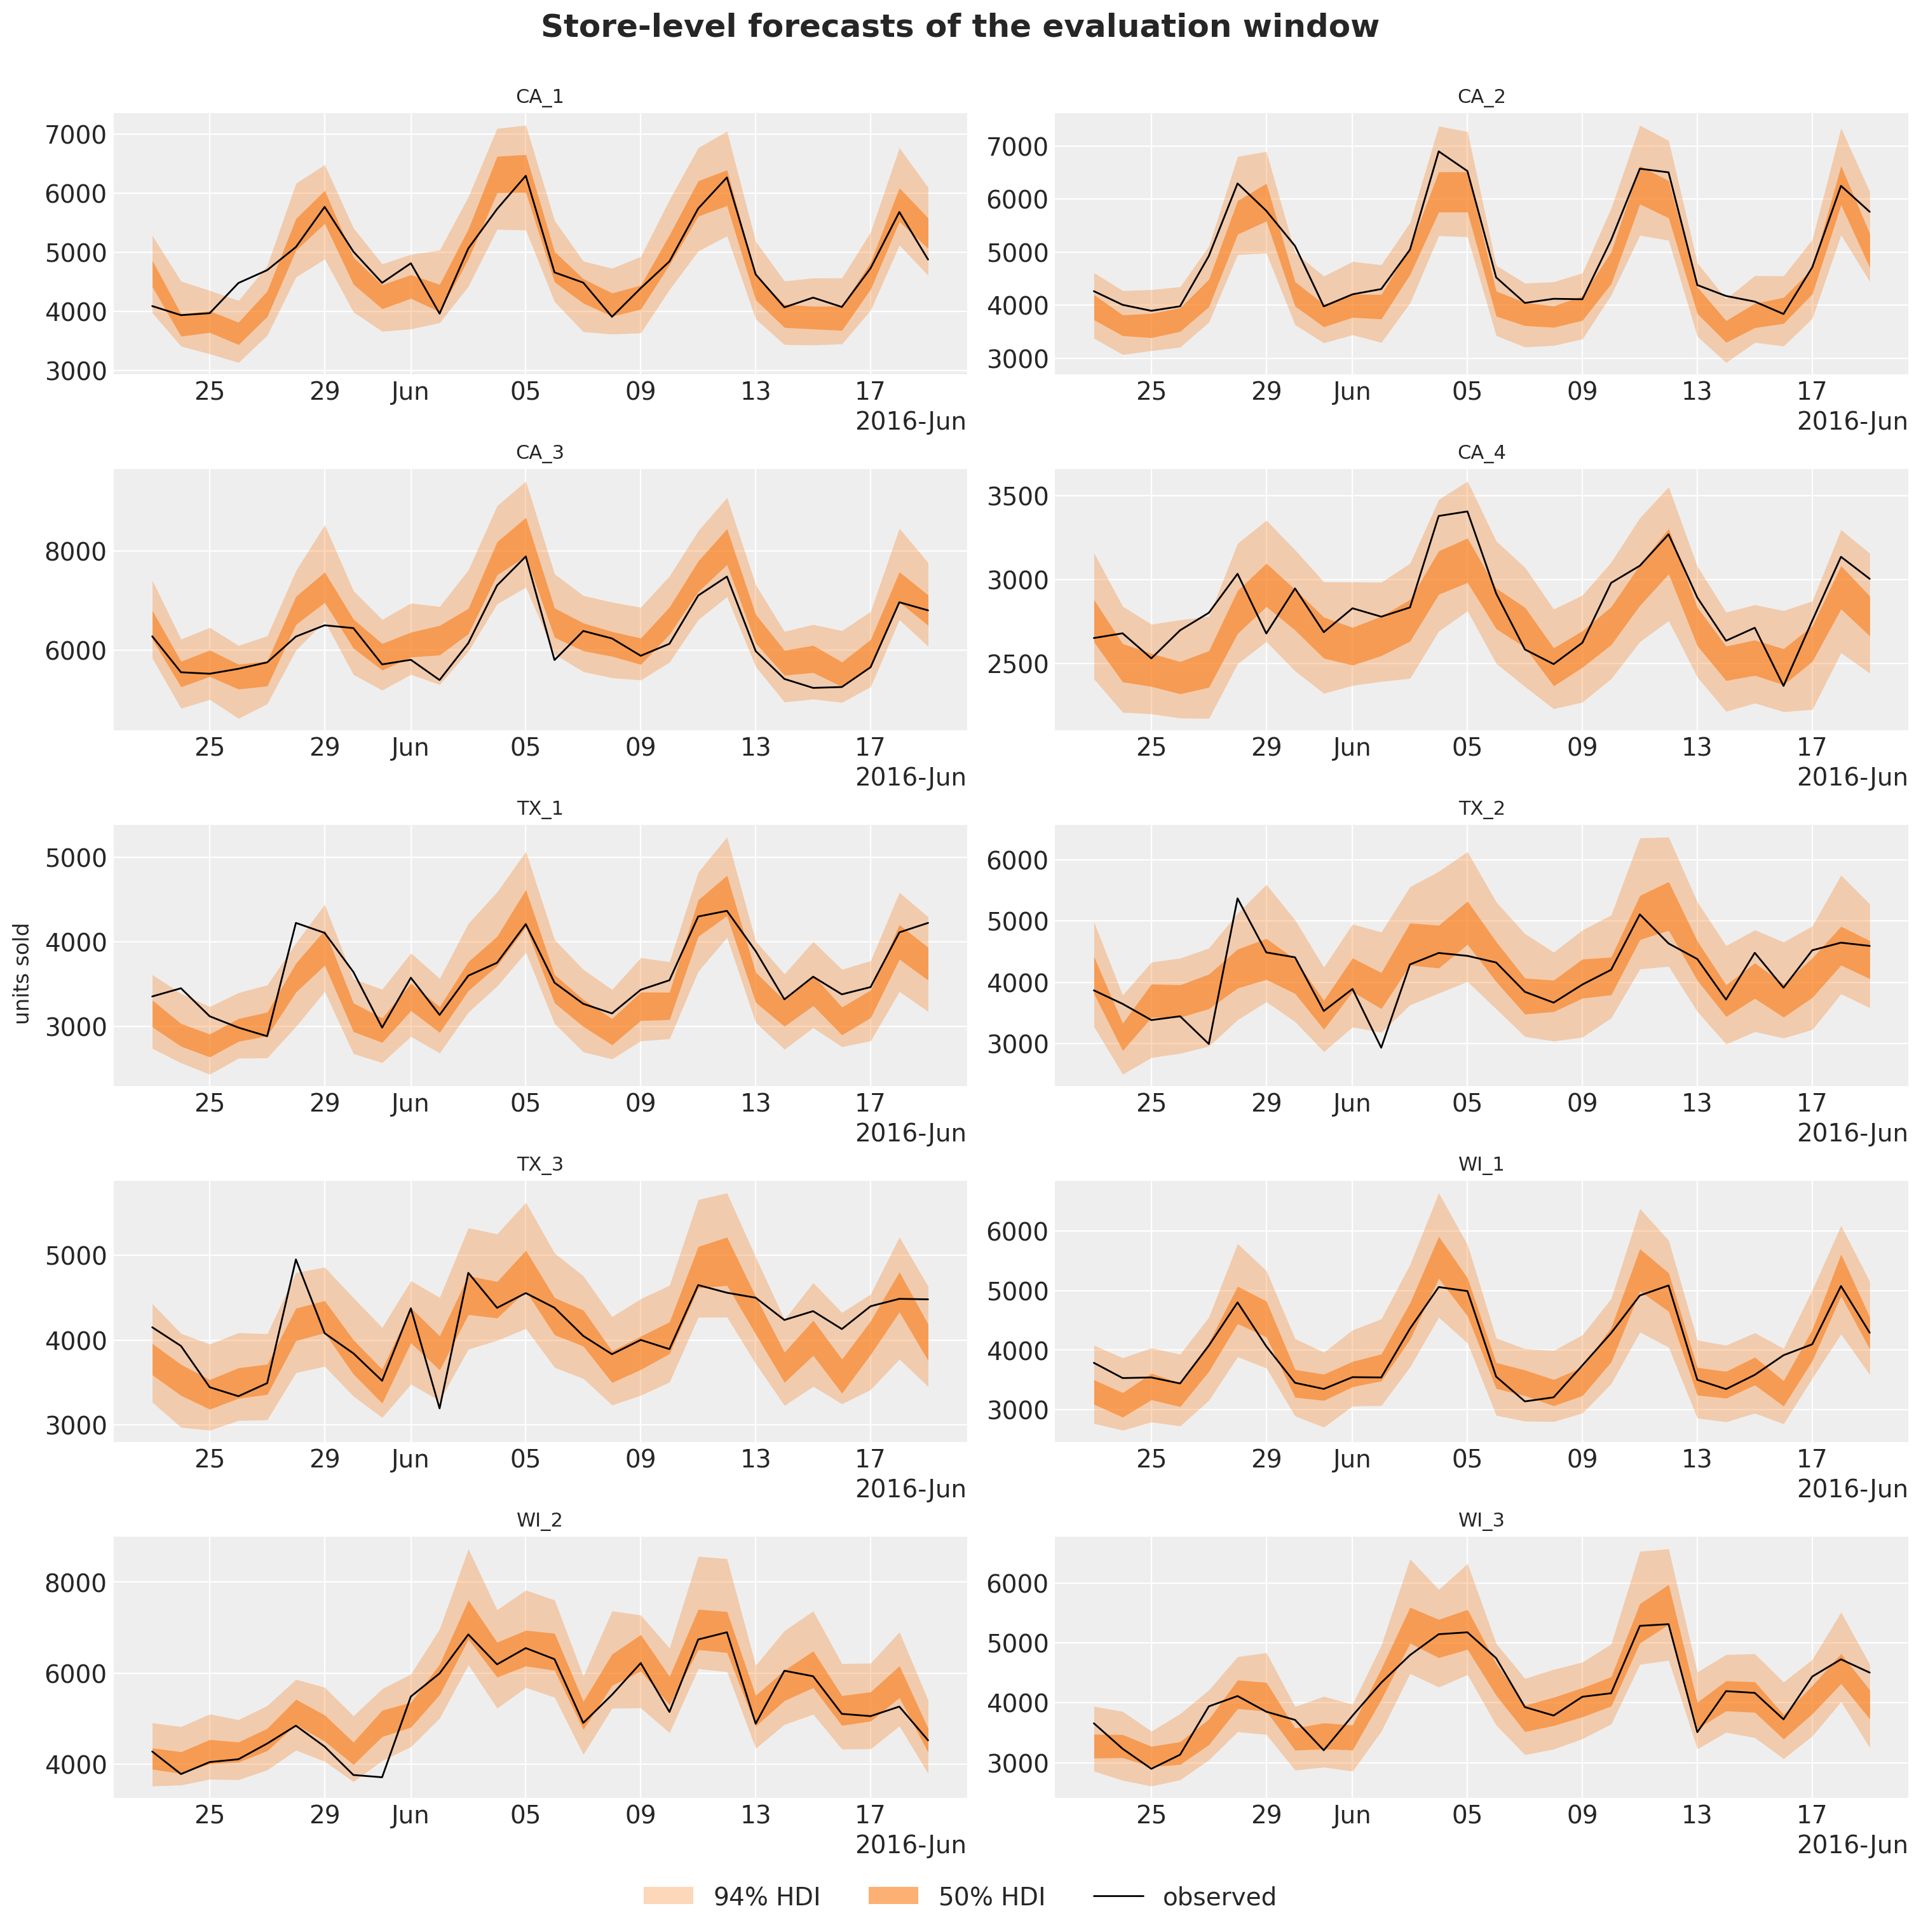

In [34]:
plot_series_panel(
    None,
    level3_final,
    sales_agg[N_DAYS_TRAIN:N_DAYS, level_slices["Level3"]],
    store_ids,
    date_num[plot_start:N_DAYS_TRAIN],
    date_num[N_DAYS_TRAIN:N_DAYS],
    ylabel="units sold",
    suptitle="Store-level forecasts of the evaluation window",
    figsize=(15.0, 14.0),
)

The store-level bands are calibrated, with a coverage of 0.95 at level 3. The weekly store shocks give the sum of the items of a store the common day-to-day variation that a sum of independent item draws lacks (compare the narrow store bands of the kit's bottom-up model in the baselines notebook), and the fresh weeks of the horizon widen the forecast bands by the right amount. WI_2 has the strongest SNAP-day lifts, and its sales rise in the first half of June, on the SNAP days of Wisconsin and at the start of the month. The forecast has that rise, because the calendar is known in advance.

## Backtest on three earlier windows

One window is one draw: the kit's model is sensitive to its SVI seed, and a narrow band can sit on the observed total by luck. We therefore repeat the comparison with `backtest()` on the three windows of the baselines notebook: forecast origins on days 1,843, 1,878 and 1,913, 28 days each, 250 draws. Window 1,878 is the selection window of *Why these components*.

`backtest()` slices the windows, calls a forecast function on each, times it, sums the draws up the hierarchy with `aggregate_transform` and scores every level with `m5_metrics`. The top-down baseline already has its forecast function. For the state space model, `forecast_fn_item` repeats the steps of this notebook on each window: it keeps the last two years of the window, builds the training counts and the origin levels, fits the model and draws the forecast. The origin levels depend on the window, so it builds the model instance itself and ignores the `model` argument of `backtest()`.

In [35]:
def forecast_fn_item(
    rng_key: Array,
    model: ForecastModel,
    train_data: Array,
    train_covariates: Array,
    full_covariates: Array,
    num_samples: int,
    *,
    batch_size: int | None = None,
) -> np.ndarray:
    """`backtest` closure of the item model: build the counts and the levels, fit, forecast."""
    key_fit, key_fc = random.split(rng_key)
    t1 = train_data.shape[0]

    # The last two years of the window: covariates (2, 730, series) and counts (730, series).
    train_covariates = train_covariates[:, -HISTORY_DAYS:]
    train_counts = jnp.rint(train_data[-HISTORY_DAYS:] * train_covariates[1]).astype(jnp.int32)

    model = make_model(recent_level(train_counts, train_covariates[1]))
    guide, result, _ = fit_model(key_fit, model, train_covariates, train_counts)

    return forecast_bottom_level(
        key_fc,
        guide,
        result.params,
        train_counts,
        full_covariates[:, t1 - HISTORY_DAYS :],
        num_samples,
    )

`run_backtest` runs `backtest()` for one model, and `summarize_backtest` reports the mean over the 12 levels and the means over two halves of the hierarchy, because the halves reward different things:

- levels 1 to 9, the aggregates, reward calibrated common uncertainty;
- levels 10 to 12, the items, reward a sharp level for each item.

The table lists the scores of each model and window.

In [36]:
REFERENCE_DAYS = N_DAYS_TRAIN - HORIZON - 2 * 35  # 1,843: the first backtest origin
NUM_SAMPLES_WINDOW = 250
BACKTEST_ORIGINS = [REFERENCE_DAYS + 35 * k for k in range(3)]  # 1,843, 1,878 and 1,913
LEVEL_COLUMNS = [f"metric_ws_crps_{level}" for level in LEVELS]
TOP_LEVELS = LEVEL_COLUMNS[:9]
ITEM_LEVELS = LEVEL_COLUMNS[9:]
COVERAGE_COLUMNS = [f"metric_coverage_{level}" for level in COVERAGE_LEVELS]


def summarize_backtest(results: list, name: str) -> pl.DataFrame:
    """One row per window with the mean WS-CRPS over all levels, levels 1 to 9 and levels 10 to 12."""
    return (
        pl.from_pandas(results_to_dataframe(results))
        .with_columns(
            model=pl.lit(name),
            ws_crps=pl.mean_horizontal(LEVEL_COLUMNS),
            ws_crps_1_9=pl.mean_horizontal(TOP_LEVELS),
            ws_crps_10_12=pl.mean_horizontal(ITEM_LEVELS),
        )
        .select(
            "model",
            "t1",
            "t2",
            "walltime",
            "ws_crps",
            "ws_crps_1_9",
            "ws_crps_10_12",
            *LEVEL_COLUMNS,
            *COVERAGE_COLUMNS,
        )
    )


def run_backtest(
    rng_key: Array,
    name: str,
    model: ForecastModel,
    covariates_model: Array,
    forecast_fn: ForecastFn,
) -> pl.DataFrame:
    """Backtest a model on the kit's three windows (forecast origins 1,843, 1,878 and 1,913)."""
    results = backtest(
        rng_key,
        lambda: model,
        sales_train,
        covariates_model[..., :N_DAYS_TRAIN, :],
        forecast_fn=forecast_fn,
        test_window=HORIZON,
        stride=35,
        min_train_window=REFERENCE_DAYS,
        num_samples=NUM_SAMPLES_WINDOW,
        transform=aggregate_transform,
        per_window_metrics=m5_metrics,
    )

    return summarize_backtest(results, name)


rng_key, key_top, key_item = random.split(rng_key, 3)
backtest_df = pl.concat(
    [
        run_backtest(
            key_top, "top-down (kit)", top_down_model, covariates_top, forecast_fn_top_down
        ),
        run_backtest(key_item, "state space (NB)", final_model, covariates, forecast_fn_item),
    ]
).sort("t1", "model")

# The scores behind the figure: WS-CRPS over all levels and the two halves, and the coverage.
backtest_table = backtest_df.select(
    "model",
    "t1",
    pl.col("ws_crps").round(3).alias("all"),
    pl.col("ws_crps_1_9").round(3).alias("1 to 9"),
    pl.col("ws_crps_10_12").round(3).alias("10 to 12"),
    *[
        pl.col(column).round(2).alias(column.replace("metric_coverage_Level", "cov L"))
        for column in COVERAGE_COLUMNS
    ],
)

with pl.Config(tbl_cols=backtest_table.width):
    display(backtest_table)

model,t1,all,1 to 9,10 to 12,cov L1,cov L3,cov L9,cov L12
str,i64,f64,f64,f64,f64,f64,f64,f64
"""state space (NB)""",1843,0.499,0.393,0.816,0.68,0.95,0.89,0.98
"""top-down (kit)""",1843,0.545,0.457,0.81,1.0,0.96,0.81,0.94
"""state space (NB)""",1878,0.488,0.394,0.771,0.79,0.93,0.88,0.98
"""top-down (kit)""",1878,0.552,0.479,0.769,1.0,0.96,0.81,0.94
"""state space (NB)""",1913,0.499,0.411,0.762,0.75,0.94,0.87,0.98
"""top-down (kit)""",1913,0.569,0.507,0.756,1.0,0.97,0.79,0.93


The figure shows the same scores in four panels: the WS-CRPS per window, the means over the three windows, the per-level scores averaged over the windows, and the $94\%$ coverage at four levels against the nominal 0.94.

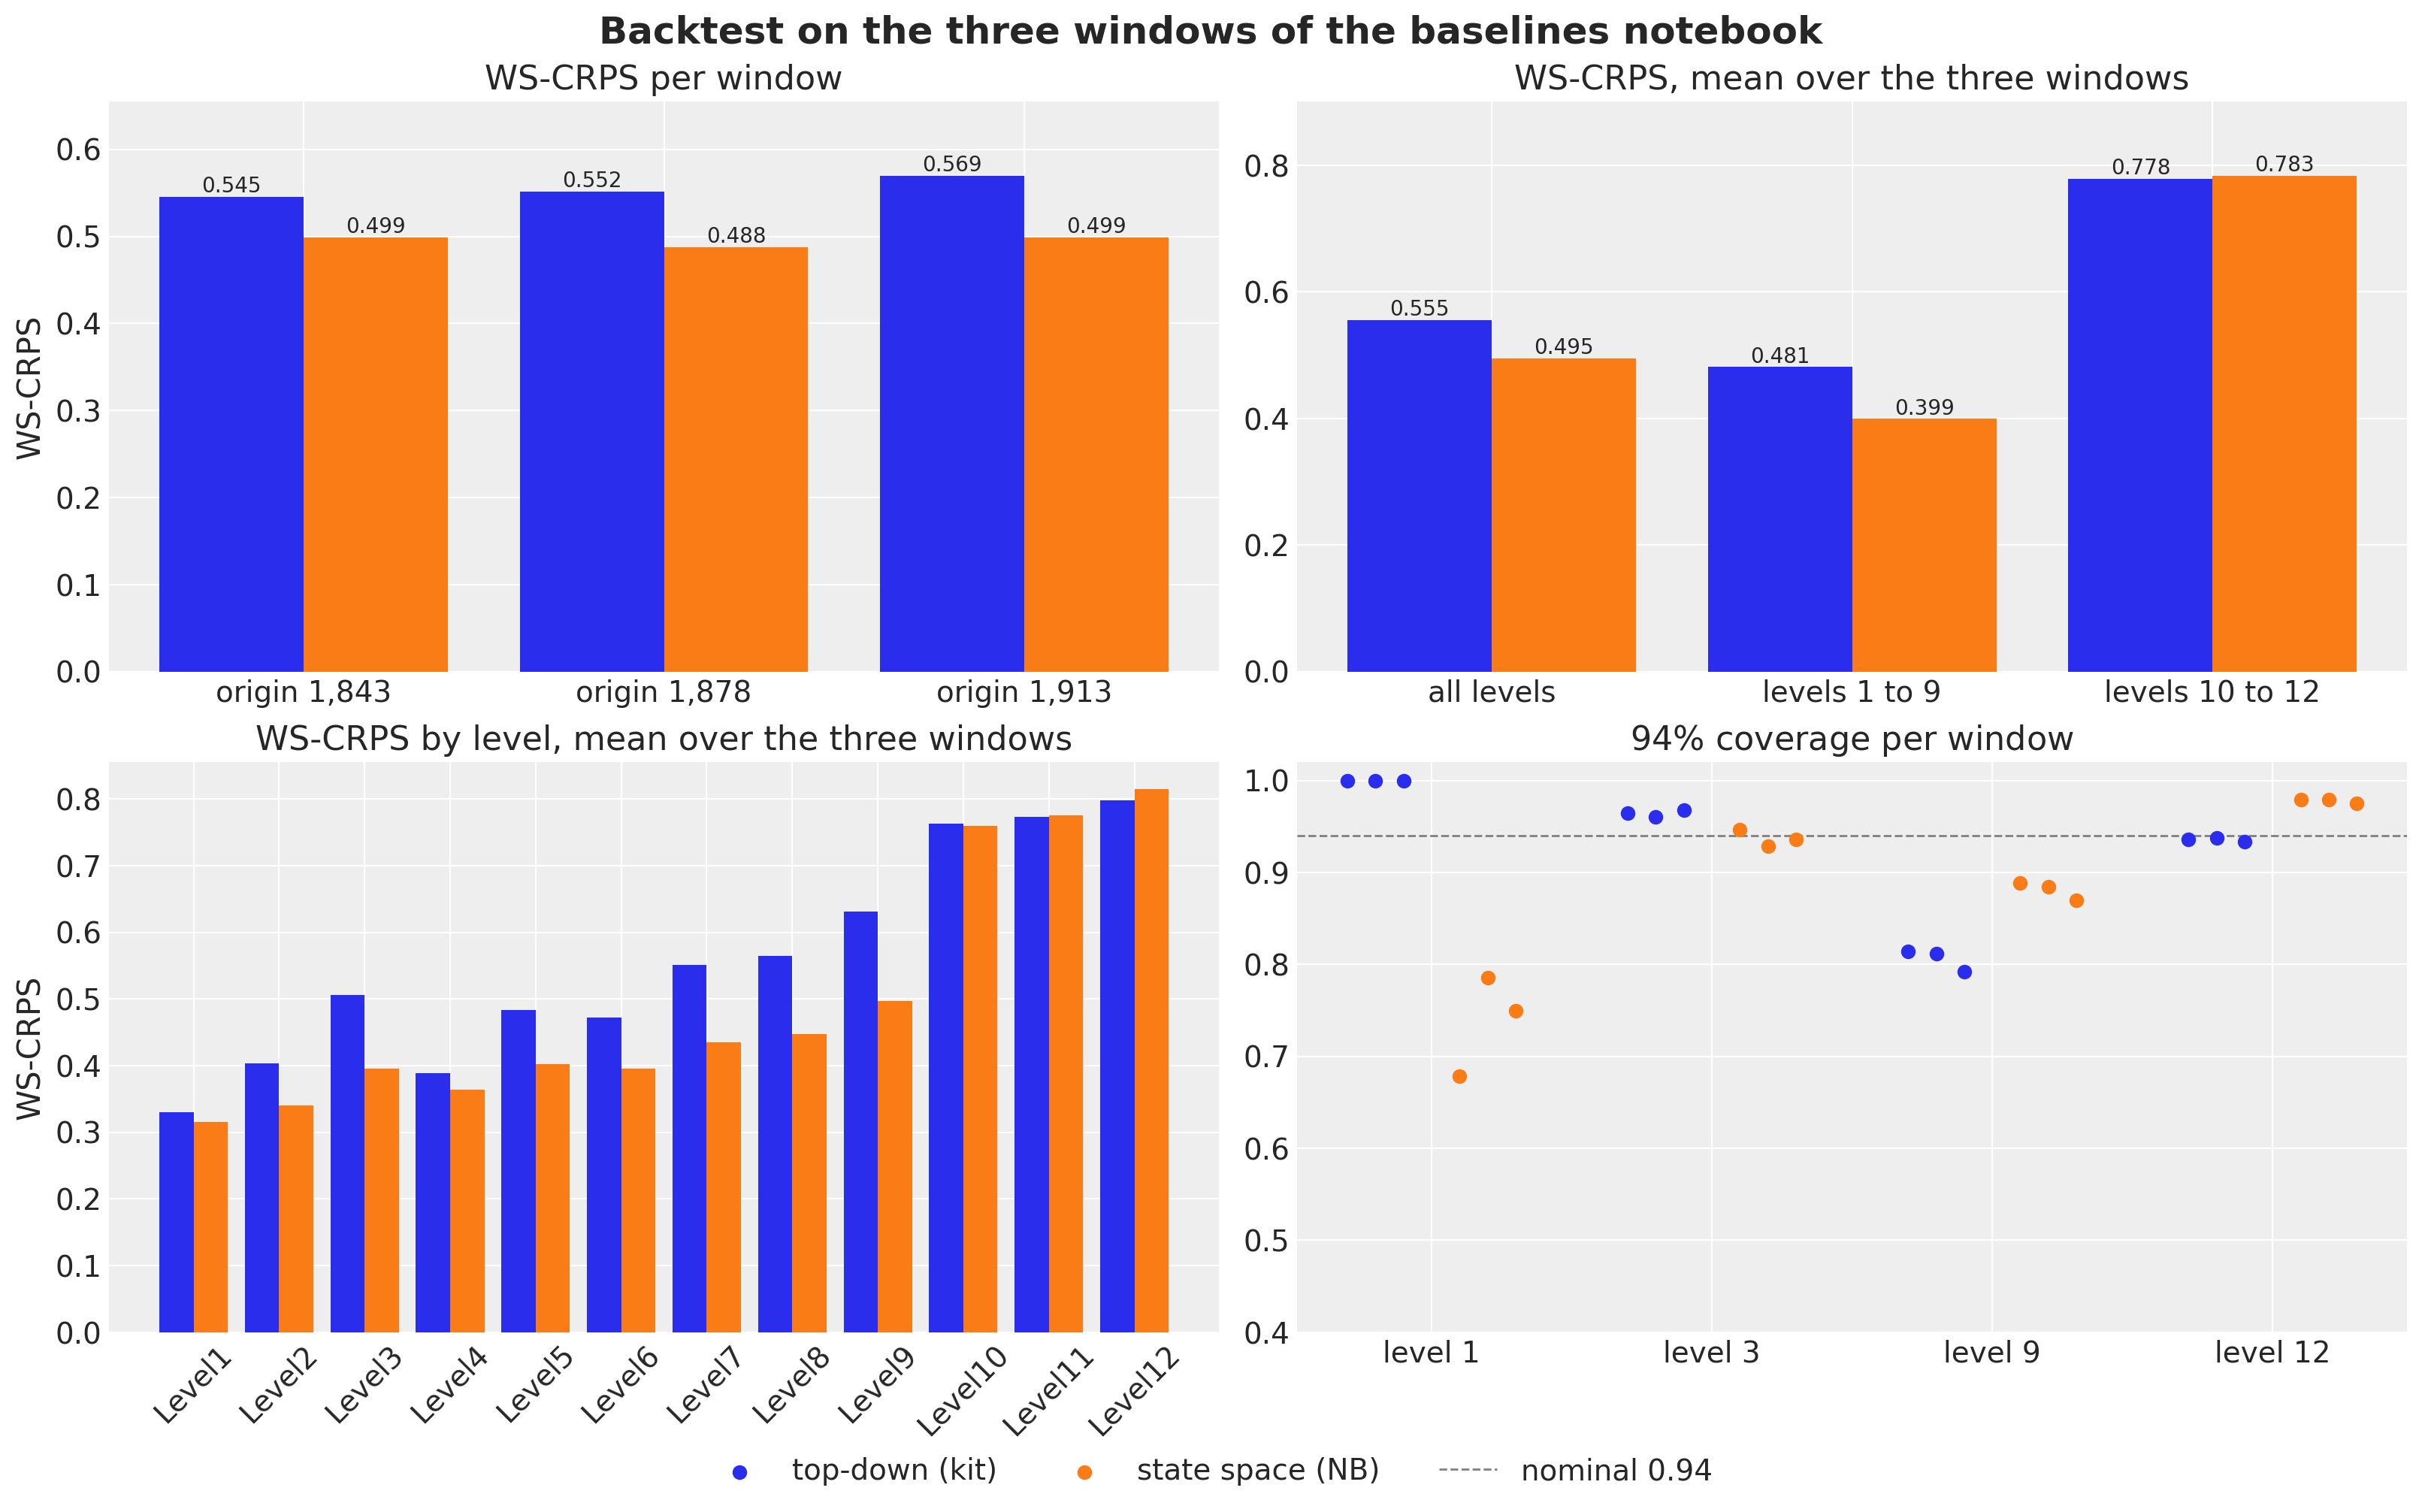

In [37]:
MODELS = ["top-down (kit)", "state space (NB)"]
SUMMARY_COLUMNS = {
    "ws_crps": "all levels",
    "ws_crps_1_9": "levels 1 to 9",
    "ws_crps_10_12": "levels 10 to 12",
}
backtest_mean = backtest_df.group_by("model", maintain_order=True).agg(
    pl.col(*SUMMARY_COLUMNS, *LEVEL_COLUMNS, *COVERAGE_COLUMNS).mean()
)

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 10), layout="constrained")
width = 0.4

# Top left: the headline score per window.
x = np.arange(len(BACKTEST_ORIGINS))

for k, name in enumerate(MODELS):
    rows = backtest_df.filter(pl.col("model").eq(pl.lit(name))).sort("t1")
    bars = axes[0, 0].bar(x + (k - 0.5) * width, rows["ws_crps"].to_numpy(), width, label=name)
    axes[0, 0].bar_label(bars, fmt="%.3f", fontsize=10)

axes[0, 0].set_xticks(x, [f"origin {origin:,}" for origin in BACKTEST_ORIGINS])
axes[0, 0].set(title="WS-CRPS per window", ylabel="WS-CRPS")
axes[0, 0].margins(y=0.15)

# Top right: the means over the three windows, all levels and the two halves.
x = np.arange(len(SUMMARY_COLUMNS))

for k, name in enumerate(MODELS):
    row = backtest_mean.filter(pl.col("model").eq(pl.lit(name)))
    values = row.select(list(SUMMARY_COLUMNS)).to_numpy()[0]
    bars = axes[0, 1].bar(x + (k - 0.5) * width, values, width, label=name)
    axes[0, 1].bar_label(bars, fmt="%.3f", fontsize=10)

axes[0, 1].set_xticks(x, list(SUMMARY_COLUMNS.values()))
axes[0, 1].set(title="WS-CRPS, mean over the three windows")
axes[0, 1].margins(y=0.15)

# Bottom left: the per-level scores, mean over the windows.
x = np.arange(len(LEVELS))

for k, name in enumerate(MODELS):
    row = backtest_mean.filter(pl.col("model").eq(pl.lit(name)))
    values = row.select(LEVEL_COLUMNS).to_numpy()[0]
    axes[1, 0].bar(x + (k - 0.5) * width, values, width, label=name)

axes[1, 0].set_xticks(x, list(LEVELS), rotation=45)
axes[1, 0].set(title="WS-CRPS by level, mean over the three windows", ylabel="WS-CRPS")

# Bottom right: the coverage of the central 94% interval at four levels, one marker per window.
x = np.arange(len(COVERAGE_LEVELS))

for k, name in enumerate(MODELS):
    rows = backtest_df.filter(pl.col("model").eq(pl.lit(name))).sort("t1")

    for j in range(rows.height):
        axes[1, 1].scatter(
            x + (k - 0.5) * width + (j - 1) * 0.1,
            rows[j].select(COVERAGE_COLUMNS).to_numpy()[0],
            color=f"C{k}",
            label=name if j == 0 else None,
            zorder=3,
        )

axes[1, 1].axhline(0.94, color="gray", ls="--", lw=1, label="nominal 0.94")
axes[1, 1].set_xticks(x, [level.replace("Level", "level ") for level in COVERAGE_LEVELS])
axes[1, 1].set(title=r"$94\%$ coverage per window", ylim=(0.4, 1.02))
handles, labels = axes[1, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=3)
fig.suptitle(
    "Backtest on the three windows of the baselines notebook", fontsize=18, fontweight="bold"
);

The backtest confirms the evaluation window. The state space model is ahead on every window, and the gain is at the aggregate levels:

- WS-CRPS per window: 0.499, 0.488 and 0.499, against 0.545, 0.552 and 0.569 for the top-down model, $8\%$ to $12\%$ better;
- levels 1 to 9: 0.399 against 0.481, on average over the windows;
- levels 10 to 12: a draw, 0.783 against 0.778. For a single item, the Poisson split of a well-fitted total is hard to beat.

The gain on the evaluation window ($19\%$) is larger, partly because the kit's model is sensitive to its SVI seed: it fits one 1,941-day series with a StudentT likelihood in 1,001 steps, and its noise scale and degrees of freedom change from seed to seed. On the evaluation window it scored 0.569 in the baselines notebook and between 0.563 and 0.605 across the executions of this notebook (0.594 here).

The coverage panel shows the calibration, level by level:

- total (level 1): the top-down band covers every day of every window, while the state space band covers $68\%$ to $79\%$ of the days, which is too narrow. The only common uncertainty of the 30,490 items is the weekly store shocks and one block innovation, and a mean-field guide understates the posterior uncertainty of the origin level. The $89\%$ of the evaluation window was the better case;
- stores (level 3): the state space model is at 0.93 to 0.95, the top-down model at 0.96 to 0.97, both close to the nominal 0.94;
- store-departments (level 9): the state space model is at 0.87 to 0.89, the top-down model at 0.79 to 0.81;
- items (level 12): the negative binomial is a little wide at 0.98, the top-down model is at 0.93 to 0.94.

## Cost

On a 14-core M4 Pro CPU, the state space model costs two to three minutes per window:

- the fit: 119 seconds for 3,000 SVI steps over 1,500-series minibatches of two years of daily data, a number of steps that a full-batch model of 30,490 series would not reach;
- the forecast: 52 seconds for the 500 bottom-level draws of the evaluation window;
- a backtest window with 250 draws: 136 seconds on average, fit and forecast together.

The top-down model takes 8 to 15 seconds. The wall times of a laptop CPU change with its load from run to run (the final fit took 95 to 148 seconds across the executions of this notebook), so the figure shows the times of this execution, for a fit and forecast on a backtest window (mean over the three) and on the evaluation window. The whole notebook runs in about 13 minutes.

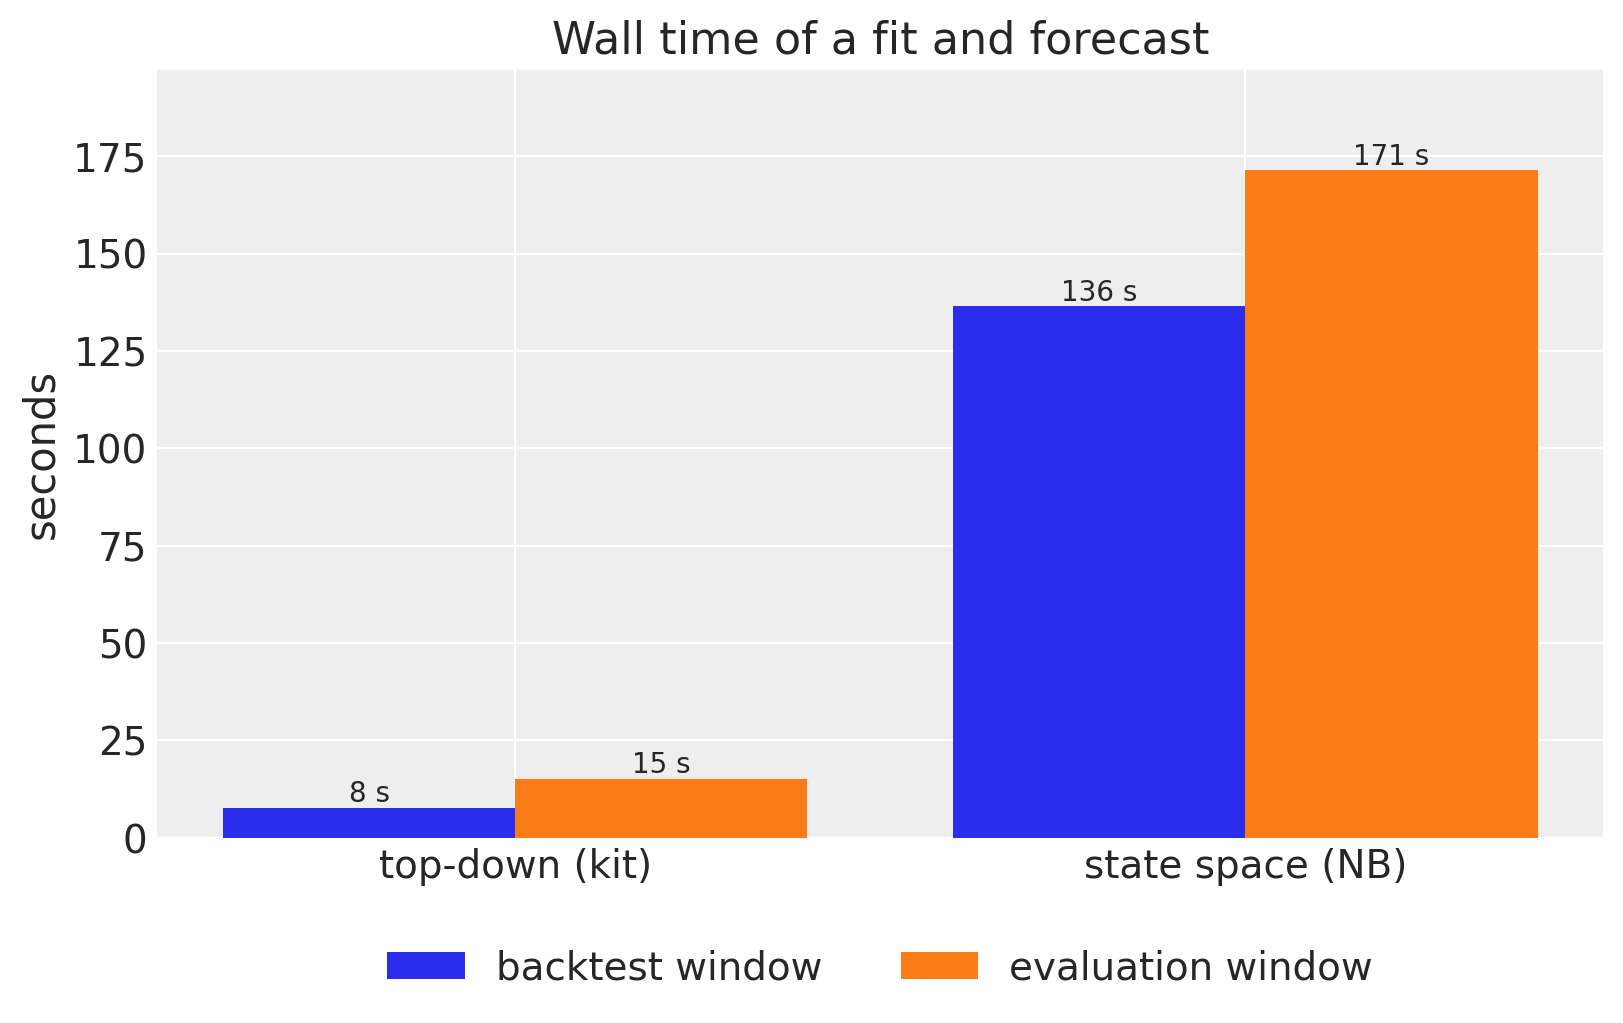

In [38]:
timing = pl.DataFrame(
    {
        "model": MODELS,
        "backtest window": [
            backtest_df.filter(pl.col("model").eq(pl.lit(name)))["walltime"].mean()
            for name in MODELS
        ],
        "evaluation window": [time_top_fc, time_final + time_fc_final],
    }
)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(MODELS))
width = 0.4

for k, column in enumerate(["backtest window", "evaluation window"]):
    bars = ax.bar(x + (k - 0.5) * width, timing[column].to_numpy(), width, label=column)
    ax.bar_label(bars, fmt="%.0f s", fontsize=10)

ax.set_xticks(x, MODELS)
ax.set(title="Wall time of a fit and forecast", ylabel="seconds")
ax.margins(y=0.15)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=2);

## Discussion

A single hierarchical model of all 30,490 M5 series beats the best starter-kit baseline:

- by $19\%$ in WS-CRPS on the evaluation window (0.480 against 0.594), and by $8\%$ to $12\%$ on the three backtest windows;
- in the pinball loss of the competition, from 0.204 to 0.162 (the winner scored 0.154);
- in calibration at the store-department level, with a $94\%$ coverage of 0.87 to 0.90 against 0.79 to 0.81, while both models are calibrated at the store level.

It uses plain NumPyro and the `numpyro_forecast` building blocks:

- `Horizon.from_data` and `predict()` for the train-and-forecast bookkeeping;
- explicit block and week plates for the state space components;
- `AutoNormal` with `create_plates` and `numpyro.subsample` for the minibatches;
- `backtest()` with a `transform` and `per_window_metrics` for the score over the hierarchy;
- `forecast()`, `predict_in_sample()` and `predictions_to_datatree()` for the plots.

What the model selection, the evaluation window and the backtest say about modeling this kind of data:

- **The level process does most of the work.** Intercepts centered on the last-28-day level and an end-anchored block walk that explains the past make 30,490 item models competitive; the other components refine them. The time resolution matters: daily item walks and daily shared walks were tried during development and lost to the baseline, because a mean-field SVI fit lets a daily latent variable absorb noise as level and then carries that level over the horizon.
- **Common shocks are for calibration, not for the score.** The weekly store shocks leave the CRPS unchanged and raise the store-level $94\%$ coverage from 0.70 to 0.95. A score that mixes twelve levels rewards them little; a user of store-level forecasts needs them.
- **The calendar gave the largest gain per line of code.** The day-of-month pattern, the last component added, improves the selection window from 0.517 to 0.490 and the two other backtest windows from 0.511 to 0.498 and from 0.504 to 0.498. During development we also tried a neural network correction in the style of [part III of the hierarchical forecasting series](https://juanitorduz.github.io/numpyro_hierarchical_forecasting_3/), a flax NNX module registered with [`nnx_module`](https://num.pyro.ai/en/stable/primitives.html#nnx-module) and fitted in the same SVI run, in three places: on the calendar, inside the block-walk transition and per item. None beat the day-of-month term by more than the seed noise. The nets with the yearly harmonics among their inputs memorized the dates of the training window and broke the forecast (scores of 0.62 to 1.06), and the one signal the nets found, the day-of-month effect, is what the linear term carries.
- **Level 1 is still too narrow.** The total of the M5 data has day-to-day variation that belongs to no single item or store: the level-1 coverage is 0.68 to 0.79 on the backtest windows and 0.89 on the evaluation window. A state-level or total-level shock, or a guide that is not mean-field over the origin levels, is the next component to try, and the coverage metric is the way to judge it.
- **The item levels are where the baseline holds.** A share of a well-fitted total with Poisson noise is a strong item forecast for the competition's weights. The 7,772 series that sold on fewer than one day in five of the last training year carry $24\%$ of the scaled level-12 weight $w_s / \sigma_s$, and a hurdle or zero-inflated likelihood for those series is the other open item.

The day-of-month patterns rest on two years of data per store-department; shrinking them toward a department-level pattern was not tried.

Two fairness notes:

- the model uses the `saled` flag over the horizon, so it knows which items are listed during the evaluation days, as the kit models do through their shares;
- the calendar (weekdays, days of the month, SNAP days, events) is known in advance, so nothing else leaks.

## References

- [Pyro M5 Starter Kit](https://github.com/pyro-ppl/Pyro-M5-Starter-Kit): the three baseline models and the WS-CRPS harness ported in the [M5 baselines notebook](m5_forecasting.html).
- [Makridakis, Spiliotis and Assimakopoulos (2022), *The M5 uncertainty competition: results, findings and conclusions*](https://doi.org/10.1016/j.ijforecast.2021.10.009), for the WSPL metric and the competition results.
- [NumPyro: stochastic variational inference with subsampling](https://num.pyro.ai/en/stable/svi.html), the `subsample` and `create_plates` mechanics used here.
- [Forecasting hierarchical models, part III](https://juanitorduz.github.io/numpyro_hierarchical_forecasting_3/), the neural network correction inside a hierarchical state space model that the discussion refers to, and [`numpyro.contrib.module.nnx_module`](https://num.pyro.ai/en/stable/primitives.html#nnx-module), the flax NNX integration it uses.